# Melbourne Airbnb Investment Analysis

Airbnb hosts choosing properties in Melbourne must balance location, property format, guest demand, operating decisions and acquisition cost. This project analyses Melbourne Airbnb listing, review and calendar data to identify supported opportunities for a client planning to operate multiple entire-property short-stay listings.

The analysis compares estimated revenue across suburb and property-format combinations, cross-checks the recommendations using a bedroom-adjusted acquisition-price proxy, and investigates individual amenities, review-score priorities, minimum-night settings and seasonal demand balance. Airbnb data is enriched with Victorian suburb boundaries, Valuer-General Victoria sales medians and DFFH bedroom-specific rent benchmarks.

Estimated revenue is modelled rather than observed. Acquisition-adjusted results are **estimated gross revenue yields**, not true ROI, because financing, transaction costs and operating expenses are unavailable. Run every cell sequentially from a fresh kernel; raw source files remain unchanged and derived outputs are written to `Testing/comprehensive_analysis`.

Section 11 includes a self-contained comparison of log-linear regression, random forest and histogram gradient boosting. Scikit-learn is required for that benchmark; no external Python script or other notebook is imported.

## 1. Load and audit the source data

Only the columns needed from the large calendar and review files are loaded. Listing and host identifiers are strings because they are labels rather than quantities.


In [1]:
# File paths and standard-library utilities.
from pathlib import Path  # Locate project data and output folders.
from itertools import combinations  # Compare every supported diversification pair.
import gc                 # Release large calendar/review objects before later analysis.
import hashlib            # Record reproducible hashes of diversification inputs.
import importlib.metadata  # Record package versions in diversification metadata.
import json               # Parse Airbnb amenity lists and write structured metadata.
import re                 # Normalise amenity names and extract bathroom numbers.
import sys                # Record the Python version in reproducibility metadata.
import urllib.request     # Download the documented locality-boundary file when absent.
import warnings           # Manage non-critical statistical/runtime warnings.

# Data preparation and numerical calculation.
import numpy as np        # Arrays, transformations, simulation and numerical linear algebra.
import pandas as pd       # Load, clean, join, aggregate and export tabular project data.

# Visualisation and notebook display.
import matplotlib.pyplot as plt      # Create all analytical figures.
from IPython.display import display, Image  # Render tables and saved figures in the notebook.

# Statistical modelling and inference.
from scipy import stats              # Distribution diagnostics and skewness tests.
from scipy.stats import spearmanr, t as student_t  # Rank checks and correlation inference.
import statsmodels.formula.api as smf  # Fit controlled OLS and clustered regression models.
from statsmodels.stats.multitest import multipletests  # Benjamini-Hochberg FDR correction.
from patsy import bs, dmatrix, build_design_matrices  # Build reproducible nonlinear spline designs.

# Spatial library. Section 6 gives a clear installation error if it is unavailable.
try:
    import geopandas as gpd          # Spatially join listing coordinates to suburb polygons.
except ModuleNotFoundError:
    gpd = None

# Model validation utilities. Lightweight equivalents keep the notebook portable
# when scikit-learn is not installed in the active notebook environment.
try:
    from sklearn.model_selection import GroupShuffleSplit
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
except ModuleNotFoundError:
    class GroupShuffleSplit:
        def __init__(self, n_splits=1, test_size=0.20, random_state=None):
            self.n_splits = n_splits
            self.test_size = test_size
            self.random_state = random_state

        def split(self, X, y=None, groups=None):
            groups = np.asarray(groups)
            unique_groups = np.unique(groups)
            rng = np.random.default_rng(self.random_state)
            for _ in range(self.n_splits):
                shuffled = unique_groups.copy()
                rng.shuffle(shuffled)
                n_test = max(1, int(np.ceil(len(shuffled) * self.test_size)))
                test_groups = set(shuffled[:n_test])
                test = np.flatnonzero(np.isin(groups, list(test_groups)))
                train = np.flatnonzero(~np.isin(groups, list(test_groups)))
                yield train, test

    def mean_absolute_error(actual, predicted):
        return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))

    def mean_squared_error(actual, predicted):
        difference = np.asarray(actual) - np.asarray(predicted)
        return float(np.mean(difference ** 2))

    def r2_score(actual, predicted):
        actual = np.asarray(actual)
        predicted = np.asarray(predicted)
        return float(1 - np.sum((actual-predicted)**2) / np.sum((actual-actual.mean())**2))

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)

WORKING_DIR = Path.cwd()
data_candidates = [WORKING_DIR, WORKING_DIR.parent]
DATA_DIR = next(
    (
        directory
        for directory in data_candidates
        if (directory / "listings_airbnb.csv").exists()
        and (directory / "reviews_airbnb.csv").exists()
        and (directory / "calendar_airbnb.csv").exists()
    ),
    WORKING_DIR,
)

LISTINGS_PATH = DATA_DIR / "listings_airbnb.csv"
REVIEWS_PATH = DATA_DIR / "reviews_airbnb.csv"
CALENDAR_PATH = DATA_DIR / "calendar_airbnb.csv"
PROPERTY_PRICE_PATH = DATA_DIR / "listings_with_property_price_benchmarks.csv"
SUBURB_PATH = DATA_DIR / "vic_suburbs.geojson"
SUBURB_DOWNLOAD_URL = (
    "https://raw.githubusercontent.com/tonywr71/GeoJson-Data/"
    "master/suburb-2-vic.geojson"
)
SUBURB_SOURCE_PAGE = (
    "https://discover.data.vic.gov.au/dataset/"
    "vicmap-admin-locality-polygon-aligned-to-property"
)

required_project_inputs = [
    LISTINGS_PATH, REVIEWS_PATH, CALENDAR_PATH, PROPERTY_PRICE_PATH
]
missing_inputs = [path.name for path in required_project_inputs if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Missing required project-root input file(s): "
        + ", ".join(missing_inputs)
        + ". Place all four CSV files together in the project root."
    )

print("All four required project-root CSV files were found.")

# Diversification functions are defined directly in Section 16.


All four required project-root CSV files were found.


In [2]:
listings = pd.read_csv(
    LISTINGS_PATH,
    dtype={"id": "string", "host_id": "string"},
    low_memory=False,
)

reviews = pd.read_csv(
    REVIEWS_PATH,
    usecols=["listing_id", "id", "date"],
    dtype={"listing_id": "string", "id": "string"},
)

calendar = pd.read_csv(
    CALENDAR_PATH,
    usecols=["listing_id", "date", "available", "minimum_nights", "maximum_nights"],
    dtype={"listing_id": "string", "available": "string"},
    low_memory=False,
)

print(f"Listings: {listings.shape[0]:,} rows × {listings.shape[1]} columns")
print(f"Reviews : {reviews.shape[0]:,} rows × {reviews.shape[1]} columns")
print(f"Calendar: {calendar.shape[0]:,} rows × {calendar.shape[1]} columns")


Listings: 25,728 rows × 90 columns
Reviews : 1,026,690 rows × 3 columns
Calendar: 9,390,720 rows × 5 columns


In [3]:
# Convert all dates before filtering or joining.
listing_date_columns = [
    "last_scraped", "calendar_last_scraped", "price_quote_checkin_date",
    "price_quote_checkout_date", "first_review", "last_review",
]
for column in listing_date_columns:
    if column in listings.columns:
        listings[column] = pd.to_datetime(listings[column], errors="coerce")

reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

print("Duplicate listing IDs:", listings["id"].duplicated().sum())
print("Duplicate review IDs :", reviews["id"].duplicated().sum())
print("Review date range     :", reviews["date"].min(), "to", reviews["date"].max())
print("Calendar date range   :", calendar["date"].min(), "to", calendar["date"].max())


Duplicate listing IDs: 0
Duplicate review IDs : 0
Review date range     : 2010-08-04 00:00:00 to 2026-06-28 00:00:00
Calendar date range   : 2026-06-17 00:00:00 to 2027-06-30 00:00:00


## 2. Clean the target and consolidate column deletion

The quoted nightly price is converted to numeric form before any rows are removed. Missing prices are inspected against all alternative quote fields first. The URL, metadata and duplicate fields are then removed together in one documented step.

`host_id` is copied to `host_cluster_id` before deletion. It is never treated as a predictive feature; it is retained only to calculate host-clustered standard errors because one host may operate several listings.


In [4]:
# Convert values such as "$1,250.50" into 1250.50.
listings["price"] = pd.to_numeric(
    listings["price"].astype("string").str.replace(r"[$,]", "", regex=True).str.strip(),
    errors="coerce",
)

def extract_raw_nightly_price(raw_text):
    # Extract price_per_night from the quote JSON when it exists.
    if pd.isna(raw_text):
        return np.nan
    try:
        return pd.to_numeric(
            json.loads(raw_text).get("quote", {}).get("price_per_night"),
            errors="coerce",
        )
    except (TypeError, json.JSONDecodeError):
        return np.nan

missing_price = listings["price"].isna()
json_price = listings["price_quote_raw"].map(extract_raw_nightly_price)

alternative_price_columns = [
    column for column in ["price_quote_total_price", "price_quote_price_per_night"]
    if column in listings.columns
]

print("Listings without main price:", int(missing_price.sum()))
print("JSON prices recovered for missing-price rows:",
      int(json_price.loc[missing_price].notna().sum()))
for column in alternative_price_columns:
    print(f"{column} available for missing-price rows:",
          int(listings.loc[missing_price, column].notna().sum()))


Listings without main price: 6553
JSON prices recovered for missing-price rows: 0
price_quote_total_price available for missing-price rows: 0
price_quote_price_per_night available for missing-price rows: 0


In [5]:
# Keep a non-predictive clustering key, then consolidate every column deletion.
listings_clean = listings.copy()
listings_clean["host_cluster_id"] = listings_clean["host_id"]

dead_columns = listings_clean.columns[listings_clean.isna().all()].tolist()

url_columns = [
    "listing_url", "picture_url", "host_url", "host_profile_url",
    "host_thumbnail_url", "host_picture_url",
]

metadata_and_text = [
    "scrape_id", "source", "calendar_last_scraped",
    "host_id", "host_profile_id", "host_name", "host_listings_count",
    "name", "description", "host_about",
]

# These fields duplicate another retained field or are not part of the property decision.
# The listing-level stay-rule summaries are also dropped here because they are
# rebuilt more transparently from every dated row in calendar.csv below.
decision_columns = [
    "hosts_time_as_user_years", "hosts_time_as_user_months",
    "host_has_profile_pic", "bathrooms",
    "price_quote_price_per_night",
    "minimum_minimum_nights", "maximum_maximum_nights",
    "maximum_minimum_nights", "minimum_maximum_nights",
]

# The detailed quote has already been used to audit missing prices.
quote_audit_columns = [
    "price_quote_raw", "price_quote_total_price",
    "price_quote_checkin_date", "price_quote_checkout_date",
]

columns_to_drop = sorted(set(
    dead_columns + url_columns + metadata_and_text + decision_columns + quote_audit_columns
))
existing_to_drop = [column for column in columns_to_drop if column in listings_clean.columns]

before_columns = listings_clean.shape[1]
listings_clean = listings_clean.drop(columns=existing_to_drop)

print(f"Dropped {len(existing_to_drop)} columns: {before_columns} → {listings_clean.shape[1]}")
print("Retained host_cluster_id only for clustered inference:",
      "host_cluster_id" in listings_clean.columns)


Dropped 42 columns: 91 → 49
Retained host_cluster_id only for clustered inference: True


### Build date-level stay-policy variables from the calendar

A listing's `minimum_nights` field is only a single snapshot, while Airbnb hosts can apply different rules to different check-in dates. We therefore aggregate the daily calendar before defining the short-stay comparison market.

These variables serve two different purposes:

1. **Cleaning:** exclude a listing only when no observed calendar date permits a stay below 28 nights (`long_stay_only`). This removes properties that cannot compete in the client's short-stay market without assuming that one, two or three nights is already the best policy.
2. **Decision support:** retain the average, strictest and most flexible minimum-stay rules, together with the share of dates allowing three nights or fewer. These measures let us later test whether flexible short-break policies are associated with better estimated occupancy and revenue after controlling for location and property characteristics.

Maximum stay is summarised but is not used as a filter. A high maximum permits long bookings; it does not prevent the property from accepting short stays.


In [6]:
# Convert the dated stay rules to numeric before aggregating.
calendar_policy_source = calendar.assign(
    minimum_nights_numeric=pd.to_numeric(calendar["minimum_nights"], errors="coerce"),
    maximum_nights_numeric=pd.to_numeric(calendar["maximum_nights"], errors="coerce"),
)

def share_at_most_three(values):
    valid = values.dropna()
    return valid.le(3).mean() if len(valid) else np.nan

stay_policy = (
    calendar_policy_source.groupby("listing_id")
    .agg(
        calendar_days=("date", "nunique"),
        minimum_required_any_date=("minimum_nights_numeric", "min"),
        maximum_required_any_date=("minimum_nights_numeric", "max"),
        average_minimum_nights=("minimum_nights_numeric", "mean"),
        share_days_min_3_or_less=("minimum_nights_numeric", share_at_most_three),
        minimum_maximum_stay=("maximum_nights_numeric", "min"),
        maximum_maximum_stay=("maximum_nights_numeric", "max"),
    )
)

# 'maximum_required_any_date' is the strictest MINIMUM-night rule, not maximum stay.
stay_policy["long_stay_only"] = stay_policy["minimum_required_any_date"].ge(28)
stay_policy["dynamic_minimum_nights"] = (
    stay_policy["minimum_required_any_date"]
    .ne(stay_policy["maximum_required_any_date"])
)
stay_policy["stay_policy_group"] = pd.cut(
    stay_policy["share_days_min_3_or_less"],
    bins=[-np.inf, 0.25, 0.75, np.inf],
    labels=["Mostly 4+ nights", "Mixed or dynamic", "Mostly 1-3 nights"],
)

listings_clean = listings_clean.merge(
    stay_policy,
    left_on="id",
    right_index=True,
    how="left",
    validate="one_to_one",
)
listings_clean["calendar_policy_missing"] = (
    listings_clean["minimum_required_any_date"].isna().astype(int)
)
listings_clean["long_stay_only"] = listings_clean["long_stay_only"].fillna(False).astype(bool)
listings_clean["dynamic_minimum_nights"] = (
    listings_clean["dynamic_minimum_nights"].fillna(False).astype(bool)
)

display(stay_policy[[
    "minimum_required_any_date", "maximum_required_any_date",
    "average_minimum_nights", "share_days_min_3_or_less",
    "minimum_maximum_stay", "maximum_maximum_stay",
]].describe().round(2))
print("Listings with date-varying minimum-night rules:",
      int(stay_policy["dynamic_minimum_nights"].sum()))
print("Listings that never permit a stay below 28 nights:",
      int(stay_policy["long_stay_only"].sum()))


,minimum_required_any_date,maximum_required_any_date,average_minimum_nights,share_days_min_3_or_less,minimum_maximum_stay,maximum_maximum_stay
count,25728.00,25728.00,25728.00,25728.00,25728.00,25728.00
mean,4.50,6.22,5.31,0.76,559.52,589.62
std,23.91,26.31,24.37,0.40,799.94,799.31
min,1.00,1.00,1.00,0.00,1.00,1.00
25%,1.00,2.00,1.02,0.67,100.00,365.00
50%,2.00,2.00,2.00,1.00,365.00,365.00
75%,3.00,5.00,3.37,1.00,1125.00,1125.00
max,1000.00,1124.00,1000.00,1.00,99999.00,99999.00


Listings with date-varying minimum-night rules: 8413
Listings that never permit a stay below 28 nights: 623


### What the minimum-stay table shows

Across all 25,728 listings before the client-scope filters, the median listing has a two-night minimum and permits stays of three nights or fewer on all observed calendar dates. However, 8,413 listings (32.7%) change their minimum-stay rule across dates, showing that a single listing-level value does not fully describe booking flexibility. The very high means and maximum values are driven by a relatively small long-stay tail: 623 listings (2.4%) never permit a stay below 28 nights. The next section therefore uses the dated calendar rules and excludes only listings that are consistently long-stay-only, rather than removing a listing because of one unusually strict date.

## 3. Apply the client scope and remove unusable rows

The client intends to operate complete short-stay properties. We therefore retain listings that:

- have a usable positive quoted nightly price;
- are entire homes or apartments;
- received at least one review in the last 12 months, as an active-market comparison set;
- have at least one observed calendar date that permits a stay below 28 nights.

The 28-night boundary is a project scope definition for short stays. We do **not** filter the market to one-to-three-night listings, because that is the operating decision the analysis should investigate for the client rather than assume in advance. Listings with missing calendar rules are retained and flagged for sensitivity checks.


In [7]:
row_audit = []

def apply_filter(frame, condition, reason):
    before = len(frame)
    result = frame.loc[condition].copy()
    row_audit.append({
        "step": reason,
        "removed": before - len(result),
        "remaining": len(result),
    })
    return result

listings_clean = apply_filter(
    listings_clean,
    listings_clean["price"].notna() & listings_clean["price"].gt(0),
    "usable positive nightly price",
)

listings_clean = apply_filter(
    listings_clean,
    listings_clean["room_type"].eq("Entire home/apt"),
    "entire home/apartment scope",
)

listings_clean = apply_filter(
    listings_clean,
    listings_clean["number_of_reviews_ltm"].fillna(0).gt(0),
    "at least one review in the last 12 months",
)

# Exclude only long-stay-only listings: every observed date requires at least 28 nights.
# Listings with missing calendar rules remain in the sample and are flagged separately.
listings_clean = apply_filter(
    listings_clean,
    ~listings_clean["long_stay_only"],
    "calendar never permits <28 nights",
)

listings_clean = listings_clean.reset_index(drop=True)
display(pd.DataFrame(row_audit))
print("Duplicate IDs after filtering:", listings_clean["id"].duplicated().sum())


,step,removed,remaining
0,usable positive nightly price,6553,19175
1,entire home/apartment scope,4703,14472
2,at least one review in the last 12 months,2644,11828
3,calendar never permits <28 nights,84,11744


Duplicate IDs after filtering: 0


## 4. Review windows and occupancy proxies

Review counts are calculated relative to each listing's own scrape date. The 24- and 36-month windows are historical demand indicators.

Two occupancy estimates are retained:

1. `estimated_occupancy_l365d`, Inside Airbnb's supplied review-based estimate;
2. a transparent sensitivity proxy that assumes 50% of stays produce a review, uses at least three nights per stay or the listing's minimum stay when higher, and caps occupied nights at 70% of the year.

The calendar contributes a separate **future unavailability** signal. An unavailable date can be a booking or a host block, so it is not labelled actual occupancy.


In [8]:
# Attach each review to its listing-specific scrape date.
scrape_dates = listings_clean[["id", "last_scraped"]].rename(
    columns={"id": "listing_id"}
)

reviews_with_scrape = reviews.merge(
    scrape_dates,
    on="listing_id",
    how="inner",
    validate="many_to_one",
)

cut24 = reviews_with_scrape["last_scraped"] - pd.DateOffset(months=24)
cut36 = reviews_with_scrape["last_scraped"] - pd.DateOffset(months=36)

within_24m = reviews_with_scrape["date"].between(
    cut24, reviews_with_scrape["last_scraped"], inclusive="both"
)
within_36m = reviews_with_scrape["date"].between(
    cut36, reviews_with_scrape["last_scraped"], inclusive="both"
)

r24 = reviews_with_scrape.loc[within_24m].groupby("listing_id").size()
r36 = reviews_with_scrape.loc[within_36m].groupby("listing_id").size()

listings_clean["reviews_24m"] = listings_clean["id"].map(r24).fillna(0).astype(int)
listings_clean["reviews_36m"] = listings_clean["id"].map(r36).fillna(0).astype(int)

print(listings_clean[["id", "number_of_reviews_ltm", "reviews_24m", "reviews_36m"]].head())


        id  number_of_reviews_ltm  reviews_24m  reviews_36m
0    43429                     11           21           34
1    51592                     39           91          130
2  2067618                     13           13           13
3  2079904                     14           32           52
4  2099179                      1            2            5


In [9]:
# Historical occupancy proxies.
REVIEW_RATE = 0.50
DEFAULT_STAY_NIGHTS = 3.0
MAX_OCCUPANCY_RATE = 0.70

listings_clean["minimum_nights_missing"] = listings_clean["minimum_nights"].isna().astype(int)
minimum_nights_for_proxy = listings_clean["minimum_nights"].fillna(DEFAULT_STAY_NIGHTS)

listings_clean["assumed_stay_nights"] = np.maximum(
    minimum_nights_for_proxy,
    DEFAULT_STAY_NIGHTS,
)
listings_clean["estimated_bookings_from_reviews"] = (
    listings_clean["number_of_reviews_ltm"] / REVIEW_RATE
)
listings_clean["review_occupied_nights"] = np.minimum(
    listings_clean["estimated_bookings_from_reviews"]
    * listings_clean["assumed_stay_nights"],
    365 * MAX_OCCUPANCY_RATE,
)
listings_clean["review_occupancy_rate"] = (
    listings_clean["review_occupied_nights"] / 365
)
listings_clean["inside_airbnb_occupancy_rate"] = (
    listings_clean["estimated_occupancy_l365d"] / 365
)
listings_clean["review_revenue_proxy"] = (
    listings_clean["price"] * listings_clean["review_occupied_nights"]
)

print(listings_clean[[
    "estimated_occupancy_l365d", "inside_airbnb_occupancy_rate",
    "review_occupied_nights", "review_occupancy_rate",
]].describe().round(3))


       estimated_occupancy_l365d  inside_airbnb_occupancy_rate  \
count                  11744.000                     11744.000   
mean                      95.333                         0.261   
std                       78.848                         0.216   
min                        6.000                         0.016   
25%                       30.000                         0.082   
50%                       72.000                         0.197   
75%                      144.000                         0.395   
max                      255.000                         0.699   

       review_occupied_nights  review_occupancy_rate  
count               11744.000              11744.000  
mean                   95.376                  0.261  
std                    78.934                  0.216  
min                     6.000                  0.016  
25%                    30.000                  0.082  
50%                    72.000                  0.197  
75%                 

In [10]:
# Forward-looking calendar signal for the first 90 days after each scrape.
calendar_for_sample = calendar.merge(
    scrape_dates,
    on="listing_id",
    how="inner",
    validate="many_to_one",
)

in_next_90 = (
    calendar_for_sample["date"].ge(calendar_for_sample["last_scraped"])
    & calendar_for_sample["date"].lt(
        calendar_for_sample["last_scraped"] + pd.Timedelta(days=90)
    )
)
calendar_90 = calendar_for_sample.loc[in_next_90].copy()
calendar_90["unavailable"] = calendar_90["available"].eq("f").astype(int)

calendar_signal = calendar_90.groupby("listing_id").agg(
    calendar_days_90=("date", "nunique"),
    future_unavailable_nights_90=("unavailable", "sum"),
)
calendar_signal["future_unavailable_rate_90"] = (
    calendar_signal["future_unavailable_nights_90"]
    / calendar_signal["calendar_days_90"]
)

listings_clean = listings_clean.merge(
    calendar_signal,
    left_on="id",
    right_index=True,
    how="left",
    validate="one_to_one",
)

occupancy_correlation = listings_clean[[
    "review_occupancy_rate", "inside_airbnb_occupancy_rate",
    "future_unavailable_rate_90",
]].corr()
occupancy_correlation = occupancy_correlation.rename(
    index={
        "review_occupancy_rate": "Review occupancy proxy",
        "inside_airbnb_occupancy_rate": "Inside Airbnb occupancy estimate",
        "future_unavailable_rate_90": "90-day calendar unavailability",
    },
    columns={
        "review_occupancy_rate": "Review occupancy proxy",
        "inside_airbnb_occupancy_rate": "Inside Airbnb occupancy estimate",
        "future_unavailable_rate_90": "90-day calendar unavailability",
    },
)
display(occupancy_correlation.round(3))


,Review occupancy proxy,Inside Airbnb occupancy estimate,90-day calendar unavailability
Review occupancy proxy,1.000,1.000,0.098
Inside Airbnb occupancy estimate,1.000,1.000,0.098
90-day calendar unavailability,0.098,0.098,1.000


### Interpretation of the occupancy correlations

The review occupancy proxy and Inside Airbnb occupancy estimate have a correlation of **1.000**, showing that they contain effectively the same ranking information because both are derived from review activity. They should therefore be treated as alternative estimates rather than independent evidence. The 90-day calendar-unavailability rate has only a **0.098** correlation with either review-based measure, which is a weak relationship. This calendar signal captures a different concept and may include both bookings and dates blocked by hosts, so it is retained only as a separate forward-looking sensitivity measure rather than labelled as observed occupancy.

### Use the stay-policy variables to investigate the client's minimum-stay setting

The filtering step defines a comparable short-stay market; it does not decide the client's policy. The first comparison below asks whether listings that permit one-to-three-night stays on most dates show different price, estimated occupancy, forward unavailability and estimated revenue from listings using mixed or mostly longer minimums.

This is an exploratory comparison, not a causal conclusion. Property type, capacity, suburb, amenities and seasonal conditions can affect both the host's rule and performance. The final recommendation should therefore be based on a controlled model using the continuous `share_days_min_3_or_less` measure (with policy-group results as an easier business summary), followed by sensitivity checks for alternative thresholds such as two or seven nights.


In [11]:
# Preliminary policy comparison for the cleaned short-stay market.
stay_policy_summary = (
    listings_clean.dropna(subset=["stay_policy_group"])
    .groupby("stay_policy_group", observed=True)
    .agg(
        listings=("id", "size"),
        median_average_minimum_nights=("average_minimum_nights", "median"),
        median_share_days_min_3_or_less=("share_days_min_3_or_less", "median"),
        median_nightly_price=("price", "median"),
        median_estimated_occupancy_nights=("estimated_occupancy_l365d", "median"),
        median_review_occupancy_rate=("review_occupancy_rate", "median"),
        median_future_unavailable_rate_90=("future_unavailable_rate_90", "median"),
        median_estimated_revenue=("estimated_revenue_l365d", "median"),
    )
    .sort_values("median_share_days_min_3_or_less")
)
display(stay_policy_summary.round(3))


,listings,median_average_minimum_nights,median_share_days_min_3_or_less,median_nightly_price,median_estimated_occupancy_nights,median_review_occupancy_rate,median_future_unavailable_rate_90,median_estimated_revenue
stay_policy_group,,,,,,,,
Mostly 4+ nights,1972,5.000,0.014,254.5,56.0,0.153,0.367,15119.0
Mixed or dynamic,1033,3.564,0.551,275.0,78.0,0.214,0.344,21450.0
Mostly 1-3 nights,8739,2.000,1.000,282.53,78.0,0.214,0.300,21672.0


### Interpretation of the occupancy fields

- Review-derived occupied nights estimate historical activity but rely on assumptions about review behaviour and stay length.
- Inside Airbnb's estimate is retained as the primary published proxy and the transparent calculation is a sensitivity check.
- Calendar unavailability is forward-looking booking pressure only. It must not be presented as confirmed booked nights because hosts can block dates manually.


## 5. Resolve missing property attributes

Missingness is recorded before values are filled. Rows missing both bedrooms and beds are removed because neither field can support a defensible estimate. Remaining bedroom, bed and bathroom values are filled within guest-capacity groups, which compares like-sized properties rather than applying one global median.


In [12]:
# Remove the very small set for which both bedroom and bed information is absent.
listings_clean["bedrooms_missing"] = listings_clean["bedrooms"].isna().astype(int)
listings_clean["beds_missing"] = listings_clean["beds"].isna().astype(int)

both_missing = listings_clean["bedrooms"].isna() & listings_clean["beds"].isna()
print("Rows with both bedrooms and beds missing:", int(both_missing.sum()))
listings_clean = listings_clean.loc[~both_missing].copy()

# For small entire properties, a blank bedroom value is treated as one sleeping room.
small_property = listings_clean["bedrooms"].isna() & listings_clean["accommodates"].le(2)
listings_clean.loc[small_property, "bedrooms"] = 1

for column in ["bedrooms", "beds"]:
    group_median = listings_clean.groupby("accommodates")[column].transform("median")
    listings_clean[column] = listings_clean[column].fillna(group_median)
    listings_clean[column] = listings_clean[column].fillna(listings_clean[column].median())

def parse_bathrooms(value):
    if pd.isna(value):
        return np.nan
    text = str(value).lower()
    if "half" in text and not re.search(r"\d", text):
        return 0.5
    match = re.search(r"\d+(?:\.\d+)?", text)
    return float(match.group()) if match else np.nan

listings_clean["bathrooms_missing"] = listings_clean["bathrooms_text"].isna().astype(int)
listings_clean["bathrooms_n"] = listings_clean["bathrooms_text"].map(parse_bathrooms)
listings_clean["bathroom_shared"] = (
    listings_clean["bathrooms_text"].astype("string").str.lower().str.contains("shared", na=False).astype(int)
)

bathroom_group_median = listings_clean.groupby("accommodates")["bathrooms_n"].transform("median")
listings_clean["bathrooms_n"] = listings_clean["bathrooms_n"].fillna(bathroom_group_median)
listings_clean["bathrooms_n"] = listings_clean["bathrooms_n"].fillna(
    listings_clean["bathrooms_n"].median()
)

listings_clean["minimum_nights"] = listings_clean["minimum_nights"].fillna(
    listings_clean["minimum_nights"].median()
)

print(listings_clean[["bedrooms", "beds", "bathrooms_n", "minimum_nights"]].isna().sum())


Rows with both bedrooms and beds missing: 18
bedrooms          0
beds              0
bathrooms_n       0
minimum_nights    0
dtype: int64


In [13]:
# Final integrity and range checks before spatial enrichment.
required_fields = [
    "id", "price", "latitude", "longitude", "property_type", "accommodates",
    "bedrooms", "beds", "bathrooms_n", "minimum_nights", "amenities",
]
print("Missing required values:")
print(listings_clean[required_fields].isna().sum())
print()
print("Price range       :", listings_clean["price"].min(), "to", listings_clean["price"].max())
print("Latitude range    :", listings_clean["latitude"].min(), "to", listings_clean["latitude"].max())
print("Longitude range   :", listings_clean["longitude"].min(), "to", listings_clean["longitude"].max())
print("Minimum-night max :", listings_clean["minimum_nights"].max())


Missing required values:
id                0
price             0
latitude          0
longitude         0
property_type     0
accommodates      0
bedrooms          0
beds              0
bathrooms_n       0
minimum_nights    0
amenities         0
dtype: int64

Price range       : 53.24 to 23149.5
Latitude range    : -38.22569 to -37.4403857
Longitude range   : 144.4761711 to 145.85282
Minimum-night max : 27.0


## 6. Allocate each listing to an official Victorian suburb

Coordinates are treated as points and spatially joined to Victorian locality polygons. The boundary file is downloaded automatically when it is absent: [direct GeoJSON download](https://raw.githubusercontent.com/tonywr71/GeoJson-Data/master/suburb-2-vic.geojson). The authoritative dataset description is available from [DataVic: Vicmap Admin locality polygons](https://discover.data.vic.gov.au/dataset/vicmap-admin-locality-polygon-aligned-to-property).

Airbnb obscures exact coordinates for privacy, so a small number of coastal listings can fall just outside the land polygons. The primary rule remains point-in-polygon. Only unmatched points within 500 metres of a locality boundary are assigned to the nearest polygon in the Victorian projected coordinate system (EPSG:7855). The notebook prints these corrections with their distances and stops instead of silently assigning any point farther than 500 metres.


In [14]:
if gpd is None:
    raise ModuleNotFoundError(
        "GeoPandas is required for the reproducible suburb assignment. "
        "Install geopandas and restart the kernel."
    )

if not SUBURB_PATH.exists():
    print("Downloading Victorian locality polygons from:")
    print(SUBURB_DOWNLOAD_URL)
    try:
        urllib.request.urlretrieve(SUBURB_DOWNLOAD_URL, SUBURB_PATH)
    except Exception as error:
        raise FileNotFoundError(
            "Could not download vic_suburbs.geojson. Download it manually from "
            f"{SUBURB_DOWNLOAD_URL} and place it in the project root. "
            f"Dataset description: {SUBURB_SOURCE_PAGE}"
        ) from error

suburbs = gpd.read_file(SUBURB_PATH)[["vic_loca_2", "geometry"]].rename(
    columns={"vic_loca_2": "suburb"}
)
if suburbs.crs is None:
    suburbs = suburbs.set_crs("EPSG:4326")
else:
    suburbs = suburbs.to_crs("EPSG:4326")

points = gpd.GeoDataFrame(
    listings_clean[["id", "neighbourhood_cleansed", "longitude", "latitude"]].copy(),
    geometry=gpd.points_from_xy(listings_clean["longitude"], listings_clean["latitude"]),
    crs="EPSG:4326",
)
joined = gpd.sjoin(points, suburbs, how="left", predicate="within")
suburb_lookup = (
    joined.reset_index()[["index", "suburb"]]
    .drop_duplicates("index")
    .set_index("index")["suburb"]
)
listings_clean["suburb"] = listings_clean.index.to_series().map(suburb_lookup)
direct_match_count = int(listings_clean["suburb"].notna().sum())

# Privacy-displaced coastal coordinates can sit just outside the shoreline polygon.
# Assign only genuinely nearby unmatched points; never hide a distant/invalid coordinate.
MAX_NEAREST_DISTANCE_METRES = 500
unmatched = listings_clean["suburb"].isna()
nearest_assignment_audit = pd.DataFrame(
    columns=["id", "neighbourhood_cleansed", "suburb", "metres_to_polygon"]
)
if unmatched.any():
    unmatched_points = points.loc[unmatched].to_crs("EPSG:7855")
    nearest = gpd.sjoin_nearest(
        unmatched_points,
        suburbs.to_crs("EPSG:7855"),
        how="left",
        distance_col="metres_to_polygon",
    )
    nearest = nearest.sort_values(["metres_to_polygon", "suburb"])
    nearest = nearest.loc[~nearest.index.duplicated(keep="first")]
    unsafe = nearest[
        nearest["suburb"].isna()
        | nearest["metres_to_polygon"].gt(MAX_NEAREST_DISTANCE_METRES)
    ]
    if not unsafe.empty:
        raise ValueError(
            "At least one listing is more than 500 metres from a locality polygon. "
            "Inspect its coordinates before assigning a suburb.\n"
            + unsafe[["id", "neighbourhood_cleansed", "metres_to_polygon"]].to_string(index=False)
        )
    nearest["suburb"] = nearest["suburb"].str.title()
    listings_clean.loc[nearest.index, "suburb"] = nearest["suburb"].to_numpy()
    nearest_assignment_audit = nearest[
        ["id", "neighbourhood_cleansed", "suburb", "metres_to_polygon"]
    ].copy()

listings_clean["suburb"] = listings_clean["suburb"].str.title()
remaining_unassigned = int(listings_clean["suburb"].isna().sum())
assert remaining_unassigned == 0, "Every listing must have an audited suburb assignment."

print("Boundary file ready:", SUBURB_PATH.name)
print("Direct point-in-polygon matches:", direct_match_count)
print("Nearest-boundary corrections:", len(nearest_assignment_audit))
if not nearest_assignment_audit.empty:
    display(nearest_assignment_audit.round({"metres_to_polygon": 1}))
print("Listings without an assigned suburb:", remaining_unassigned)
print("Distinct assigned suburbs:", listings_clean["suburb"].nunique())


Boundary file ready: vic_suburbs.geojson
Direct point-in-polygon matches: 11720
Nearest-boundary corrections: 6


,id,neighbourhood_cleansed,suburb,metres_to_polygon
4475,930160914398053120,Hobsons Bay,Williamstown,16.2
11587,22269127,Kingston,Chelsea,20.3
3584,783615188226711552,Frankston,Frankston South,26.6
9107,1503119005587164672,Frankston,Frankston South,32.8
8255,1420902677173754112,Frankston,Frankston South,33.3
6894,1266976390716062464,Kingston,Bonbeach,105.7


Listings without an assigned suburb: 0
Distinct assigned suburbs: 415


In [15]:
# Audit the listings corrected because their anonymised coordinates fell just outside a polygon.
if nearest_assignment_audit.empty:
    print("No nearest-boundary corrections were required.")
else:
    display(nearest_assignment_audit.round({"metres_to_polygon": 1}))

,id,neighbourhood_cleansed,suburb,metres_to_polygon
4475,930160914398053120,Hobsons Bay,Williamstown,16.2
11587,22269127,Kingston,Chelsea,20.3
3584,783615188226711552,Frankston,Frankston South,26.6
9107,1503119005587164672,Frankston,Frankston South,32.8
8255,1420902677173754112,Frankston,Frankston South,33.3
6894,1266976390716062464,Kingston,Bonbeach,105.7


In [16]:
# Report direct matches separately from the transparent nearest-boundary corrections.
total = len(listings_clean)
corrected = len(nearest_assignment_audit)
print("Direct polygon matches:", direct_match_count, "of", total)
print("Nearest-boundary corrections:", corrected)
print("Final suburb coverage:", total - listings_clean["suburb"].isna().sum(), "of", total)

Direct polygon matches: 11720 of 11726
Nearest-boundary corrections: 6
Final suburb coverage: 11726 of 11726


In [17]:
# Descriptive suburb check: medians are only shown where at least 20 listings remain.
suburb_summary = (
    listings_clean.groupby("suburb")
    .agg(listings=("id", "size"), median_price=("price", "median"))
    .query("listings >= 20")
    .sort_values("median_price", ascending=False)
)
display(suburb_summary.head(15).round(1))


,listings,median_price
suburb,,
Yarra Glen,25,553.5
Mount Dandenong,33,440.0
Point Cook,83,436.0
Kalorama,21,400.0
Berwick,36,391.5
Armadale,27,386.0
Pakenham,23,381.0
Caroline Springs,22,381.0
Middle Park,35,377.5


## 7. Transform price and define modelling samples

Price is heavily right-skewed, so the regression models `log(price)`. This makes multiplicative price differences interpretable as approximate percentage differences and reduces the leverage of extreme prices. A log transformation does **not** by itself prove that OLS assumptions hold; residual diagnostics and robust inference are still required.

Two samples are retained:

- `df_trim`: the client's mainstream segment, up to AUD 1,000 per quoted night;
- `df_full`: genuine luxury listings retained, with only the most extreme 0.1% removed for sensitivity analysis.

The AUD 1,000 boundary is a client-scope choice, not a claim that all higher prices are errors.


Raw-price skewness: 27.69
Log-price skewness: 1.22


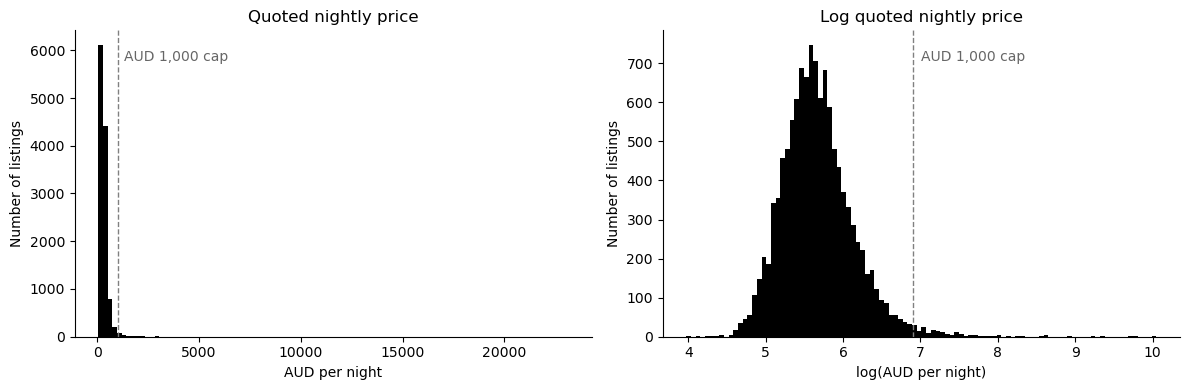

In [18]:
if listings_clean["price"].le(0).any():
    raise ValueError("Non-positive prices cannot be log transformed.")

listings_clean["log_price"] = np.log(listings_clean["price"])

print("Raw-price skewness:",
      round(stats.skew(listings_clean["price"]), 3))
print("Log-price skewness:",
      round(stats.skew(listings_clean["log_price"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

listings_clean["price"].hist(
    bins=100, ax=axes[0], color="black", grid=False
)
axes[0].set(
    title="Quoted nightly price",
    xlabel="AUD per night",
    ylabel="Number of listings"
)
axes[0].axvline(
    1000, color="0.5", linestyle="--", linewidth=1
)
axes[0].text(
    1300, axes[0].get_ylim()[1] * 0.9,
    "AUD 1,000 cap", color="0.4", fontsize=10
)

listings_clean["log_price"].hist(
    bins=100, ax=axes[1], color="black", grid=False
)
axes[1].set(
    title="Log quoted nightly price",
    xlabel="log(AUD per night)",
    ylabel="Number of listings"
)
axes[1].axvline(
    np.log(1000), color="0.5", linestyle="--", linewidth=1
)
axes[1].text(
    np.log(1000) + 0.1, axes[1].get_ylim()[1] * 0.9,
    "AUD 1,000 cap", color="0.4", fontsize=10
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

fig.savefig(
    DATA_DIR / "Figure1_price_distribution_BW.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [19]:
extreme_cap = listings_clean["price"].quantile(0.999)
df_full = listings_clean.loc[listings_clean["price"].le(extreme_cap)].copy()
df_trim = listings_clean.loc[listings_clean["price"].le(1000)].copy()

print(f"Extreme 99.9% cap: ${extreme_cap:,.2f}")
print(f"Mainstream sample: {len(df_trim):,}")
print(f"Luxury-inclusive sample: {len(df_full):,}")
print(f"Genuine luxury observations retained only in df_full: {len(df_full) - len(df_trim):,}")


Extreme 99.9% cap: $5,486.57
Mainstream sample: 11,545
Luxury-inclusive sample: 11,714
Genuine luxury observations retained only in df_full: 169


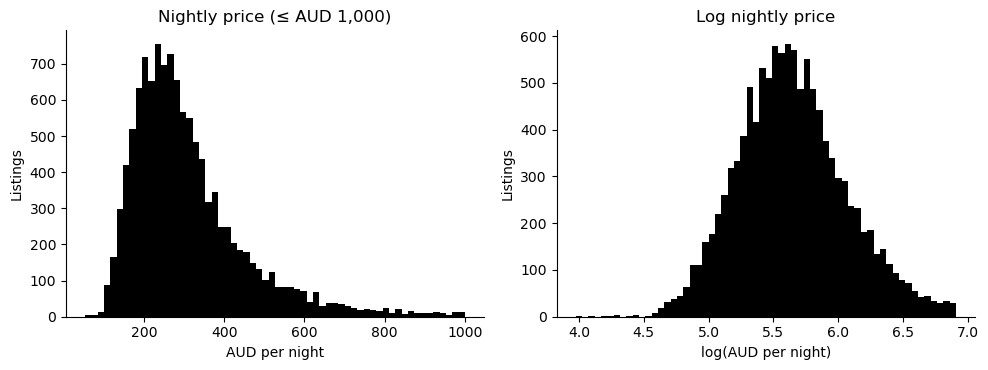

In [20]:
fig_dir = DATA_DIR / "Testing" / "comprehensive_analysis"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

df_trim["price"].hist(
    bins=60, ax=axes[0], color="black", grid=False
)
axes[0].set(
    title="Nightly price (≤ AUD 1,000)",
    xlabel="AUD per night",
    ylabel="Listings"
)

df_trim["log_price"].hist(
    bins=60, ax=axes[1], color="black", grid=False
)
axes[1].set(
    title="Log nightly price",
    xlabel="log(AUD per night)",
    ylabel="Listings"
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    fig_dir / "price_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 8. Prepare amenities and regression controls

Amenities are parsed from JSON, normalised into consistent names and converted into binary indicators. Only amenities present in 5%–95% of the mainstream sample are tested; extremely rare indicators produce unstable estimates and near-universal necessities provide too little comparison.

The models hold constant property capacity, physical characteristics, property type, suburb, CBD distance, minimum-stay policy, Superhost status and host portfolio size. This reduces observable confounding but does not turn amenity associations into causal effects.


In [21]:
AMENITY_RULES = [
    (r"hair dryer", "hair_dryer"),
    (r"dishwasher", "dishwasher"),
    (r"\bwasher\b|washing machine", "washer"),
    (r"\bdryer\b", "dryer"),
    (r"wifi", "wifi"),
    (r"\btv\b|hdtv", "tv"),
    (r"air conditioning", "air_conditioning"),
    (r"heating", "heating"),
    (r"hot tub", "hot_tub"),
    (r"sauna", "sauna"),
    (r"\bpool\b(?! table)", "pool"),
    (r"free .*parking", "free_parking"),
    (r"paid .*parking", "paid_parking"),
    (r"\bview\b", "view"),
    (r"shampoo|conditioner|body soap|shower gel", "toiletries"),
    (r"coffee maker|nespresso", "coffee_maker"),
    (r"indoor fireplace", "indoor_fireplace"),
    (r"smart lock|keypad", "smart_entry"),
]

def parse_amenity_list(value):
    if not isinstance(value, str):
        return []
    try:
        parsed = json.loads(value)
    except (TypeError, json.JSONDecodeError):
        return []
    return [str(item).lower().strip() for item in parsed] if isinstance(parsed, list) else []

def normalise_amenity(value):
    for pattern, label in AMENITY_RULES:
        if re.search(pattern, value):
            return label
    return re.sub(r"\W+", "_", value).strip("_")

model_df = df_trim.copy()
model_df["amenity_list"] = model_df["amenities"].map(parse_amenity_list)
model_df["amenity_normalised"] = model_df["amenity_list"].map(
    lambda values: sorted({normalise_amenity(value) for value in values if value})
)

amenity_dummies = model_df["amenity_normalised"].str.join("|").str.get_dummies()
# Remove indicators that are exact duplicates after normalisation.
amenity_dummies = amenity_dummies.T.drop_duplicates().T
amenity_share = amenity_dummies.mean()
amenities_kept = amenity_share[(amenity_share >= 0.05) & (amenity_share <= 0.95)].index
amenity_dummies = amenity_dummies[amenities_kept].add_prefix("a_")
model_df = model_df.join(amenity_dummies)

model_df["amenity_count"] = model_df["amenity_normalised"].str.len()
model_df["is_superhost"] = model_df["host_is_superhost"].eq("t").astype(int)

top_property_types = model_df["property_type"].value_counts().head(15).index
model_df["property_type_model"] = model_df["property_type"].where(
    model_df["property_type"].isin(top_property_types),
    "Other",
)

def haversine_km(lat, lon, ref_lat=-37.8136, ref_lon=144.9631):
    lat1 = np.radians(pd.to_numeric(lat, errors="coerce"))
    lon1 = np.radians(pd.to_numeric(lon, errors="coerce"))
    lat2 = np.radians(ref_lat)
    lon2 = np.radians(ref_lon)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))

model_df["distance_to_cbd_km"] = haversine_km(
    model_df["latitude"], model_df["longitude"]
)

amenity_terms = amenity_dummies.columns.tolist()
print(f"Amenity indicators tested: {len(amenity_terms)}")
print(model_df[["amenity_count", "distance_to_cbd_km", "is_superhost"]].describe().round(2))


Amenity indicators tested: 90
       amenity_count  distance_to_cbd_km  is_superhost
count       11545.00            11545.00      11545.00
mean           40.71               10.28          0.49
std            11.95               14.55          0.50
min             0.00                0.02          0.00
25%            34.00                1.06          0.00
50%            41.00                3.84          0.00
75%            48.00               13.08          1.00
max            85.00               79.81          1.00


## 9. Controlled log-price regression

The first model estimates the association between each amenity and quoted nightly price while holding the included property, location and host characteristics constant. Standard errors are clustered by host because several listings can share the same operator. Benjamini–Hochberg false-discovery-rate correction is applied because many amenities are tested simultaneously.


In [22]:
numeric_control_candidates = [
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_n",
    "bathroom_shared",
    "bedrooms_missing",
    "beds_missing",
    "bathrooms_missing",
    "distance_to_cbd_km",
    "minimum_nights_missing",
    "is_superhost",
]

# Constant controls provide no information after the scope filters, so omit them.
numeric_controls = [
    column for column in numeric_control_candidates
    if model_df[column].nunique(dropna=True) > 1
]
control_terms = numeric_controls + [
    "C(property_type_model)",
    "C(suburb)",
    "np.log1p(minimum_nights)",
    "np.log1p(calculated_host_listings_count)",
]

rhs = " + ".join(amenity_terms + control_terms)
price_formula = "log_price ~ " + rhs

# Use an explicit complete-case frame so cluster labels and model rows align clearly.
required_for_models = [
    "log_price", "host_cluster_id", "accommodates", "bedrooms", "beds",
    "bathrooms_n", "property_type_model", "suburb", "distance_to_cbd_km",
    "minimum_nights", "is_superhost", "calculated_host_listings_count",
] + amenity_terms
price_data = model_df.dropna(subset=required_for_models).copy()
price_model = smf.ols(price_formula, data=price_data).fit(
    cov_type="cluster",
    cov_kwds={"groups": price_data["host_cluster_id"]},
)

price_results = pd.DataFrame({
    "coefficient": price_model.params[amenity_terms],
    "p_value": price_model.pvalues[amenity_terms],
})
price_results["price_premium_pct"] = (
    np.exp(price_results["coefficient"]) - 1
) * 100
price_results["q_value_BH"] = multipletests(
    price_results["p_value"], method="fdr_bh"
)[1]

display(price_results.sort_values("price_premium_pct", ascending=False).round(3).head(25))
print("Observations:", int(price_model.nobs))
print("R-squared:", round(price_model.rsquared, 3))


,coefficient,p_value,price_premium_pct,q_value_BH
a_smart_entry,0.122,0.015,12.945,0.065
a_lockbox,0.099,0.047,10.378,0.141
a_dishwasher,0.081,0.000,8.451,0.000
a_indoor_fireplace,0.069,0.000,7.152,0.000
a_bathtub,0.055,0.000,5.612,0.000
a_bbq_grill,0.038,0.000,3.922,0.002
a_sun_loungers,0.037,0.007,3.790,0.035
a_coffee_maker,0.037,0.000,3.771,0.003
a_dryer,0.037,0.000,3.730,0.002
a_patio_or_balcony,0.037,0.004,3.719,0.029


Observations: 11545
R-squared: 0.596


### How to interpret the price model

For a binary amenity coefficient $\beta$, the adjusted percentage difference is:

$$100\times(\exp(\beta)-1).$$

For example, a coefficient of 0.08 corresponds to approximately an 8.3% higher quoted nightly price, conditional on the included controls. Use the FDR-adjusted `q_value_BH` rather than selecting amenities solely from uncorrected p-values.

The wording must remain **associated with**, not **caused by**. A pool, for example, may identify larger or better-managed properties even after observable controls are included.


## 10. Revenue-proxy decomposition and robustness regression

The review-based revenue proxy is:

$$\text{Revenue proxy}=\text{quoted nightly price}\times\text{review-derived occupied nights}.$$

For positive values:

$$\log(\text{revenue proxy})=\log(\text{price})+\log(\text{occupied nights}).$$

Using identical rows and controls allows each amenity's revenue association to be decomposed into a price channel and an occupied-night channel. Inside Airbnb's `estimated_revenue_l365d` is modelled separately as a robustness outcome; it is still an estimate rather than actual host income.


In [23]:
model_df["log_review_occupied_nights"] = np.log(model_df["review_occupied_nights"])
model_df["log_review_revenue_proxy"] = np.log(model_df["review_revenue_proxy"])
model_df["log_inside_airbnb_revenue"] = np.log(
    pd.to_numeric(model_df["estimated_revenue_l365d"], errors="coerce")
)

outcomes = {
    "Price": "log_price",
    "Occupied nights proxy": "log_review_occupied_nights",
    "Revenue proxy": "log_review_revenue_proxy",
    "Inside Airbnb estimated revenue": "log_inside_airbnb_revenue",
}

common_required = required_for_models + list(outcomes.values())
regression_data = model_df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=common_required
).copy()

component_results = {}
for label, outcome in outcomes.items():
    fitted = smf.ols(f"{outcome} ~ {rhs}", data=regression_data).fit(
        cov_type="cluster",
        cov_kwds={"groups": regression_data["host_cluster_id"]},
    )
    table = pd.DataFrame({
        "coefficient": fitted.params[amenity_terms],
        "p_value": fitted.pvalues[amenity_terms],
    })
    table["effect_pct"] = (np.exp(table["coefficient"]) - 1) * 100
    table["q_value_BH"] = multipletests(table["p_value"], method="fdr_bh")[1]
    component_results[label] = table

amenity_comparison = pd.concat(
    {
        label: table[["effect_pct", "q_value_BH"]]
        for label, table in component_results.items()
    },
    axis=1,
)

display(
    amenity_comparison
    .sort_values(("Revenue proxy", "effect_pct"), ascending=False)
    .round(3)
    .head(25)
)


Price            Occupied nights proxy  \
                                effect_pct q_value_BH            effect_pct   
a_smart_entry                       12.945      0.065                37.289   
a_lockbox                           10.378      0.141                36.205   
a_stainless_steel_oven               0.048      0.984                20.625   
a_view                               2.583      0.025                15.179   
a_microwave                         -4.470      0.051                20.518   
a_hair_dryer                        -1.017      0.645                15.833   
a_single_level_home                  0.894      0.662                12.649   
a_dishwasher                         8.451      0.000                 3.637   
a_indoor_fireplace                   7.152      0.000                 4.881   
a_ac_split_type_ductless_system      0.770      0.745                10.265   
a_hot_water                         -4.231      0.035                14.598   
a_portable_heater                   -3.128      0.123                12.999   
a_dryer                              3.730      0.002                 5.237   
a_toiletries                         1.766      0.473                 7.094   
a_essentials                        -0.095      0.969                 8.961   
a_shared_gym_in_building             0.100      0.975                 8.655   
a_children_s_books_and_toys         -2.853      0.097                10.761   
a_air_conditioning                  -0.329      0.892                 7.640   
a_coffee                            -0.091      0.973                 7.227   
a_outdoor_dining_area                2.735      0.005                 4.258   
a_hangers                           -4.118      0.009                11.613   
a_free_parking                       1.689      0.246                 4.170   
a_extra_pillows_and_blankets        -0.714      0.731                 6.444   
a_dishes_and_silverware             -2.411      0.411                 8.249   
a_clothing_storage                  -1.213      0.411                 6.323   

                                           Revenue proxy             \
                                q_value_BH    effect_pct q_value_BH   
a_smart_entry                        0.181        55.061      0.044   
a_lockbox                            0.181        50.340      0.053   
a_stainless_steel_oven               0.004        20.683      0.001   
a_view                               0.001        18.154      0.000   
a_microwave                          0.016        15.130      0.053   
a_hair_dryer                         0.015        14.654      0.012   
a_single_level_home                  0.021        13.656      0.006   
a_dishwasher                         0.544        12.395      0.006   
a_indoor_fireplace                   0.544        12.381      0.058   
a_ac_split_type_ductless_system      0.117        11.113      0.055   
a_hot_water                          0.181         9.749      0.366   
a_portable_heater                    0.146         9.464      0.304   
a_dryer                              0.360         9.163      0.026   
a_toiletries                         0.522         8.985      0.358   
a_essentials                         0.071         8.857      0.049   
a_shared_gym_in_building             0.365         8.764      0.304   
a_children_s_books_and_toys          0.141         7.600      0.304   
a_air_conditioning                   0.224         7.285      0.236   
a_coffee                             0.260         7.130      0.222   
a_outdoor_dining_area                0.438         7.110      0.107   
a_hangers                            0.093         7.017      0.358   
a_free_parking                       0.542         5.929      0.304   
a_extra_pillows_and_blankets         0.412         5.684      0.388   
a_dishes_and_silverware              0.412         5.639      0.590   
a_clothing_storage                   0.285         5.033 

In [24]:
# Numerical check of the exact log decomposition on the common analysis rows.
decomposition_error = (
    regression_data["log_review_revenue_proxy"]
    - regression_data["log_price"]
    - regression_data["log_review_occupied_nights"]
).abs().max()

print("Maximum row-level log decomposition error:", decomposition_error)
print("Common regression observations:", len(regression_data))

# Amenities that remain significant after FDR correction in the revenue-proxy model.
significant_revenue_amenities = component_results["Revenue proxy"].query(
    "q_value_BH < 0.05"
).sort_values("effect_pct", ascending=False)
display(significant_revenue_amenities.round(3))


Maximum row-level log decomposition error: 1.7763568394002505e-15
Common regression observations: 11545


,coefficient,p_value,effect_pct,q_value_BH
a_smart_entry,0.439,0.004,55.061,0.044
a_stainless_steel_oven,0.188,0.000,20.683,0.001
a_view,0.167,0.000,18.154,0.000
a_hair_dryer,0.137,0.001,14.654,0.012
a_single_level_home,0.128,0.000,13.656,0.006
a_dishwasher,0.117,0.000,12.395,0.006
a_dryer,0.088,0.002,9.163,0.026
a_essentials,0.085,0.006,8.857,0.049
a_first_aid_kit,-0.094,0.002,-8.990,0.026
a_backyard,-0.105,0.005,-10.008,0.045


## 11. Evidence-supported suburb × property-format revenue analysis

The current business question is: **which Melbourne suburb and investable property format are associated with the highest estimated annual Airbnb revenue?**

This section replaces the earlier sequential selection and hard-coded multipliers with one supported-combination model. Airbnb's `room_type` identifies whether the guest receives the whole space; it is not a physical building classification. The host-reported `property_type` is therefore translated into transparent client-facing formats while the original value is retained.

An exact suburb × format combination enters the model only when it has at least 10 listings from at least 8 hosts. A primary recommendation additionally requires at least 20 listings, at least 10 hosts, a positive cluster-robust confidence interval and an FDR-adjusted q-value below 0.05. Combinations below these thresholds may still represent low-competition opportunities, but they are reported as exploratory rather than evidence-supported.

The model compares a standard prospective-host scenario: four guests, two bedrooms, one bathroom, a two-night minimum, a new non-Superhost and one host listing. This supports like-for-like comparisons. It does not assert that every property has this configuration.

In [25]:
# Create transparent client-facing property formats from Airbnb's host-reported label.
HOUSE_LIKE_TYPES = {
    "entire home", "entire cottage", "entire villa", "entire bungalow",
    "entire vacation home",
}
UNIT_LIKE_TYPES = {
    "entire rental unit", "entire condo", "entire serviced apartment",
    "entire loft",
}
GUESTHOUSE_TYPES = {"entire guesthouse", "entire guest suite"}

def client_property_format(value):
    label = str(value).strip().casefold()
    if label in HOUSE_LIKE_TYPES:
        return "Whole house"
    if label in UNIT_LIKE_TYPES:
        return "Whole apartment/unit"
    if label == "entire townhouse":
        return "Whole townhouse"
    if label in GUESTHOUSE_TYPES:
        return "Whole guesthouse/secondary dwelling"
    return "Specialty/other accommodation"

recommendation_data = regression_data.copy()
recommendation_data["client_property_format"] = recommendation_data[
    "property_type"
].map(client_property_format)
recommendation_data["log_revenue"] = np.log(
    pd.to_numeric(recommendation_data["estimated_revenue_l365d"], errors="coerce")
)

recommendation_required = [
    "id", "host_cluster_id", "suburb", "client_property_format",
    "estimated_revenue_l365d", "log_revenue", "accommodates", "bedrooms",
    "bathrooms_n", "minimum_nights", "minimum_nights_missing",
    "is_superhost", "calculated_host_listings_count",
]
recommendation_data = recommendation_data.dropna(
    subset=recommendation_required
).copy()
recommendation_data = recommendation_data.loc[
    recommendation_data["estimated_revenue_l365d"].gt(0)
].copy()

recommendation_data["suburb_property_combination"] = (
    recommendation_data["suburb"].astype(str)
    + " | "
    + recommendation_data["client_property_format"].astype(str)
)

combination_support = (
    recommendation_data.groupby(
        ["suburb", "client_property_format", "suburb_property_combination"],
        observed=True,
    )
    .agg(
        listings=("id", "size"),
        unique_hosts=("host_cluster_id", "nunique"),
        median_estimated_revenue_aud=("estimated_revenue_l365d", "median"),
        mean_estimated_revenue_aud=("estimated_revenue_l365d", "mean"),
        median_bedrooms=("bedrooms", "median"),
        median_bathrooms=("bathrooms_n", "median"),
    )
    .reset_index()
)

MIN_MODEL_LISTINGS = 10
MIN_MODEL_HOSTS = 8
STRONG_LISTINGS = 20
STRONG_HOSTS = 10
PRIMARY_PROPERTY_FORMATS = {
    "Whole house",
    "Whole apartment/unit",
    "Whole townhouse",
    "Whole guesthouse/secondary dwelling",
}

supported_combinations = combination_support.loc[
    combination_support["client_property_format"].isin(PRIMARY_PROPERTY_FORMATS)
    & combination_support["listings"].ge(MIN_MODEL_LISTINGS)
    & combination_support["unique_hosts"].ge(MIN_MODEL_HOSTS)
].copy()
supported_labels = sorted(
    supported_combinations["suburb_property_combination"].unique()
)
if not supported_labels:
    raise ValueError("No suburb × property-format combinations meet the support rules.")

recommendation_data["combination_model"] = np.where(
    recommendation_data["suburb_property_combination"].isin(supported_labels),
    recommendation_data["suburb_property_combination"],
    "Other combinations",
)
combination_levels = ["Other combinations"] + supported_labels
recommendation_data["combination_model"] = pd.Categorical(
    recommendation_data["combination_model"],
    categories=combination_levels,
)

print(f"Recommendation-model observations: {len(recommendation_data):,}")
print(f"Supported exact combinations: {len(supported_labels):,}")
display(
    supported_combinations.sort_values(
        ["listings", "unique_hosts"], ascending=False
    ).head(15)
)

Recommendation-model observations: 11,545
Supported exact combinations: 157


,suburb,client_property_format,suburb_property_combination,listings,unique_hosts,median_estimated_revenue_aud,mean_estimated_revenue_aud,median_bedrooms,median_bathrooms
597,Melbourne,Whole apartment/unit,Melbourne | Whole apartment/unit,2657,1006,25608.0,32952.333082,2.0,1.0
840,Southbank,Whole apartment/unit,Southbank | Whole apartment/unit,973,419,23100.0,30115.603289,2.0,1.0
311,Docklands,Whole apartment/unit,Docklands | Whole apartment/unit,537,286,24525.0,32629.204842,2.0,1.0
852,St Kilda,Whole apartment/unit,St Kilda | Whole apartment/unit,354,274,15480.0,19654.483051,1.0,1.0
836,South Yarra,Whole apartment/unit,South Yarra | Whole apartment/unit,290,190,15049.5,19471.896552,1.0,1.0
185,Carlton,Whole apartment/unit,Carlton | Whole apartment/unit,273,122,10200.0,20389.967033,1.0,1.0
769,Richmond,Whole apartment/unit,Richmond | Whole apartment/unit,167,129,22176.0,26394.892216,1.0,1.0
380,Fitzroy,Whole apartment/unit,Fitzroy | Whole apartment/unit,113,82,33099.0,36083.097345,1.0,1.0
261,Collingwood,Whole apartment/unit,Collingwood | Whole apartment/unit,110,76,35277.0,40244.600000,2.0,1.0
115,Box Hill,Whole apartment/unit,Box Hill | Whole apartment/unit,109,60,10848.0,14151.339450,2.0,2.0


### Fix the comparison design before fitting

Define the candidate log-revenue specification and reserve the same 20 percent of hosts for all models before fitting. All listings from a host stay together. The next cells compare log-linear regression, random forest and histogram gradient boosting using training-only preparation and host-grouped tuning. No final suburb recommendation is selected at this stage.

In [26]:
combination_term = (
    'C(combination_model, Treatment(reference="Other combinations"))'
)
recommendation_formula = (
    "log_revenue ~ "
    + combination_term
    + " + np.log1p(accommodates)"
    + " + bedrooms"
    + " + bathrooms_n"
    + " + np.log1p(minimum_nights)"
    + " + minimum_nights_missing"
    + " + is_superhost"
    + " + np.log1p(calculated_host_listings_count)"
)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=30005)
train_index, test_index = next(
    splitter.split(
        recommendation_data,
        groups=recommendation_data["host_cluster_id"],
    )
)
recommendation_train = recommendation_data.iloc[train_index].copy()
recommendation_test = recommendation_data.iloc[test_index].copy()

assert set(recommendation_train["host_cluster_id"]).isdisjoint(set(recommendation_test["host_cluster_id"]))
print("Validation design fixed before model fitting: 20% of hosts reserved for the final test.")

Validation design fixed before model fitting: 20% of hosts reserved for the final test.


### Revenue model comparison with random forest and gradient boosting

**Business question:** can more flexible models improve prediction enough to justify changing our explainable revenue-comparison approach?

We compare three models on the **same current recommendation cohort and the same held-out hosts**. This section is self-contained: it does not import another notebook or a project Python script. It requires scikit-learn. The outcome is Inside Airbnb's supplied **estimated annual gross revenue**, not observed bookings or profit. No review counts, nightly prices, occupancy, acquisition prices or other revenue measures are supplied as predictors.

| Model | Dependent variable | Independent variables | Role |
| --- | --- | --- | --- |
| Log-linear regression | Log of estimated_revenue_l365d | Suburb by property format, guest capacity, bedrooms, bathrooms, minimum nights, missing-minimum indicator, Superhost status and host listing count | Explainable benchmark |
| Random forest | Same log revenue target | Same recorded inputs | Nonlinear challenger averaging decision trees |
| Histogram gradient boosting | Same log revenue target | Same recorded inputs | Nonlinear challenger fitting successive trees |

Training-only feature preparation is used for all three benchmark models. Consequently the benchmark regression can differ slightly from the original regression fitted above, which prepared some controls and support groups before splitting. Its original validation is shown separately for reference. The original clustered regression, confidence intervals and investment rules are not overwritten.

**Reading the raw missing-value audit below:** These are original values before the benchmark pipeline fills them, not missing values left in the earlier cleaned dataset. We keep the same eligible listing IDs but reload the raw numeric inputs so their replacement values can be learned from training observations only. No numeric missing values are passed to the fitted estimators.


In [27]:
from pathlib import Path
import hashlib
import json
import platform
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import __version__ as sklearn_version
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

revenue_comparison_SEED = 30005
revenue_comparison_CV_FOLDS = 3
revenue_comparison_BOOTSTRAP_REPEATS = 1000
revenue_comparison_TREE_THREADS = 2
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
pd.set_option("display.max_colwidth", 65)
pd.set_option("display.max_columns", 15)
revenue_comparison_WORKING_DIR = Path.cwd()
revenue_comparison_REQUIRED = ["listings_airbnb.csv", "listings_with_property_price_benchmarks.csv"]
revenue_comparison_DATA_DIR = next(
    (
        p
        for p in [revenue_comparison_WORKING_DIR, revenue_comparison_WORKING_DIR.parent]
        if all(
            (
                (p / revenue_comparison_name).exists()
                for revenue_comparison_name in revenue_comparison_REQUIRED
            )
        )
    ),
    None,
)
if revenue_comparison_DATA_DIR is None:
    raise FileNotFoundError(
        "Place both required CSV files beside the notebook or in its parent: "
        + ", ".join(revenue_comparison_REQUIRED)
    )
revenue_comparison_OUTPUT_DIR = (
    revenue_comparison_DATA_DIR / "Testing" / "comprehensive_analysis" / "revenue_model_comparison"
)
revenue_comparison_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Benchmark target: estimated_revenue_l365d (modelled annual gross revenue).")
print("Required CSV files found. sklearn version:", sklearn_version)

Benchmark target: estimated_revenue_l365d (modelled annual gross revenue).
Required CSV files found. sklearn version: 1.7.2


In [28]:
revenue_comparison_benchmark_columns = [
    "id",
    "suburb",
    "price",
    "estimated_revenue_l365d",
    "room_type",
    "number_of_reviews_ltm",
    "long_stay_only",
    "bedrooms_benchmark",
    "dwelling_class",
    "bedroom_adjusted_acquisition_price_proxy_aud",
]
revenue_comparison_benchmark = pd.read_csv(
    revenue_comparison_DATA_DIR / revenue_comparison_REQUIRED[1],
    usecols=revenue_comparison_benchmark_columns,
    dtype={"id": "string"},
    low_memory=False,
)
assert revenue_comparison_benchmark["id"].is_unique, "Duplicate benchmark listing IDs."
for revenue_comparison_column in [
    "price",
    "estimated_revenue_l365d",
    "number_of_reviews_ltm",
    "bedrooms_benchmark",
    "bedroom_adjusted_acquisition_price_proxy_aud",
]:
    revenue_comparison_benchmark[revenue_comparison_column] = pd.to_numeric(
        revenue_comparison_benchmark[revenue_comparison_column], errors="coerce"
    )
revenue_comparison_long_only = (
    revenue_comparison_benchmark["long_stay_only"].astype(str).str.lower().isin(["true", "1"])
)
revenue_comparison_eligible = revenue_comparison_benchmark.loc[
    revenue_comparison_benchmark["price"].gt(0)
    & revenue_comparison_benchmark["price"].le(1000)
    & revenue_comparison_benchmark["estimated_revenue_l365d"].gt(0)
    & revenue_comparison_benchmark["room_type"].eq("Entire home/apt")
    & revenue_comparison_benchmark["number_of_reviews_ltm"].gt(0)
    & ~revenue_comparison_long_only
    & revenue_comparison_benchmark["suburb"].notna()
].copy()
revenue_comparison_raw_columns = [
    "id",
    "host_id",
    "property_type",
    "accommodates",
    "bedrooms",
    "bathrooms_text",
    "minimum_nights",
    "host_is_superhost",
    "calculated_host_listings_count",
]
revenue_comparison_raw = pd.read_csv(
    revenue_comparison_DATA_DIR / revenue_comparison_REQUIRED[0],
    usecols=revenue_comparison_raw_columns,
    dtype={"id": "string", "host_id": "string"},
    low_memory=False,
)
assert revenue_comparison_raw["id"].is_unique, "Duplicate raw listing IDs."
revenue_comparison_data = revenue_comparison_eligible[
    ["id", "suburb", "estimated_revenue_l365d"]
].merge(revenue_comparison_raw, on="id", how="left", validate="one_to_one")
assert (
    revenue_comparison_data["property_type"].notna().all()
), "Some cached IDs have no raw listing."
revenue_comparison_data["suburb"] = revenue_comparison_data["suburb"].str.title()
revenue_comparison_data["host_cluster_id"] = revenue_comparison_data["host_id"].fillna(
    "missing_host_" + revenue_comparison_data["id"]
)
revenue_comparison_HOUSE_TYPES = {
    "entire home",
    "entire cottage",
    "entire villa",
    "entire bungalow",
    "entire vacation home",
}
revenue_comparison_UNIT_TYPES = {
    "entire rental unit",
    "entire condo",
    "entire serviced apartment",
    "entire loft",
}


def revenue_comparison_property_format(revenue_comparison_value):
    label = str(revenue_comparison_value).strip().casefold()
    if label in revenue_comparison_HOUSE_TYPES:
        return "Whole house"
    if label in revenue_comparison_UNIT_TYPES:
        return "Whole apartment/unit"
    if label == "entire townhouse":
        return "Whole townhouse"
    if label in {"entire guesthouse", "entire guest suite"}:
        return "Whole guesthouse/secondary dwelling"
    return "Specialty/other accommodation"


def revenue_comparison_bathrooms(revenue_comparison_value):
    if pd.isna(revenue_comparison_value):
        return np.nan
    text = str(revenue_comparison_value).lower()
    if "half" in text and (not re.search("\\d", text)):
        return 0.5
    match = re.search("\\d+(?:\\.\\d+)?", text)
    return float(match.group()) if match else np.nan


revenue_comparison_data["client_property_format"] = revenue_comparison_data["property_type"].map(
    revenue_comparison_property_format
)
revenue_comparison_data["suburb_property_combination"] = (
    revenue_comparison_data["suburb"] + " | " + revenue_comparison_data["client_property_format"]
)
revenue_comparison_data["bathrooms_n"] = revenue_comparison_data["bathrooms_text"].map(
    revenue_comparison_bathrooms
)
revenue_comparison_data["is_superhost"] = (
    revenue_comparison_data["host_is_superhost"].eq("t").astype(int)
)
revenue_comparison_data["minimum_nights_missing"] = (
    revenue_comparison_data["minimum_nights"].isna().astype(int)
)
for revenue_comparison_column in [
    "accommodates",
    "bedrooms",
    "bathrooms_n",
    "minimum_nights",
    "calculated_host_listings_count",
]:
    revenue_comparison_data[revenue_comparison_column] = pd.to_numeric(
        revenue_comparison_data[revenue_comparison_column], errors="coerce"
    )
revenue_comparison_data = revenue_comparison_data.reset_index(drop=True)
revenue_comparison_current_ids = recommendation_data["id"].astype("string")
assert revenue_comparison_current_ids.is_unique
assert set(revenue_comparison_data["id"].astype(str)) == set(
    revenue_comparison_current_ids.astype(str)
), "The benchmark CSV and current recommendation cohort differ. Regenerate the benchmark inputs before comparing models."
revenue_comparison_data = (
    revenue_comparison_data.set_index("id").loc[revenue_comparison_current_ids].reset_index()
)
revenue_comparison_data["host_cluster_id"] = revenue_comparison_data["host_cluster_id"].astype(
    "string"
)
assert (
    revenue_comparison_data["host_cluster_id"].astype(str).tolist()
    == recommendation_data["host_cluster_id"].astype(str).tolist()
)
assert np.isfinite(revenue_comparison_data["estimated_revenue_l365d"]).all()
assert revenue_comparison_data["id"].is_unique
revenue_comparison_FEATURES = [
    "suburb_property_combination",
    "accommodates",
    "bedrooms",
    "bathrooms_n",
    "minimum_nights",
    "minimum_nights_missing",
    "is_superhost",
    "calculated_host_listings_count",
]
revenue_comparison_X = revenue_comparison_data[revenue_comparison_FEATURES].copy()
revenue_comparison_y = revenue_comparison_data["estimated_revenue_l365d"].astype(float)
revenue_comparison_groups = revenue_comparison_data["host_cluster_id"].astype(str)
assert not any(
    (
        "revenue" in c or "review" in c or "price" in c or ("occupancy" in c)
        for c in revenue_comparison_FEATURES
    )
)
display(
    pd.DataFrame(
        {
            "metric": [
                "Analysis listings",
                "Unique hosts",
                "Suburbs",
                "Missing raw bedrooms",
                "Missing raw bathrooms",
                "Missing raw minimum nights",
            ],
            "value": [
                len(revenue_comparison_data),
                revenue_comparison_groups.nunique(),
                revenue_comparison_data["suburb"].nunique(),
                revenue_comparison_X["bedrooms"].isna().sum(),
                revenue_comparison_X["bathrooms_n"].isna().sum(),
                revenue_comparison_X["minimum_nights"].isna().sum(),
            ],
        }
    )
)
print("Cohort and host IDs match the current comprehensive analysis exactly.")
if len(revenue_comparison_data) != 11545:
    print(
        "Sample differs from that snapshot. Interpret this as a comparison on the current inputs."
    )

,metric,value
0,Analysis listings,11545
1,Unique hosts,5596
2,Suburbs,415
3,Missing raw bedrooms,282
4,Missing raw bathrooms,1
5,Missing raw minimum nights,9


Cohort and host IDs match the current comprehensive analysis exactly.


#### Training only preparation and model definitions

The same eight inputs enter each model. Guest capacity, minimum nights and host listing count use log1p transformations, matching the original regression specification. Within each training fold, combinations with fewer than 10 listings or 8 hosts are pooled into Other combinations; missing numeric values are filled using training observations only. This revenue-combination rule is separate from the 20-listing suburb pooling used later in the guest-rating model.

All three fit log revenue and use a model-specific training-residual smearing factor to return predictions to dollars. This common back-transformation is an approximation; the dollar-error metrics assess its predictions. The random forest and histogram boosting models use the same limited tuning grids as the previous standalone benchmark.

**Why fill the missing values again:** The earlier cleaning filled bedrooms, bathrooms and minimum nights using the full cleaned sample. For this prediction benchmark, reusing those replacements would allow held-out records to influence the training preparation. Each training fold therefore learns its own capacity-group bedroom/bathroom medians and fallback medians; those fixed values are then applied to that fold's validation records. The final outer-training pipeline similarly fills the held-out test records using outer-training medians only. Information flows from training to validation/test, not from the held-out data into the fitted imputation rule. The existing one-bedroom rule for missing bedrooms in properties accommodating at most two guests is deterministic and is retained. This safeguard does not mean that no other analysis in the notebook uses full-sample preparation.


In [29]:
revenue_comparison_NUMERIC_FEATURES = [
    "log_accommodates",
    "bedrooms",
    "bathrooms_n",
    "log_minimum_nights",
    "minimum_nights_missing",
    "is_superhost",
    "log_host_listings",
]


class revenue_comparison_PrepareRevenueFeatures(TransformerMixin, BaseEstimator):

    def fit(self, frame, target=None):
        frame = frame.copy()
        host_ids = revenue_comparison_groups.loc[frame.index]
        revenue_comparison_support = (
            pd.DataFrame({"combination": frame["suburb_property_combination"], "host": host_ids})
            .groupby("combination")
            .agg(rows=("host", "size"), hosts=("host", "nunique"))
        )
        self.supported_ = set(
            revenue_comparison_support.index[
                (revenue_comparison_support["rows"] >= 10)
                & (revenue_comparison_support["hosts"] >= 8)
            ]
        )
        self.supported_ = {
            label
            for label in self.supported_
            if not label.endswith("Specialty/other accommodation")
        }
        self.categories_ = ["Other combinations"] + sorted(self.supported_)
        frame.loc[frame["bedrooms"].isna() & frame["accommodates"].le(2), "bedrooms"] = 1
        self.group_medians_ = {
            c: frame.groupby("accommodates")[c].median() for c in ["bedrooms", "bathrooms_n"]
        }
        self.medians_ = {
            c: float(frame[c].median())
            for c in [
                "accommodates",
                "bedrooms",
                "bathrooms_n",
                "minimum_nights",
                "calculated_host_listings_count",
            ]
        }
        if not np.isfinite(list(self.medians_.values())).all():
            raise ValueError("A training input has no usable median.")
        return self

    def transform(self, frame):
        frame = frame.copy()
        frame["combination_model"] = frame["suburb_property_combination"].where(
            frame["suburb_property_combination"].isin(self.supported_), "Other combinations"
        )
        frame.loc[frame["bedrooms"].isna() & frame["accommodates"].le(2), "bedrooms"] = 1
        for c in ["bedrooms", "bathrooms_n"]:
            frame[c] = frame[c].fillna(frame["accommodates"].map(self.group_medians_[c]))
        for c, median in self.medians_.items():
            frame[c] = frame[c].fillna(median)
        frame["log_accommodates"] = np.log1p(frame["accommodates"])
        frame["log_minimum_nights"] = np.log1p(frame["minimum_nights"])
        frame["log_host_listings"] = np.log1p(frame["calculated_host_listings_count"])
        prepared = frame[["combination_model"] + revenue_comparison_NUMERIC_FEATURES]
        assert np.isfinite(
            prepared[revenue_comparison_NUMERIC_FEATURES].to_numpy(dtype=float)
        ).all()
        return prepared


class revenue_comparison_EncodeRevenueFeatures(TransformerMixin, BaseEstimator):

    def fit(self, frame, target=None):
        categories = ["Other combinations"] + sorted(
            set(frame["combination_model"]) - {"Other combinations"}
        )
        self.encoder_ = OneHotEncoder(
            categories=[categories], drop="first", handle_unknown="ignore", sparse_output=False
        )
        self.encoder_.fit(frame[["combination_model"]])
        return self

    def transform(self, frame):
        encoded = self.encoder_.transform(frame[["combination_model"]])
        return np.column_stack(
            [encoded, frame[revenue_comparison_NUMERIC_FEATURES].to_numpy(dtype=float)]
        )


class revenue_comparison_LogRevenueRegressor(RegressorMixin, BaseEstimator):

    def __init__(self, regressor=None):
        self.regressor = regressor

    def fit(self, frame, target):
        target = np.asarray(target, dtype=float)
        assert (target > 0).all() and np.isfinite(target).all()
        self.pipeline_ = Pipeline(
            [
                ("prepare", revenue_comparison_PrepareRevenueFeatures()),
                ("encode", revenue_comparison_EncodeRevenueFeatures()),
                ("regressor", clone(self.regressor)),
            ]
        )
        self.pipeline_.fit(frame, np.log(target))
        residual = np.log(target) - self.pipeline_.predict(frame)
        self.smearing_ = float(np.mean(np.exp(residual)))
        return self

    def predict_log(self, frame):
        revenue_comparison_prediction = self.pipeline_.predict(frame)
        assert np.isfinite(revenue_comparison_prediction).all(), "Non-finite model prediction."
        return revenue_comparison_prediction

    def predict(self, frame):
        revenue_comparison_prediction = np.exp(self.predict_log(frame)) * self.smearing_
        assert np.isfinite(revenue_comparison_prediction).all(), "Non-finite dollar prediction."
        return revenue_comparison_prediction


def revenue_comparison_score_mae(revenue_comparison_estimator, frame, target):
    return -mean_absolute_error(target, revenue_comparison_estimator.predict(frame))


def revenue_comparison_score_rmse(revenue_comparison_estimator, frame, target):
    return -float(np.sqrt(mean_squared_error(target, revenue_comparison_estimator.predict(frame))))


def revenue_comparison_score_log_r2(revenue_comparison_estimator, frame, target):
    return r2_score(np.log(target), revenue_comparison_estimator.predict_log(frame))


revenue_comparison_SCORING = {
    "MAE_AUD": revenue_comparison_score_mae,
    "RMSE_AUD": revenue_comparison_score_rmse,
    "log_R2": revenue_comparison_score_log_r2,
}
revenue_comparison_MODEL_SPECS = {
    "Log-linear regression": (LinearRegression(), [{}]),
    "Random forest": (
        RandomForestRegressor(
            n_estimators=160,
            max_depth=16,
            random_state=revenue_comparison_SEED,
            n_jobs=revenue_comparison_TREE_THREADS,
        ),
        {"regressor__min_samples_leaf": [3, 10, 25], "regressor__max_features": [0.7, 1.0]},
    ),
    "Gradient boosting": (
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.08,
            min_samples_leaf=30,
            early_stopping=False,
            random_state=revenue_comparison_SEED,
        ),
        {"regressor__max_leaf_nodes": [7, 15, 31], "regressor__l2_regularization": [1.0, 10.0]},
    ),
}

#### Host grouped tuning and untouched test hosts

Reserve the same 20 percent of hosts as the main regression, with seed 30005. Tune only within the remaining hosts using three-fold GroupKFold validation. Six settings are tested for each challenger; training cross-validation dollar MAE selects settings and identifies the training-CV choice. Test outcomes are not used for tuning. Hosts never appear in both sides of a split.

This is a modest benchmark rather than an exhaustive search. Better prediction of a supplied revenue estimate does not validate that estimate's assumptions or prove higher actual returns.

In [30]:
revenue_comparison_outer = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=revenue_comparison_SEED
)
revenue_comparison_train_idx, revenue_comparison_test_idx = next(
    revenue_comparison_outer.split(revenue_comparison_X, groups=revenue_comparison_groups)
)
revenue_comparison_X_train, revenue_comparison_X_test = (
    revenue_comparison_X.iloc[revenue_comparison_train_idx],
    revenue_comparison_X.iloc[revenue_comparison_test_idx],
)
revenue_comparison_y_train, revenue_comparison_y_test = (
    revenue_comparison_y.iloc[revenue_comparison_train_idx],
    revenue_comparison_y.iloc[revenue_comparison_test_idx],
)
revenue_comparison_train_groups, revenue_comparison_test_groups = (
    revenue_comparison_groups.iloc[revenue_comparison_train_idx],
    revenue_comparison_groups.iloc[revenue_comparison_test_idx],
)
assert set(revenue_comparison_train_groups).isdisjoint(
    set(revenue_comparison_test_groups)
), "Host leakage in outer split."
assert set(revenue_comparison_data.loc[revenue_comparison_X_test.index, "id"].astype(str)) == set(
    recommendation_test["id"].astype(str)
), "The benchmark must use the same held-out hosts/listings as the main regression."
revenue_comparison_cv_splits = list(
    GroupKFold(n_splits=revenue_comparison_CV_FOLDS).split(
        revenue_comparison_X_train, revenue_comparison_y_train, revenue_comparison_train_groups
    )
)
for revenue_comparison_fold_train, revenue_comparison_fold_valid in revenue_comparison_cv_splits:
    assert set(revenue_comparison_train_groups.iloc[revenue_comparison_fold_train]).isdisjoint(
        set(revenue_comparison_train_groups.iloc[revenue_comparison_fold_valid])
    )
revenue_comparison_split_audit = pd.DataFrame(
    {
        "split": ["Training", "Unseen-host test"],
        "listings": [len(revenue_comparison_X_train), len(revenue_comparison_X_test)],
        "hosts": [
            revenue_comparison_train_groups.nunique(),
            revenue_comparison_test_groups.nunique(),
        ],
    }
)
display(revenue_comparison_split_audit)
print("Overlapping hosts: 0. Inner validation folds:", revenue_comparison_CV_FOLDS)
revenue_comparison_searches, revenue_comparison_tuning_rows, revenue_comparison_timing_rows = (
    {},
    [],
    [],
)
for revenue_comparison_name, (
    revenue_comparison_estimator,
    revenue_comparison_grid,
) in revenue_comparison_MODEL_SPECS.items():
    revenue_comparison_started = time.perf_counter()
    revenue_comparison_search = GridSearchCV(
        revenue_comparison_LogRevenueRegressor(revenue_comparison_estimator),
        revenue_comparison_grid,
        scoring=revenue_comparison_SCORING,
        refit="MAE_AUD",
        cv=revenue_comparison_cv_splits,
        n_jobs=1,
        error_score="raise",
        return_train_score=False,
    )
    revenue_comparison_search.fit(revenue_comparison_X_train, revenue_comparison_y_train)
    revenue_comparison_searches[revenue_comparison_name] = revenue_comparison_search
    revenue_comparison_results = pd.DataFrame(revenue_comparison_search.cv_results_)
    revenue_comparison_results["model"] = revenue_comparison_name
    revenue_comparison_tuning_rows.append(
        revenue_comparison_results[
            [
                "model",
                "params",
                "mean_test_MAE_AUD",
                "std_test_MAE_AUD",
                "mean_test_RMSE_AUD",
                "mean_test_log_R2",
                "rank_test_MAE_AUD",
            ]
        ]
    )
    revenue_comparison_timing_rows.append(
        {
            "model": revenue_comparison_name,
            "search_seconds": time.perf_counter() - revenue_comparison_started,
            "best_parameters": json.dumps(revenue_comparison_search.best_params_, sort_keys=True),
        }
    )
    print(
        revenue_comparison_name,
        "complete. Best training-CV MAE:",
        f"${-revenue_comparison_search.best_score_:,.0f}",
        flush=True,
    )
revenue_comparison_tuning_results = pd.concat(revenue_comparison_tuning_rows, ignore_index=True)
revenue_comparison_cv_comparison = pd.DataFrame(
    [
        {
            "model": revenue_comparison_name,
            "CV_MAE_AUD": -revenue_comparison_s.best_score_,
            "CV_RMSE_AUD": -revenue_comparison_s.cv_results_["mean_test_RMSE_AUD"][
                revenue_comparison_s.best_index_
            ],
            "CV_log_R2": revenue_comparison_s.cv_results_["mean_test_log_R2"][
                revenue_comparison_s.best_index_
            ],
            "parameters": json.dumps(revenue_comparison_s.best_params_, sort_keys=True),
        }
        for revenue_comparison_name, revenue_comparison_s in revenue_comparison_searches.items()
    ]
)
revenue_comparison_selected_model_name = revenue_comparison_cv_comparison.sort_values(
    "CV_MAE_AUD"
).iloc[0]["model"]
display(revenue_comparison_cv_comparison.round(3))
print("Model selected using training CV only:", revenue_comparison_selected_model_name)

,split,listings,hosts
0,Training,9300,4476
1,Unseen-host test,2245,1120


Overlapping hosts: 0. Inner validation folds: 3
Log-linear regression complete. Best training-CV MAE: $17,185
Random forest complete. Best training-CV MAE: $17,356
Gradient boosting complete. Best training-CV MAE: $16,932


,model,CV_MAE_AUD,CV_RMSE_AUD,CV_log_R2,parameters
0,Log-linear regression,17184.565,23495.560,0.196,{}
1,Random forest,17355.914,23952.112,0.174,"{""regressor__max_features"": 0.7, ""regressor__min_samples_leaf..."
2,Gradient boosting,16931.645,23381.305,0.195,"{""regressor__l2_regularization"": 10.0, ""regressor__max_leaf_n..."


Model selected using training CV only: Gradient boosting


#### Prediction accuracy on unseen hosts

MAE measures average absolute dollar error; RMSE gives greater weight to large mistakes. Lower is better for both. Log R squared measures explained variation in the log target, not percentage prediction accuracy. Median error describes the middle-ranked error; the 90th percentile describes the upper tail. Mean bias uses prediction minus target, so positive values indicate overprediction. WAPE expresses total absolute error relative to total target revenue; on a common test set it has the same ranking as MAE and is not an independent vote. Training error is shown only as an overfitting diagnostic.

The original comprehensive-regression reference appears later, after the model-choice step, because its earlier full-sample preparation differs from this training-aware benchmark.

,model,test_MAE_AUD,test_RMSE_AUD,test_log_R2,test_dollar_R2,MAE_reduction_vs_regression_pct,selected_by_training_CV
0,Log-linear regression,17043.041,23232.675,0.249,0.286,0.000,False
1,Random forest,16988.705,23556.680,0.239,0.266,0.319,False
2,Gradient boosting,16866.208,23274.031,0.245,0.284,1.038,True


,model,train_MAE_AUD,test_median_AE_AUD,smearing_factor,test_other_combination_share
0,Log-linear regression,16617.541,12643.882,1.473,0.271
1,Random forest,15626.102,12370.607,1.424,0.271
2,Gradient boosting,15422.627,12553.965,1.414,0.271


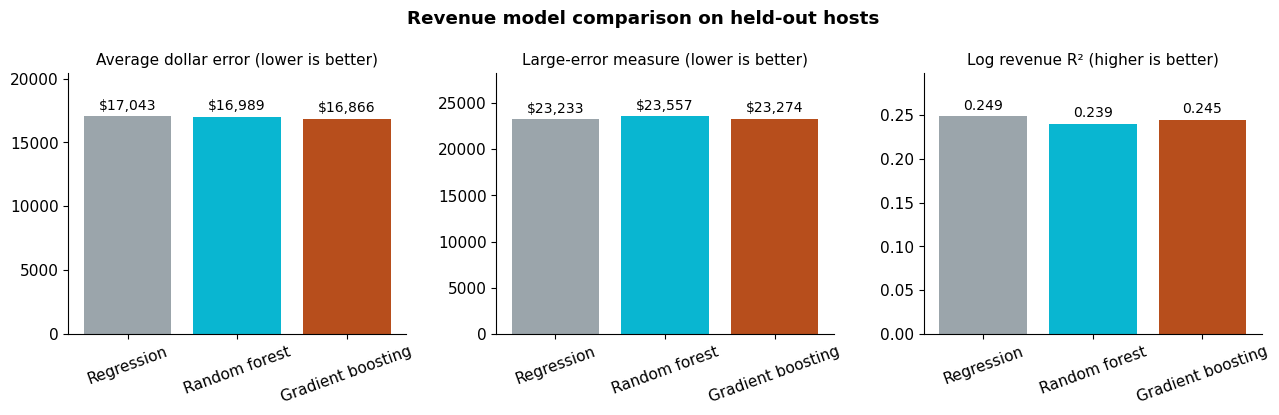

,model,test_median_AE_AUD,test_P90_AE_AUD,test_bias_AUD,test_WAPE_pct
0,Log-linear regression,12643.88,36032.21,209.83,57.79
1,Random forest,12370.61,35219.98,-802.61,57.61
2,Gradient boosting,12553.96,35055.22,-760.32,57.19


In [31]:
revenue_comparison_metrics_rows, revenue_comparison_predictions, revenue_comparison_logs = (
    [],
    {},
    {},
)
for revenue_comparison_name, revenue_comparison_search in revenue_comparison_searches.items():
    revenue_comparison_model = revenue_comparison_search.best_estimator_
    revenue_comparison_prediction = revenue_comparison_model.predict(revenue_comparison_X_test)
    revenue_comparison_log_prediction = revenue_comparison_model.predict_log(
        revenue_comparison_X_test
    )
    (
        revenue_comparison_predictions[revenue_comparison_name],
        revenue_comparison_logs[revenue_comparison_name],
    ) = (revenue_comparison_prediction, revenue_comparison_log_prediction)
    revenue_comparison_preparation = revenue_comparison_model.pipeline_.named_steps["prepare"]
    revenue_comparison_other_share = (
        revenue_comparison_preparation.transform(revenue_comparison_X_test)["combination_model"]
        .eq("Other combinations")
        .mean()
    )
    revenue_comparison_metrics_rows.append(
        {
            "model": revenue_comparison_name,
            "test_MAE_AUD": mean_absolute_error(
                revenue_comparison_y_test, revenue_comparison_prediction
            ),
            "test_RMSE_AUD": np.sqrt(
                mean_squared_error(revenue_comparison_y_test, revenue_comparison_prediction)
            ),
            "test_median_AE_AUD": np.median(
                np.abs(revenue_comparison_y_test.to_numpy() - revenue_comparison_prediction)
            ),
            "test_log_R2": r2_score(
                np.log(revenue_comparison_y_test), revenue_comparison_log_prediction
            ),
            "test_log_RMSE": np.sqrt(
                mean_squared_error(
                    np.log(revenue_comparison_y_test), revenue_comparison_log_prediction
                )
            ),
            "test_dollar_R2": r2_score(revenue_comparison_y_test, revenue_comparison_prediction),
            "train_MAE_AUD": mean_absolute_error(
                revenue_comparison_y_train,
                revenue_comparison_model.predict(revenue_comparison_X_train),
            ),
            "smearing_factor": revenue_comparison_model.smearing_,
            "test_other_combination_share": revenue_comparison_other_share,
        }
    )
revenue_comparison_comparison = pd.DataFrame(revenue_comparison_metrics_rows)
revenue_comparison_baseline_mae = revenue_comparison_comparison.loc[
    revenue_comparison_comparison["model"].eq("Log-linear regression"), "test_MAE_AUD"
].iloc[0]
revenue_comparison_comparison["MAE_reduction_vs_regression_pct"] = (
    1 - revenue_comparison_comparison["test_MAE_AUD"] / revenue_comparison_baseline_mae
) * 100
revenue_comparison_comparison["selected_by_training_CV"] = revenue_comparison_comparison[
    "model"
].eq(revenue_comparison_selected_model_name)
display(
    revenue_comparison_comparison[
        [
            "model",
            "test_MAE_AUD",
            "test_RMSE_AUD",
            "test_log_R2",
            "test_dollar_R2",
            "MAE_reduction_vs_regression_pct",
            "selected_by_training_CV",
        ]
    ].round(3)
)
display(
    revenue_comparison_comparison[
        [
            "model",
            "train_MAE_AUD",
            "test_median_AE_AUD",
            "smearing_factor",
            "test_other_combination_share",
        ]
    ].round(3)
)
revenue_comparison_test_predictions = revenue_comparison_data.loc[
    revenue_comparison_X_test.index,
    ["id", "host_cluster_id", "suburb", "client_property_format", "estimated_revenue_l365d"],
].copy()
for (
    revenue_comparison_name,
    revenue_comparison_prediction,
) in revenue_comparison_predictions.items():
    revenue_comparison_test_predictions[revenue_comparison_name] = revenue_comparison_prediction
assert len(revenue_comparison_test_predictions) == len(revenue_comparison_X_test)
assert np.isfinite(
    revenue_comparison_test_predictions[list(revenue_comparison_predictions)].to_numpy()
).all()
revenue_comparison_fig, revenue_comparison_axes = plt.subplots(1, 3, figsize=(13, 4.2))
revenue_comparison_labels = ["Regression", "Random forest", "Gradient boosting"]
revenue_comparison_colors = ["#9BA5AB", "#09B6D1", "#B74E1C"]
for revenue_comparison_ax, revenue_comparison_metric, revenue_comparison_title in zip(
    revenue_comparison_axes,
    ["test_MAE_AUD", "test_RMSE_AUD", "test_log_R2"],
    [
        "Average dollar error (lower is better)",
        "Large-error measure (lower is better)",
        "Log revenue R² (higher is better)",
    ],
):
    revenue_comparison_values = revenue_comparison_comparison[revenue_comparison_metric].to_numpy()
    revenue_comparison_ax.bar(
        revenue_comparison_labels, revenue_comparison_values, color=revenue_comparison_colors
    )
    for revenue_comparison_i, revenue_comparison_value in enumerate(revenue_comparison_values):
        revenue_comparison_ax.annotate(
            (
                f"${revenue_comparison_value:,.0f}"
                if revenue_comparison_metric.endswith("AUD")
                else f"{revenue_comparison_value:.3f}"
            ),
            (revenue_comparison_i, revenue_comparison_value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10,
        )
    revenue_comparison_ax.set_title(revenue_comparison_title, fontsize=11)
    revenue_comparison_ax.tick_params(axis="x", labelrotation=20)
    revenue_comparison_ax.spines[["top", "right"]].set_visible(False)
    revenue_comparison_ax.margins(y=0.2)
revenue_comparison_fig.suptitle("Revenue model comparison on held-out hosts", fontweight="bold")
revenue_comparison_fig.tight_layout()
revenue_comparison_fig.savefig(
    revenue_comparison_OUTPUT_DIR / "unseen_host_model_comparison.png", dpi=180, bbox_inches="tight"
)
plt.show()

# Supplementary diagnostics use the same test predictions, not extra fitted models.
revenue_comparison_comparison["test_bias_AUD"] = [
    float(np.mean(revenue_comparison_predictions[m] - revenue_comparison_y_test.to_numpy()))
    for m in revenue_comparison_comparison["model"]
]
revenue_comparison_comparison["test_P90_AE_AUD"] = [
    float(
        np.quantile(
            np.abs(revenue_comparison_predictions[m] - revenue_comparison_y_test.to_numpy()), 0.90
        )
    )
    for m in revenue_comparison_comparison["model"]
]
revenue_comparison_comparison["test_WAPE_pct"] = [
    100
    * float(
        np.abs(revenue_comparison_predictions[m] - revenue_comparison_y_test.to_numpy()).sum()
        / np.abs(revenue_comparison_y_test.to_numpy()).sum()
    )
    for m in revenue_comparison_comparison["model"]
]
display(
    revenue_comparison_comparison[
        ["model", "test_median_AE_AUD", "test_P90_AE_AUD", "test_bias_AUD", "test_WAPE_pct"]
    ].round(2)
)

#### Uncertainty in any improvement

The paired bootstrap resamples whole held-out hosts, retaining all their listings, 1,000 times. A positive gain means lower MAE than the benchmark regression. If its 95 percent interval crosses zero, this test sample does not establish a clear improvement. The interval is conditional on these fitted models, not a confidence interval for property income, and it excludes retraining uncertainty. Segment results and a training-median reference provide additional context.

,model,MAE_improvement_AUD,bootstrap_95_low_AUD,bootstrap_95_high_AUD,clear_positive_improvement
0,Random forest,54.34,-373.70,549.07,False
1,Gradient boosting,176.83,-286.71,640.45,False


,property_format,model,test_listings,test_hosts,MAE_AUD,RMSE_AUD
0,Specialty/other accommodation,Log-linear regression,38,32,24346.1,36409.0
1,Specialty/other accommodation,Random forest,38,32,22630.8,33237.3
2,Specialty/other accommodation,Gradient boosting,38,32,23374.6,34312.3
3,Whole apartment/unit,Log-linear regression,1457,684,16502.2,21718.7
4,Whole apartment/unit,Random forest,1457,684,16289.6,21644.0
5,Whole apartment/unit,Gradient boosting,1457,684,16248.2,21494.5
6,Whole guesthouse/secondary dwelling,Log-linear regression,101,96,12613.8,17694.1
7,Whole guesthouse/secondary dwelling,Random forest,101,96,14505.9,19391.7
8,Whole guesthouse/secondary dwelling,Gradient boosting,101,96,13837.7,18431.4
9,Whole house,Log-linear regression,600,367,18657.7,26435.0


,model,test_MAE_AUD,test_RMSE_AUD
0,Training median (dollar reference),19874.9,29154.1


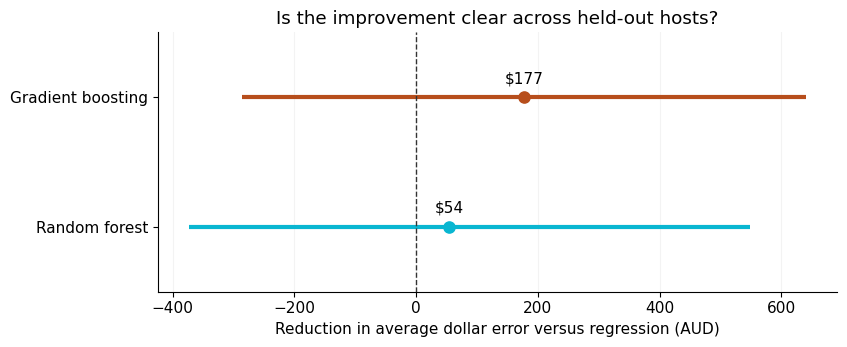

In [32]:
revenue_comparison_error_frame = pd.DataFrame({"host": revenue_comparison_test_groups.to_numpy()})
for (
    revenue_comparison_name,
    revenue_comparison_prediction,
) in revenue_comparison_predictions.items():
    revenue_comparison_error_frame[revenue_comparison_name] = np.abs(
        revenue_comparison_y_test.to_numpy() - revenue_comparison_prediction
    )
revenue_comparison_host_sums = revenue_comparison_error_frame.groupby("host")[
    list(revenue_comparison_predictions)
].sum()
revenue_comparison_host_counts = (
    revenue_comparison_error_frame.groupby("host")
    .size()
    .reindex(revenue_comparison_host_sums.index)
    .to_numpy()
)
revenue_comparison_rng = np.random.default_rng(revenue_comparison_SEED)
revenue_comparison_bootstrap_rows = []
for revenue_comparison_challenger in ["Random forest", "Gradient boosting"]:
    revenue_comparison_gains = (
        revenue_comparison_host_sums["Log-linear regression"]
        - revenue_comparison_host_sums[revenue_comparison_challenger]
    ).to_numpy()
    revenue_comparison_samples = np.empty(revenue_comparison_BOOTSTRAP_REPEATS)
    for revenue_comparison_b in range(revenue_comparison_BOOTSTRAP_REPEATS):
        revenue_comparison_chosen = revenue_comparison_rng.integers(
            0, len(revenue_comparison_host_sums), size=len(revenue_comparison_host_sums)
        )
        revenue_comparison_samples[revenue_comparison_b] = (
            revenue_comparison_gains[revenue_comparison_chosen].sum()
            / revenue_comparison_host_counts[revenue_comparison_chosen].sum()
        )
    revenue_comparison_low, revenue_comparison_high = np.quantile(
        revenue_comparison_samples, [0.025, 0.975]
    )
    revenue_comparison_bootstrap_rows.append(
        {
            "model": revenue_comparison_challenger,
            "MAE_improvement_AUD": revenue_comparison_gains.sum()
            / revenue_comparison_host_counts.sum(),
            "bootstrap_95_low_AUD": revenue_comparison_low,
            "bootstrap_95_high_AUD": revenue_comparison_high,
            "clear_positive_improvement": bool(revenue_comparison_low > 0),
        }
    )
revenue_comparison_bootstrap_comparison = pd.DataFrame(revenue_comparison_bootstrap_rows)
display(revenue_comparison_bootstrap_comparison.round(2))
revenue_comparison_segment_rows = []
for (
    revenue_comparison_segment,
    revenue_comparison_subset,
) in revenue_comparison_test_predictions.groupby("client_property_format"):
    for revenue_comparison_name in revenue_comparison_predictions:
        revenue_comparison_segment_rows.append(
            {
                "property_format": revenue_comparison_segment,
                "model": revenue_comparison_name,
                "test_listings": len(revenue_comparison_subset),
                "test_hosts": revenue_comparison_subset["host_cluster_id"].nunique(),
                "MAE_AUD": mean_absolute_error(
                    revenue_comparison_subset["estimated_revenue_l365d"],
                    revenue_comparison_subset[revenue_comparison_name],
                ),
                "RMSE_AUD": np.sqrt(
                    mean_squared_error(
                        revenue_comparison_subset["estimated_revenue_l365d"],
                        revenue_comparison_subset[revenue_comparison_name],
                    )
                ),
            }
        )
revenue_comparison_segment_results = pd.DataFrame(revenue_comparison_segment_rows)
display(revenue_comparison_segment_results.round(1))
revenue_comparison_naive_prediction = np.repeat(
    revenue_comparison_y_train.median(), len(revenue_comparison_y_test)
)
revenue_comparison_naive_metrics = pd.DataFrame(
    [
        {
            "model": "Training median (dollar reference)",
            "test_MAE_AUD": mean_absolute_error(
                revenue_comparison_y_test, revenue_comparison_naive_prediction
            ),
            "test_RMSE_AUD": np.sqrt(
                mean_squared_error(revenue_comparison_y_test, revenue_comparison_naive_prediction)
            ),
        }
    ]
)
display(revenue_comparison_naive_metrics.round(1))
revenue_comparison_fig, revenue_comparison_ax = plt.subplots(figsize=(8.6, 3.6))
revenue_comparison_gain = revenue_comparison_bootstrap_comparison["MAE_improvement_AUD"].to_numpy()
revenue_comparison_lo = revenue_comparison_bootstrap_comparison["bootstrap_95_low_AUD"].to_numpy()
revenue_comparison_hi = revenue_comparison_bootstrap_comparison["bootstrap_95_high_AUD"].to_numpy()
revenue_comparison_locations = np.arange(len(revenue_comparison_bootstrap_comparison))
for revenue_comparison_j, revenue_comparison_color in enumerate(["#09B6D1", "#B74E1C"]):
    revenue_comparison_ax.hlines(
        revenue_comparison_locations[revenue_comparison_j],
        revenue_comparison_lo[revenue_comparison_j],
        revenue_comparison_hi[revenue_comparison_j],
        color=revenue_comparison_color,
        linewidth=3,
    )
    revenue_comparison_ax.scatter(
        revenue_comparison_gain[revenue_comparison_j],
        revenue_comparison_locations[revenue_comparison_j],
        color=revenue_comparison_color,
        s=65,
        zorder=3,
    )
    revenue_comparison_ax.annotate(
        f"${revenue_comparison_gain[revenue_comparison_j]:,.0f}",
        (
            revenue_comparison_gain[revenue_comparison_j],
            revenue_comparison_locations[revenue_comparison_j],
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )
revenue_comparison_ax.axvline(0, color="#333333", linestyle="--", linewidth=1)
revenue_comparison_ax.set_yticks(
    revenue_comparison_locations, revenue_comparison_bootstrap_comparison["model"]
)
revenue_comparison_ax.set_ylim(-0.5, 1.5)
revenue_comparison_ax.set_xlabel("Reduction in average dollar error versus regression (AUD)")
revenue_comparison_ax.set_title("Is the improvement clear across held-out hosts?")
revenue_comparison_ax.spines[["top", "right"]].set_visible(False)
revenue_comparison_ax.grid(axis="x", alpha=0.15)
revenue_comparison_fig.tight_layout()
revenue_comparison_fig.savefig(
    revenue_comparison_OUTPUT_DIR / "host_bootstrap_mae_improvement.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

#### Retain the explainable model for the client decision

The tables above separate the training-CV MAE winner from the model retained for the client-facing analysis. In the verified comparison, boosting has the smallest average dollar error, while regression has the smallest RMSE and highest log R squared. An interval crossing zero does not prove equivalence; it means this bootstrap check does not establish a clear positive MAE gain.

We retain log-linear regression to produce transparent like-for-like suburb and property comparisons with uncertainty estimates, given the small observed prediction differences. The generated output reports the actual gains and flags any clear challenger improvement for review. This is a business-purpose trade-off, not an assertion that regression is always best.

AIC is not calculated from out-of-fold errors for this three-model comparison. Standard AIC uses fitted likelihood and an appropriate complexity penalty; counting tree models' predictors or trees as regression coefficients would not provide a justified common penalty. We use host-grouped cross-validation and test diagnostics instead. See [information criteria and cross-validation](https://scikit-learn.org/stable/auto_examples/linear_model/plot_lasso_model_selection.html).

The next cells fit the retained regression and generate the main revenue recommendation. All later acquisition and seasonal recommendations use that model consistently. Detailed challenger scenario estimates are retained in the technical appendix as a sensitivity check, not ignored or used as competing main recommendations.

In [33]:
revenue_comparison_selected = revenue_comparison_comparison.set_index("model").loc[
    revenue_comparison_selected_model_name
]
revenue_comparison_test_best = revenue_comparison_comparison.sort_values("test_MAE_AUD").iloc[0][
    "model"
]
revenue_comparison_findings = [
    f"**Training-CV choice:** {revenue_comparison_selected_model_name}.",
    f"**Final unseen-host performance:** MAE ${revenue_comparison_selected.test_MAE_AUD:,.0f}, RMSE ${revenue_comparison_selected.test_RMSE_AUD:,.0f}, log R² {revenue_comparison_selected.test_log_R2:.3f}.",
    f"**Change versus regression:** {revenue_comparison_selected.MAE_reduction_vs_regression_pct:.1f}% reduction in average absolute dollar error on the test hosts.",
    f"**Lowest test MAE:** {revenue_comparison_test_best}. This is reported descriptively, not used to retune models.",
]
if revenue_comparison_selected_model_name != "Log-linear regression":
    revenue_comparison_row = revenue_comparison_bootstrap_comparison.set_index("model").loc[
        revenue_comparison_selected_model_name
    ]
    revenue_comparison_findings.append(
        f"**Host-bootstrap improvement interval:** ${revenue_comparison_row.bootstrap_95_low_AUD:,.0f} to ${revenue_comparison_row.bootstrap_95_high_AUD:,.0f} of MAE reduction relative to regression. "
        + (
            "The interval is above zero."
            if revenue_comparison_row.clear_positive_improvement
            else "The interval does not establish a clear positive improvement."
        )
    )
display(Markdown("\n\n".join(revenue_comparison_findings)))
display(
    Markdown(
        "**Client interpretation:** Use improved prediction as an additional check on the investment shortlist.\nDo not describe higher predictive accuracy as proof of higher actual profit, causal amenity effects or a safer investment.\nTree-model scenario outputs have no equivalent mean-revenue confidence intervals here.\nThe existing revenue lower-bound ranking and acquisition recommendation remain unchanged pending a separate review."
    )
)
revenue_comparison_tables = {
    "model_comparison": revenue_comparison_comparison,
    "training_cv_comparison": revenue_comparison_cv_comparison,
    "tuning_results": revenue_comparison_tuning_results,
    "split_audit": revenue_comparison_split_audit,
    "host_bootstrap_mae_comparison": revenue_comparison_bootstrap_comparison,
    "property_format_test_metrics": revenue_comparison_segment_results,
    "naive_reference_metrics": revenue_comparison_naive_metrics,
    "test_predictions": revenue_comparison_test_predictions,
    "training_times": pd.DataFrame(revenue_comparison_timing_rows),
}
for revenue_comparison_filename, revenue_comparison_table in revenue_comparison_tables.items():
    revenue_comparison_table.to_csv(
        revenue_comparison_OUTPUT_DIR / (revenue_comparison_filename + ".csv"), index=False
    )


def revenue_comparison_file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


revenue_comparison_metadata = {
    "seed": revenue_comparison_SEED,
    "cv_folds": revenue_comparison_CV_FOLDS,
    "bootstrap_repeats": revenue_comparison_BOOTSTRAP_REPEATS,
    "sklearn_version": sklearn_version,
    "python_version": platform.python_version(),
    "target": "estimated_revenue_l365d",
    "features": revenue_comparison_FEATURES,
    "selected_by_training_cv": revenue_comparison_selected_model_name,
    "best_parameters": {
        revenue_comparison_name: revenue_comparison_search.best_params_
        for revenue_comparison_name, revenue_comparison_search in revenue_comparison_searches.items()
    },
    "source_sha256": {
        revenue_comparison_name: revenue_comparison_file_hash(
            revenue_comparison_DATA_DIR / revenue_comparison_name
        )
        for revenue_comparison_name in revenue_comparison_REQUIRED
    },
    "source_files": revenue_comparison_REQUIRED,
    "analysis_rows": len(revenue_comparison_data),
    "train_rows": len(revenue_comparison_X_train),
    "test_rows": len(revenue_comparison_X_test),
    "preprocessing": "Training-only support grouping and capacity-group median imputation",
    "selection_metric": "Three-fold host-grouped CV dollar MAE",
}
(revenue_comparison_OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(revenue_comparison_metadata, indent=2), encoding="utf-8"
)
print("Saved comparison tables, figures and reproducibility metadata.")
revenue_comparison_metric_winners = pd.DataFrame(
    [
        {
            "metric": "Average dollar error (MAE)",
            "best_test_model": revenue_comparison_comparison.loc[
                revenue_comparison_comparison["test_MAE_AUD"].idxmin(), "model"
            ],
        },
        {
            "metric": "Large-error measure (RMSE)",
            "best_test_model": revenue_comparison_comparison.loc[
                revenue_comparison_comparison["test_RMSE_AUD"].idxmin(), "model"
            ],
        },
        {
            "metric": "Log revenue R squared",
            "best_test_model": revenue_comparison_comparison.loc[
                revenue_comparison_comparison["test_log_R2"].idxmax(), "model"
            ],
        },
    ]
)
display(revenue_comparison_metric_winners)
revenue_comparison_clear_models = revenue_comparison_bootstrap_comparison.loc[
    revenue_comparison_bootstrap_comparison["clear_positive_improvement"], "model"
].tolist()
if not revenue_comparison_clear_models:
    revenue_comparison_explanation = "Neither challenger has a host-bootstrap interval wholly above zero for improvement in test MAE. Retain the interpretable log-linear regression as the main client-facing comparison model for this benchmark, and use the tree models as sensitivity checks. This is not a claim that regression always predicts best."
else:
    revenue_comparison_explanation = (
        "At least one challenger has a positive host-bootstrap MAE-improvement interval: "
        + ", ".join(revenue_comparison_clear_models)
        + ". Review the practical gain and scenario support before deciding which model to retain. Do not assume interpretability alone settles that decision."
    )
display(Markdown("**Model choice for the report:** " + revenue_comparison_explanation))
display(
    Markdown(
        "**Important distinction:** Similar overall test errors do not imply identical suburb estimates or rankings. The technical appendix contains the scenario chart and rank-agreement table that measure this disagreement. Tree point predictions have no equivalent host-clustered confidence intervals or Strong evidence tiers here. The existing investment and seasonal recommendations below continue to use the original log-linear regression."
    )
)
revenue_comparison_benchmark_interpretation = pd.DataFrame(
    [{"finding": "Model choice for the report", "interpretation": revenue_comparison_explanation}]
)
revenue_comparison_metric_winners.to_csv(
    revenue_comparison_OUTPUT_DIR / "metric_winners.csv", index=False
)
revenue_comparison_benchmark_interpretation.to_csv(
    revenue_comparison_OUTPUT_DIR / "interpretation.csv", index=False
)

# Business-purpose retention is distinct from the algorithm winning CV MAE.
revenue_comparison_primary_model_for_recommendations = "Log-linear regression"
revenue_comparison_log_row = revenue_comparison_comparison.set_index("model").loc[
    "Log-linear regression"
]
revenue_comparison_boost_row = revenue_comparison_comparison.set_index("model").loc[
    "Gradient boosting"
]
revenue_comparison_choice_rationale = (
    f"Retained for the main client comparison: {revenue_comparison_primary_model_for_recommendations}. "
    f"Gradient boosting's held-out MAE reduction is {revenue_comparison_boost_row.MAE_reduction_vs_regression_pct:.2f}%. "
    f"Regression records RMSE ${revenue_comparison_log_row.test_RMSE_AUD:,.0f} and log R squared {revenue_comparison_log_row.test_log_R2:.3f}. "
    "The business rationale is transparent adjusted comparisons and uncertainty estimates alongside similar observed predictive errors, "
    "not a claim that regression wins every metric. The CV-MAE winner remains separately reported. "
    "If a challenger demonstrates a meaningful, repeatable improvement, this retention decision should be reviewed."
)
display(Markdown("**Retained model and reason:** " + revenue_comparison_choice_rationale))
pd.DataFrame(
    [
        {
            "retained_model": revenue_comparison_primary_model_for_recommendations,
            "training_cv_MAE_winner": revenue_comparison_selected_model_name,
            "rationale": revenue_comparison_choice_rationale,
        }
    ]
).to_csv(revenue_comparison_OUTPUT_DIR / "retained_model_decision.csv", index=False)

**Training-CV choice:** Gradient boosting.

**Final unseen-host performance:** MAE $16,866, RMSE $23,274, log R² 0.245.

**Change versus regression:** 1.0% reduction in average absolute dollar error on the test hosts.

**Lowest test MAE:** Gradient boosting. This is reported descriptively, not used to retune models.

**Host-bootstrap improvement interval:** $-287 to $640 of MAE reduction relative to regression. The interval does not establish a clear positive improvement.

**Client interpretation:** Use improved prediction as an additional check on the investment shortlist.
Do not describe higher predictive accuracy as proof of higher actual profit, causal amenity effects or a safer investment.
Tree-model scenario outputs have no equivalent mean-revenue confidence intervals here.
The existing revenue lower-bound ranking and acquisition recommendation remain unchanged pending a separate review.

Saved comparison tables, figures and reproducibility metadata.


,metric,best_test_model
0,Average dollar error (MAE),Gradient boosting
1,Large-error measure (RMSE),Log-linear regression
2,Log revenue R squared,Log-linear regression


**Model choice for the report:** Neither challenger has a host-bootstrap interval wholly above zero for improvement in test MAE. Retain the interpretable log-linear regression as the main client-facing comparison model for this benchmark, and use the tree models as sensitivity checks. This is not a claim that regression always predicts best.

**Important distinction:** Similar overall test errors do not imply identical suburb estimates or rankings. The technical appendix contains the scenario chart and rank-agreement table that measure this disagreement. Tree point predictions have no equivalent host-clustered confidence intervals or Strong evidence tiers here. The existing investment and seasonal recommendations below continue to use the original log-linear regression.

**Retained model and reason:** Retained for the main client comparison: Log-linear regression. Gradient boosting's held-out MAE reduction is 1.04%. Regression records RMSE $23,233 and log R squared 0.249. The business rationale is transparent adjusted comparisons and uncertainty estimates alongside similar observed predictive errors, not a claim that regression wins every metric. The CV-MAE winner remains separately reported. If a challenger demonstrates a meaningful, repeatable improvement, this retention decision should be reviewed.

### Fit the retained log regression and calculate recommendation uncertainty

The algorithm check is complete. Fit the retained log-linear specification using the original comprehensive-analysis controls, then estimate host-clustered uncertainty on the full eligible cohort. Keep the presentation's comparison setup and ranking rule unchanged: four guests, two bedrooms, one bathroom, a two-night minimum, a non-Superhost and one host listing. The revenue-only shortlist ranks Strong combinations by the lower confidence bound of their estimated mean revenue.

The original-fit validation below is retained for provenance. Its preprocessing differs slightly from the common training-aware benchmark above, so small score differences do not represent a changed revenue target or a different test cohort.

In [34]:
validation_model = smf.ols(
    recommendation_formula,
    data=recommendation_train,
).fit()
validation_smearing_factor = float(np.exp(validation_model.resid).mean())
test_log_prediction = validation_model.predict(recommendation_test)
test_revenue_prediction = np.exp(test_log_prediction) * validation_smearing_factor
test_actual_revenue = recommendation_test["estimated_revenue_l365d"]

model_validation = pd.DataFrame(
    {
        "metric": [
            "train_rows",
            "test_rows",
            "train_hosts",
            "test_hosts",
            "test_log_revenue_R2",
            "test_log_revenue_RMSE",
            "test_revenue_MAE_AUD",
            "test_revenue_RMSE_AUD",
        ],
        "value": [
            len(recommendation_train),
            len(recommendation_test),
            recommendation_train["host_cluster_id"].nunique(),
            recommendation_test["host_cluster_id"].nunique(),
            r2_score(recommendation_test["log_revenue"], test_log_prediction),
            np.sqrt(mean_squared_error(recommendation_test["log_revenue"], test_log_prediction)),
            mean_absolute_error(test_actual_revenue, test_revenue_prediction),
            np.sqrt(mean_squared_error(test_actual_revenue, test_revenue_prediction)),
        ],
    }
)

suburb_property_revenue_model = smf.ols(
    recommendation_formula,
    data=recommendation_data,
).fit(
    cov_type="cluster",
    cov_kwds={"groups": recommendation_data["host_cluster_id"]},
)
full_smearing_factor = float(np.exp(suburb_property_revenue_model.resid).mean())

display(model_validation.round(3))
print("Full-model observations:", int(suburb_property_revenue_model.nobs))
print("Full-model R-squared:", round(suburb_property_revenue_model.rsquared, 3))

revenue_comparison_reference = model_validation.set_index("metric")["value"]
revenue_comparison_original_fit_reference = pd.DataFrame(
    [
        {
            "model": "Original comprehensive regression reference",
            "test_MAE_AUD": revenue_comparison_reference["test_revenue_MAE_AUD"],
            "test_RMSE_AUD": revenue_comparison_reference["test_revenue_RMSE_AUD"],
            "test_log_R2": revenue_comparison_reference["test_log_revenue_R2"],
        }
    ]
)
display(revenue_comparison_original_fit_reference.round(3))

revenue_comparison_original_fit_reference.to_csv(
    revenue_comparison_OUTPUT_DIR / "original_comprehensive_fit_reference.csv", index=False
)

,metric,value
0,train_rows,9300.000
1,test_rows,2245.000
2,train_hosts,4476.000
3,test_hosts,1120.000
4,test_log_revenue_R2,0.244
5,test_log_revenue_RMSE,0.943
6,test_revenue_MAE_AUD,17230.445
7,test_revenue_RMSE_AUD,23584.004


Full-model observations: 11545
Full-model R-squared: 0.246


,model,test_MAE_AUD,test_RMSE_AUD,test_log_R2
0,Original comprehensive regression reference,17230.445,23584.004,0.244


### Adjusted predictions, uncertainty and recommendation rule

Coefficients are converted to percentage differences only once. Benjamini–Hochberg correction controls the false-discovery rate across supported-combination effects relative to the pooled Other combinations reference. Strong evidence requires at least 20 listings, 10 hosts, q < 0.05 and a positive lower coefficient confidence bound against that reference. It does not establish significant differences between shortlisted segments. Dollar predictions use a retransformation correction for the log model. The ranking uses the lower confidence bound of predicted revenue, rewarding both estimated performance and precision rather than selecting the largest unstable point estimate.

In [35]:
parameter_names = [
    name
    for name in suburb_property_revenue_model.params.index
    if "C(combination_model" in name and "[T." in name
]
parameter_ci = suburb_property_revenue_model.conf_int().loc[parameter_names]

combination_effects = pd.DataFrame(
    {
        "parameter": parameter_names,
        "suburb_property_combination": [
            name.rsplit("[T.", 1)[1][:-1] for name in parameter_names
        ],
        "coefficient": suburb_property_revenue_model.params.loc[
            parameter_names
        ].to_numpy(),
        "p_value": suburb_property_revenue_model.pvalues.loc[
            parameter_names
        ].to_numpy(),
        "coefficient_ci_low": parameter_ci.iloc[:, 0].to_numpy(),
        "coefficient_ci_high": parameter_ci.iloc[:, 1].to_numpy(),
    }
)
combination_effects["q_value_BH"] = multipletests(
    combination_effects["p_value"], method="fdr_bh"
)[1]
for output_column, source_column in [
    ("adjusted_difference_pct", "coefficient"),
    ("adjusted_difference_ci_low_pct", "coefficient_ci_low"),
    ("adjusted_difference_ci_high_pct", "coefficient_ci_high"),
]:
    combination_effects[output_column] = (
        np.exp(combination_effects[source_column]) - 1
    ) * 100

scenario_labels = ["Other combinations"] + supported_labels
prediction_scenarios = pd.DataFrame(
    {
        "combination_model": pd.Categorical(
            scenario_labels, categories=combination_levels
        ),
        "accommodates": 4,
        "bedrooms": 2,
        "bathrooms_n": 1,
        "minimum_nights": 2,
        "minimum_nights_missing": 0,
        "is_superhost": 0,
        "calculated_host_listings_count": 1,
    }
)
prediction_frame = suburb_property_revenue_model.get_prediction(
    prediction_scenarios
).summary_frame(alpha=0.05)
scenario_predictions = pd.DataFrame(
    {
        "suburb_property_combination": scenario_labels,
        "adjusted_predicted_revenue_aud": (
            np.exp(prediction_frame["mean"]) * full_smearing_factor
        ),
        "adjusted_revenue_ci_low_aud": (
            np.exp(prediction_frame["mean_ci_lower"]) * full_smearing_factor
        ),
        "adjusted_revenue_ci_high_aud": (
            np.exp(prediction_frame["mean_ci_upper"]) * full_smearing_factor
        ),
    }
)
baseline_revenue = float(
    scenario_predictions.loc[
        scenario_predictions["suburb_property_combination"].eq(
            "Other combinations"
        ),
        "adjusted_predicted_revenue_aud",
    ].iloc[0]
)

suburb_property_recommendations = (
    supported_combinations.merge(
        combination_effects,
        on="suburb_property_combination",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        scenario_predictions.query(
            "suburb_property_combination != 'Other combinations'"
        ),
        on="suburb_property_combination",
        how="left",
        validate="one_to_one",
    )
)
suburb_property_recommendations["predicted_vs_reference_pct"] = (
    suburb_property_recommendations["adjusted_predicted_revenue_aud"]
    / baseline_revenue
    - 1
) * 100

strong_evidence = (
    suburb_property_recommendations["listings"].ge(STRONG_LISTINGS)
    & suburb_property_recommendations["unique_hosts"].ge(STRONG_HOSTS)
    & suburb_property_recommendations["q_value_BH"].lt(0.05)
    & suburb_property_recommendations["coefficient_ci_low"].gt(0)
)
moderate_evidence = (
    ~strong_evidence
    & suburb_property_recommendations["q_value_BH"].lt(0.05)
    & suburb_property_recommendations["coefficient_ci_low"].gt(0)
)
suburb_property_recommendations["evidence_tier"] = np.select(
    [strong_evidence, moderate_evidence],
    ["Strong", "Moderate"],
    default="Exploratory",
)
suburb_property_recommendations = suburb_property_recommendations.sort_values(
    ["evidence_tier", "adjusted_revenue_ci_low_aud"],
    ascending=[True, False],
)

recommendation_columns = [
    "suburb", "client_property_format", "listings", "unique_hosts",
    "adjusted_predicted_revenue_aud", "adjusted_revenue_ci_low_aud",
    "adjusted_revenue_ci_high_aud", "predicted_vs_reference_pct",
    "adjusted_difference_pct", "q_value_BH", "evidence_tier",
]
display(
    suburb_property_recommendations.sort_values(
        "adjusted_revenue_ci_low_aud", ascending=False
    )[recommendation_columns].head(20).round(3)
)

,suburb,client_property_format,listings,unique_hosts,adjusted_predicted_revenue_aud,adjusted_revenue_ci_low_aud,adjusted_revenue_ci_high_aud,predicted_vs_reference_pct,adjusted_difference_pct,q_value_BH,evidence_tier
42,Collingwood,Whole house,12,11,34747.009,23950.258,50410.923,151.996,151.996,0.000,Moderate
81,Healesville,Whole guesthouse/secondary dwelling,14,12,29850.739,23135.759,38514.691,116.487,116.487,0.000,Moderate
40,Coldstream,Whole house,10,9,30718.254,22562.422,41822.244,122.779,122.779,0.000,Moderate
59,Fitzroy,Whole apartment/unit,113,82,26099.553,21543.590,31618.995,89.282,89.282,0.000,Strong
26,Carlton North,Whole house,10,10,32071.466,21296.931,48297.050,132.593,132.593,0.001,Moderate
41,Collingwood,Whole apartment/unit,110,76,27532.766,20858.553,36342.561,99.676,99.676,0.000,Strong
82,Healesville,Whole house,77,62,26299.403,20856.189,33163.231,90.732,90.732,0.000,Strong
153,Windsor,Whole house,11,11,27826.577,19544.261,39618.709,101.807,101.807,0.001,Moderate
60,Fitzroy,Whole house,35,32,27214.805,19250.731,38473.636,97.371,97.371,0.001,Strong
130,South Yarra,Whole house,32,26,24690.399,19137.302,31854.846,79.063,79.063,0.000,Strong


In [36]:
primary_recommendations = suburb_property_recommendations.loc[
    suburb_property_recommendations["evidence_tier"].eq("Strong")
].sort_values("adjusted_revenue_ci_low_aud", ascending=False)

print("=" * 80)
print("CURRENT REVENUE-POTENTIAL RECOMMENDATION")
print("=" * 80)
if primary_recommendations.empty:
    print(
        "No combination satisfies every strong-evidence rule. "
        "The notebook therefore does not issue a primary recommendation."
    )
else:
    best = primary_recommendations.iloc[0]
    print(f"Suburb: {best['suburb']}")
    print(f"Property format: {best['client_property_format']} (Airbnb host-reported)")
    print(
        f"Exact evidence: {int(best['listings'])} listings across "
        f"{int(best['unique_hosts'])} hosts"
    )
    print(
        "Adjusted annual revenue for the standard scenario: "
        f"${best['adjusted_predicted_revenue_aud']:,.0f}"
    )
    print(
        "95% confidence interval for the expected mean: "
        f"${best['adjusted_revenue_ci_low_aud']:,.0f} to "
        f"${best['adjusted_revenue_ci_high_aud']:,.0f}"
    )
    print(f"FDR-adjusted q-value: {best['q_value_BH']:.4g}")
    print("Evidence tier: Strong")

print()
print(
    "This is a modelled gross-revenue recommendation, not observed revenue, "
    "profit or ROI. The acquisition-price cross-check follows below."
)

prior_gruyere_guesthouse = combination_support.loc[
    combination_support["suburb"].eq("Gruyere")
    & combination_support["client_property_format"].eq(
        "Whole guesthouse/secondary dwelling"
    )
]
if not prior_gruyere_guesthouse.empty:
    print()
    print("Previously highlighted exploratory combination:")
    display(prior_gruyere_guesthouse.round(2))
    print(
        "It is not entered as its own model effect because it does not meet "
        "the exact-combination support threshold."
    )

CURRENT REVENUE-POTENTIAL RECOMMENDATION
Suburb: Fitzroy
Property format: Whole apartment/unit (Airbnb host-reported)
Exact evidence: 113 listings across 82 hosts
Adjusted annual revenue for the standard scenario: $26,100
95% confidence interval for the expected mean: $21,544 to $31,619
FDR-adjusted q-value: 2.674e-10
Evidence tier: Strong

This is a modelled gross-revenue recommendation, not observed revenue, profit or ROI. The acquisition-price cross-check follows below.

Previously highlighted exploratory combination:


,suburb,client_property_format,suburb_property_combination,listings,unique_hosts,median_estimated_revenue_aud,mean_estimated_revenue_aud,median_bedrooms,median_bathrooms
447,Gruyere,Whole guesthouse/secondary dwelling,Gruyere | Whole guesthouse/secondary dwelling,2,2,33564.0,33564.0,1.5,1.0


It is not entered as its own model effect because it does not meet the exact-combination support threshold.


## 12. ROI estimation and revenue cross-check

**Question:** does accounting for the estimated acquisition price change which supported suburb and property format appears most attractive?

The numerator remains the Section 11 adjusted annual revenue for a common scenario: four guests, two bedrooms, one bathroom, a two-night minimum, a non-Superhost and one host listing. The denominator is a **two-bedroom acquisition-price proxy**. It starts with the official 2025 VGV suburb × house/unit median and scales it using the corresponding DFFH two-bedroom rent relative to the representative rent for that market and dwelling class.

This aligns property size across the numerator and denominator. DFFH rent evidence is matched using exact market names, named components of grouped markets, unambiguous locality-name aliases, and finally published LGA-level markets. The LGA fallback is less local, but it avoids treating available government evidence as missing; for example, Healesville and Warburton use the published Yarra Ranges house-bedroom rents.

Every supported revenue combination is retained in a coverage audit before yield is calculated. Combinations without a defensible two-bedroom house/unit proxy remain visible with an exclusion reason; guesthouses and unclassified dwellings are not arbitrarily assigned a house or unit price. Revenue rankings are compared with estimated gross-yield rankings using Spearman correlation, top-five overlap and rank changes.

The section is titled ROI estimation for the business question, but the calculated measure is **estimated gross revenue yield**, not true ROI. It excludes financing, stamp duty, tax, strata/body-corporate charges, cleaning, management, maintenance, utilities, vacancy risk and resale value.

The supplied `listings_with_property_price_benchmarks.csv` records its government source files: `VGV_houses_by_suburb_2015-2025.xlsx` and `VGV_units_by_suburb_2015-2025.xlsx` for 2025 sale-price medians, and `DFFH_moving_annual_rent_by_suburb_September_2025.xlsx` for rental evidence. Representative rent is the letting-count-weighted median of bedroom-category median weekly rents within the matched rental market and dwelling class.

Two-bedroom purchase-price proxy = VGV median × (two-bedroom rent ÷ representative rent).

This notebook starts from the prepared CSV; it does not recreate its extraction from the government workbooks.

In [37]:
COMPREHENSIVE_OUTPUT = DATA_DIR / "Testing" / "comprehensive_analysis"
COMPREHENSIVE_OUTPUT.mkdir(parents=True, exist_ok=True)
# The listing-level acquisition-price benchmark was validated with the other
# required project-root CSV inputs in the setup cell.

price_proxy = pd.read_csv(
    PROPERTY_PRICE_PATH,
    usecols=[
        "id", "suburb", "property_type", "dwelling_class", "bedrooms_benchmark",
        "acquisition_median_2025_aud", "bedroom_adjusted_acquisition_price_proxy_aud",
        "bedroom_adjustment_status", "dffh_market", "dffh_mapping_method",
    ],
    dtype={"id": "string"},
    low_memory=False,
)
if not price_proxy["id"].is_unique:
    raise ValueError("The acquisition-price file contains duplicate listing IDs.")

price_proxy["client_property_format"] = price_proxy["property_type"].map(client_property_format)
price_proxy["bedrooms_benchmark"] = pd.to_numeric(
    price_proxy["bedrooms_benchmark"], errors="coerce"
)
price_proxy["bedroom_adjusted_acquisition_price_proxy_aud"] = pd.to_numeric(
    price_proxy["bedroom_adjusted_acquisition_price_proxy_aud"], errors="coerce"
)
price_proxy["suburb_property_combination"] = (
    price_proxy["suburb"].astype(str).str.title()
    + " | "
    + price_proxy["client_property_format"].astype(str)
)

two_bed_proxy = price_proxy.loc[
    price_proxy["bedrooms_benchmark"].eq(2)
    & price_proxy["dwelling_class"].isin(["House", "Unit"])
    & price_proxy["bedroom_adjusted_acquisition_price_proxy_aud"].gt(0)
].copy()

acquisition_by_combination = (
    two_bed_proxy.groupby("suburb_property_combination", observed=True)
    .agg(
        acquisition_proxy_2br_aud=("bedroom_adjusted_acquisition_price_proxy_aud", "median"),
        acquisition_source_rows=("id", "size"),
        acquisition_proxy_unique_values=("bedroom_adjusted_acquisition_price_proxy_aud", "nunique"),
        acquisition_median_2025_aud=("acquisition_median_2025_aud", "median"),
        dffh_markets=("dffh_market", "nunique"),
        dffh_mapping_methods=("dffh_mapping_method", lambda values: " | ".join(
            sorted(set(values.dropna().astype(str)))
        )),
    )
    .reset_index()
)

# Audit all supported revenue combinations before filtering. This prevents an
# inner join from silently hiding a suburb/property format with no valid proxy.
two_bed_candidate_audit = (
    price_proxy.loc[price_proxy["bedrooms_benchmark"].eq(2)]
    .groupby("suburb_property_combination", observed=True)
    .agg(
        acquisition_candidate_rows=("id", "size"),
        acquisition_valid_rows=(
            "bedroom_adjusted_acquisition_price_proxy_aud",
            lambda values: int(values.gt(0).sum()),
        ),
        acquisition_statuses=("bedroom_adjustment_status", lambda values: " | ".join(
            sorted(set(values.dropna().astype(str)))
        )),
        candidate_mapping_methods=("dffh_mapping_method", lambda values: " | ".join(
            sorted(set(values.dropna().astype(str)))
        )),
    )
    .reset_index()
)

roi_acquisition_coverage = (
    suburb_property_recommendations.merge(
        acquisition_by_combination,
        on="suburb_property_combination",
        how="left",
        validate="one_to_one",
    )
    .merge(
        two_bed_candidate_audit,
        on="suburb_property_combination",
        how="left",
        validate="one_to_one",
    )
)
roi_acquisition_coverage["acquisition_candidate_rows"] = (
    roi_acquisition_coverage["acquisition_candidate_rows"].fillna(0).astype(int)
)
roi_acquisition_coverage["acquisition_valid_rows"] = (
    roi_acquisition_coverage["acquisition_valid_rows"].fillna(0).astype(int)
)
roi_acquisition_coverage["acquisition_proxy_available"] = (
    roi_acquisition_coverage["acquisition_proxy_2br_aud"].gt(0)
)
roi_acquisition_coverage["acquisition_coverage_reason"] = np.select(
    [
        roi_acquisition_coverage["acquisition_proxy_available"],
        roi_acquisition_coverage["acquisition_candidate_rows"].eq(0),
    ],
    [
        "Valid two-bedroom acquisition proxy",
        "No observed two-bedroom listing in this supported combination",
    ],
    default=roi_acquisition_coverage["acquisition_statuses"].fillna(
        "Two-bedroom acquisition proxy unavailable"
    ),
)

roi_recommendations = roi_acquisition_coverage.loc[
    roi_acquisition_coverage["acquisition_proxy_available"]
].copy()
roi_recommendations["estimated_gross_yield_pct"] = (
    roi_recommendations["adjusted_predicted_revenue_aud"]
    / roi_recommendations["acquisition_proxy_2br_aud"] * 100
)
roi_recommendations["estimated_gross_yield_ci_low_pct"] = (
    roi_recommendations["adjusted_revenue_ci_low_aud"]
    / roi_recommendations["acquisition_proxy_2br_aud"] * 100
)
roi_recommendations["estimated_gross_yield_ci_high_pct"] = (
    roi_recommendations["adjusted_revenue_ci_high_aud"]
    / roi_recommendations["acquisition_proxy_2br_aud"] * 100
)
roi_recommendations["revenue_rank"] = roi_recommendations[
    "adjusted_predicted_revenue_aud"
].rank(method="min", ascending=False).astype(int)
roi_recommendations["gross_yield_rank"] = roi_recommendations[
    "estimated_gross_yield_pct"
].rank(method="min", ascending=False).astype(int)
roi_recommendations["rank_change_yield_minus_revenue"] = (
    roi_recommendations["gross_yield_rank"] - roi_recommendations["revenue_rank"]
)

rank_test = spearmanr(
    roi_recommendations["adjusted_predicted_revenue_aud"],
    roi_recommendations["estimated_gross_yield_pct"],
)
top_n = min(5, len(roi_recommendations))
top_revenue = set(roi_recommendations.nsmallest(top_n, "revenue_rank")["suburb_property_combination"])
top_yield = set(roi_recommendations.nsmallest(top_n, "gross_yield_rank")["suburb_property_combination"])
roi_crosscheck_summary = pd.DataFrame({
    "metric": [
        "supported revenue combinations", "combinations with valid 2-bedroom acquisition proxy",
        "coverage of supported combinations", "Spearman revenue-yield rank correlation",
        "Spearman p-value", "top-five overlap", "top-five Jaccard overlap",
    ],
    "value": [
        len(suburb_property_recommendations), len(roi_recommendations),
        len(roi_recommendations) / len(suburb_property_recommendations),
        rank_test.statistic, rank_test.pvalue, len(top_revenue & top_yield),
        len(top_revenue & top_yield) / len(top_revenue | top_yield),
    ],
})

display(roi_crosscheck_summary.round(4))
display(
    roi_acquisition_coverage.groupby(
        ["acquisition_proxy_available", "acquisition_coverage_reason"],
        dropna=False,
    ).size().rename("supported_combinations").reset_index()
)
roi_columns = [
    "suburb", "client_property_format", "listings", "unique_hosts", "evidence_tier",
    "adjusted_predicted_revenue_aud", "acquisition_proxy_2br_aud",
    "estimated_gross_yield_pct", "estimated_gross_yield_ci_low_pct",
    "estimated_gross_yield_ci_high_pct", "revenue_rank", "gross_yield_rank",
]
display(
    roi_recommendations.sort_values("gross_yield_rank")[roi_columns].head(15).round(3)
)


,metric,value
0,supported revenue combinations,157.0000
1,combinations with valid 2-bedroom acquisition proxy,125.0000
2,coverage of supported combinations,0.7962
3,Spearman revenue-yield rank correlation,0.5476
4,Spearman p-value,0.0000
5,top-five overlap,1.0000
6,top-five Jaccard overlap,0.1111


,acquisition_proxy_available,acquisition_coverage_reason,supported_combinations
0,False,No observed two-bedroom listing in this supported combination,8
1,False,VGV acquisition median unavailable,2
2,False,suburb/LGA not matched to a published DFFH market,20
3,False,unclassified dwelling type,2
4,True,Valid two-bedroom acquisition proxy,125


,suburb,client_property_format,listings,unique_hosts,evidence_tier,adjusted_predicted_revenue_aud,acquisition_proxy_2br_aud,estimated_gross_yield_pct,estimated_gross_yield_ci_low_pct,estimated_gross_yield_ci_high_pct,revenue_rank,gross_yield_rank
140,Collingwood,Whole apartment/unit,110,76,Strong,27532.766,630000.000,4.370,3.311,5.769,6,1
130,Coldstream,Whole house,10,9,Moderate,30718.254,714285.714,4.301,3.159,5.855,3,2
6,Kensington,Whole apartment/unit,16,14,Exploratory,19442.411,471500.000,4.124,2.877,5.910,32,3
137,Fairfield,Whole apartment/unit,14,9,Moderate,21362.640,530000.000,4.031,3.056,5.316,22,4
141,Healesville,Whole house,77,62,Strong,26299.403,678991.597,3.873,3.072,4.884,9,5
144,Melbourne,Whole apartment/unit,2657,1006,Strong,21043.793,545000.000,3.861,3.497,4.264,25,6
155,Flemington,Whole apartment/unit,20,17,Strong,21302.804,573000.000,3.718,2.662,5.192,23,7
2,Brunswick East,Whole apartment/unit,32,29,Exploratory,20007.655,540000.000,3.705,2.740,5.009,30,8
8,Doncaster,Whole apartment/unit,10,10,Exploratory,22520.346,620000.000,3.632,2.144,6.152,18,9
24,Footscray,Whole apartment/unit,55,48,Exploratory,15668.953,453500.000,3.455,2.576,4.634,61,10


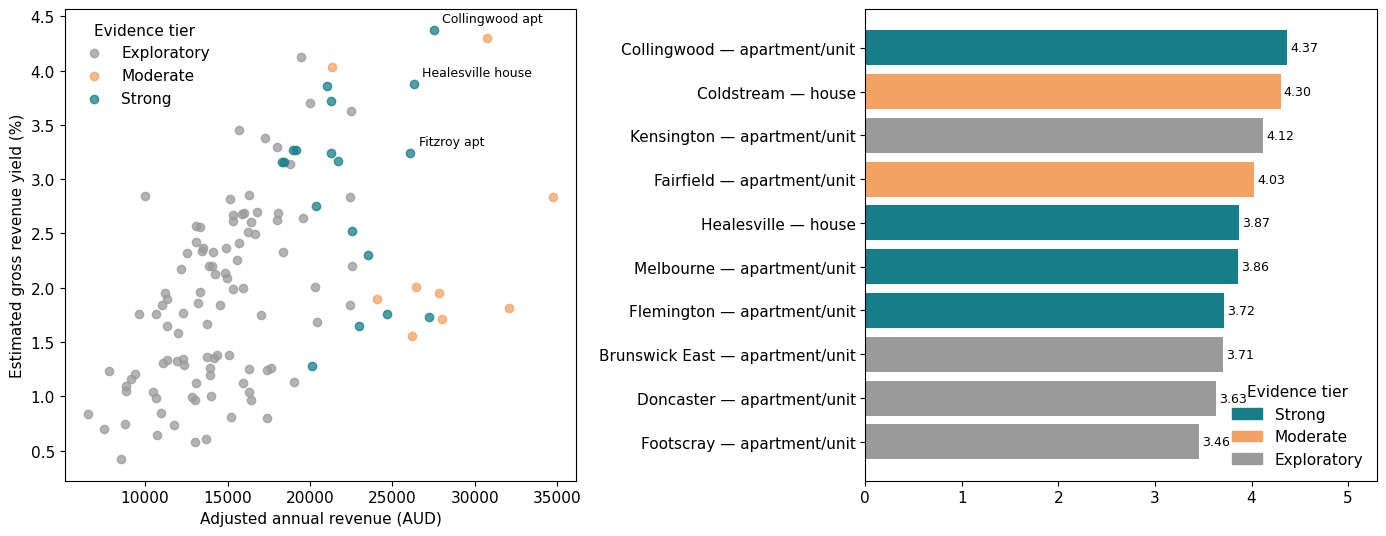

In [38]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
evidence_colors = {"Strong": "#177E89", "Moderate": "#F4A261", "Exploratory": "#9A9A9A"}

for tier, block in roi_recommendations.groupby("evidence_tier", observed=True):
    axes[0].scatter(block["adjusted_predicted_revenue_aud"], block["estimated_gross_yield_pct"],
                    label=tier, alpha=0.75, color=evidence_colors[tier])
for name, short in [("Collingwood | Whole apartment/unit", "Collingwood apt"),
                    ("Healesville | Whole house", "Healesville house"),
                    ("Fitzroy | Whole apartment/unit", "Fitzroy apt")]:
    row = roi_recommendations.loc[roi_recommendations["suburb_property_combination"].eq(name)].iloc[0]
    axes[0].annotate(short, (row["adjusted_predicted_revenue_aud"], row["estimated_gross_yield_pct"]),
                     xytext=(6, 6), textcoords="offset points", fontsize=9)
axes[0].set(xlabel="Adjusted annual revenue (AUD)", ylabel="Estimated gross revenue yield (%)")
axes[0].legend(title="Evidence tier", frameon=False)

yield_plot = roi_recommendations.nsmallest(10, "gross_yield_rank").sort_values("estimated_gross_yield_pct")
labels = yield_plot["suburb"] + " — " + yield_plot["client_property_format"].str.replace("Whole ", "")
axes[1].barh(labels, yield_plot["estimated_gross_yield_pct"],
             color=yield_plot["evidence_tier"].map(evidence_colors))
for i, v in enumerate(yield_plot["estimated_gross_yield_pct"]):
    axes[1].text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=9)
axes[1].set_xlim(0, 5.3)
axes[1].legend(handles=[Patch(color=c, label=t) for t, c in evidence_colors.items()],
               title="Evidence tier", frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(
    DATA_DIR / "roi_revenue_crosscheck.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

### Interpretation

The rank correlation and top-five overlap compare revenue and gross-yield point estimates across all 125 combinations with usable purchase-price proxies. These comparisons are separate from the recommendation rules: Strong segments are ranked by lower-bound revenue for the revenue shortlist and by point-estimated gross yield for acquisition. A high correlation supports broad consistency, but it does not validate the acquisition proxy as a property valuation. A low correlation means purchase cost changes the decision rather than invalidating the revenue model.

## 13. Individual amenity associations

**Question:** which individual amenities have the strongest statistically supported association with estimated annual revenue?

Each amenity is included jointly with the other retained amenity indicators and the existing property, location, minimum-stay and host controls. Effects are estimated separately for the review-based revenue proxy and Inside Airbnb estimated revenue. Host-clustered standard errors address repeated listings from the same host, and Benjamini–Hochberg correction controls the false-discovery rate within each outcome.

An amenity is labelled cross-checked only when both revenue definitions have `q < 0.05` and the same effect direction. These are conditional associations among existing listings. They do not prove installation causes the estimated percentage change, and effects must not be multiplied together as guaranteed gains.

In [39]:
def fitted_amenity_table(outcome):
    fitted = smf.ols(f"{outcome} ~ {rhs}", data=regression_data).fit(
        cov_type="cluster",
        cov_kwds={"groups": regression_data["host_cluster_id"]},
    )
    ci = fitted.conf_int().loc[amenity_terms]
    table = pd.DataFrame({
        "coefficient": fitted.params[amenity_terms],
        "p_value": fitted.pvalues[amenity_terms],
        "coefficient_ci_low": ci.iloc[:, 0],
        "coefficient_ci_high": ci.iloc[:, 1],
    })
    table["effect_pct"] = (np.exp(table["coefficient"]) - 1) * 100
    table["effect_ci_low_pct"] = (np.exp(table["coefficient_ci_low"]) - 1) * 100
    table["effect_ci_high_pct"] = (np.exp(table["coefficient_ci_high"]) - 1) * 100
    table["q_value_BH"] = multipletests(table["p_value"], method="fdr_bh")[1]
    return table

amenity_review = fitted_amenity_table("log_review_revenue_proxy").add_prefix("review_")
amenity_inside = fitted_amenity_table("log_inside_airbnb_revenue").add_prefix("inside_")
amenity_effects = amenity_review.join(amenity_inside, how="inner")
amenity_effects["same_direction"] = np.sign(amenity_effects["review_coefficient"]).eq(
    np.sign(amenity_effects["inside_coefficient"])
)
amenity_effects["cross_checked"] = (
    amenity_effects["review_q_value_BH"].lt(0.05)
    & amenity_effects["inside_q_value_BH"].lt(0.05)
    & amenity_effects["same_direction"]
)
amenity_effects["amenity"] = amenity_effects.index.str.removeprefix("a_").str.replace("_", " ").str.title()
amenity_effects["mean_revenue_effect_pct"] = amenity_effects[
    ["review_effect_pct", "inside_effect_pct"]
].mean(axis=1)
amenity_effects = amenity_effects.sort_values(
    ["cross_checked", "mean_revenue_effect_pct"], ascending=[False, False]
)

amenity_display_columns = [
    "amenity", "review_effect_pct", "review_effect_ci_low_pct", "review_effect_ci_high_pct",
    "review_q_value_BH", "inside_effect_pct", "inside_effect_ci_low_pct",
    "inside_effect_ci_high_pct", "inside_q_value_BH", "cross_checked",
]
display(amenity_effects[amenity_display_columns].head(20).round(3))
print("Amenities tested:", len(amenity_effects))
print("Cross-checked amenities:", int(amenity_effects["cross_checked"].sum()))


,amenity,review_effect_pct,review_effect_ci_low_pct,review_effect_ci_high_pct,review_q_value_BH,inside_effect_pct,inside_effect_ci_low_pct,inside_effect_ci_high_pct,inside_q_value_BH,cross_checked
a_smart_entry,Smart Entry,55.061,14.620,109.772,0.044,55.086,14.664,109.758,0.044,True
a_stainless_steel_oven,Stainless Steel Oven,20.683,10.699,31.568,0.001,20.671,10.691,31.550,0.001,True
a_view,View,18.154,11.222,25.517,0.000,18.150,11.221,25.510,0.000,True
a_hair_dryer,Hair Dryer,14.654,5.843,24.199,0.012,14.654,5.844,24.197,0.012,True
a_single_level_home,Single Level Home,13.656,6.034,21.825,0.006,13.655,6.035,21.822,0.006,True
a_dishwasher,Dishwasher,12.395,5.444,19.804,0.006,12.394,5.444,19.802,0.006,True
a_dryer,Dryer,9.163,3.202,15.468,0.026,9.163,3.205,15.465,0.027,True
a_essentials,Essentials,8.857,2.460,15.655,0.049,8.856,2.460,15.652,0.049,True
a_first_aid_kit,First Aid Kit,-8.990,-14.349,-3.296,0.026,-8.984,-14.342,-3.292,0.027,True
a_backyard,Backyard,-10.008,-16.404,-3.123,0.045,-10.006,-16.402,-3.122,0.046,True


Amenities tested: 90
Cross-checked amenities: 11


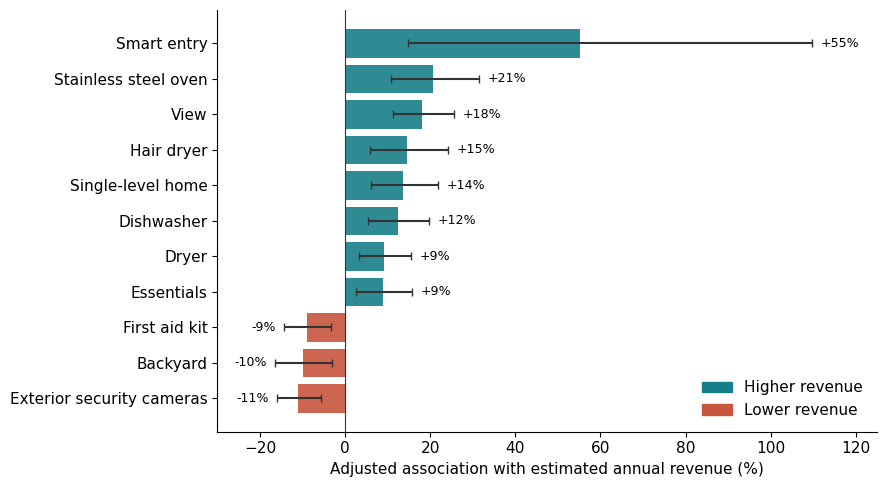

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plot_amenities = amenity_effects.loc[amenity_effects["cross_checked"]].copy()
plot_amenities = plot_amenities.sort_values("inside_effect_pct")
short = {"Exterior Security Cameras On Property": "Exterior security cameras",
         "Single Level Home": "Single-level home",
         "Stainless Steel Oven": "Stainless steel oven",
         "First Aid Kit": "First aid kit", "Hair Dryer": "Hair dryer",
         "Smart Entry": "Smart entry"}
labels = plot_amenities["amenity"].replace(short)

effect = plot_amenities["inside_effect_pct"].to_numpy()
low = plot_amenities["inside_effect_ci_low_pct"].to_numpy()
high = plot_amenities["inside_effect_ci_high_pct"].to_numpy()
y = np.arange(len(plot_amenities))
colors = np.where(effect >= 0, "#177E89", "#C8553D")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, effect, color=colors, alpha=0.9)
ax.errorbar(effect, y, xerr=np.vstack([effect - low, high - effect]),
            fmt="none", ecolor="#333333", capsize=3)
for yi, e, h, l in zip(y, effect, high, low):
    x = h + 2 if e >= 0 else l - 2
    ax.text(x, yi, f"{e:+.0f}%", va="center", ha="left" if e >= 0 else "right", fontsize=9)
ax.axvline(0, color="#333333", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("Adjusted association with estimated annual revenue (%)")
ax.set_xlim(-30, 125)
ax.legend(handles=[Patch(color="#177E89", label="Higher revenue"),
                   Patch(color="#C8553D", label="Lower revenue")],
          frameon=False, loc="lower right")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(
    DATA_DIR / "amenity_revenue_effects.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## 14. Review-score drivers of overall guest experience

**Question:** which review category is most useful for predicting guests' independently submitted overall rating?

Airbnb states that the overall rating is its own category rather than an average of accuracy, cleanliness, check-in, communication, location and value. This makes overall rating a more direct outcome for the guest-experience question and avoids defining the outcome with the project's review-based revenue assumptions.

The analysis retains all supported listings but reduces the influence of unstable averages. Each category score is shrunk toward its sample mean using a 20-review prior, and the regression weights listings by the reliability of their review count. Cubic splines allow the relationship to change near the five-star ceiling. Repeated 80/20 host-grouped validation compares controls-only, linear-score and nonlinear-score models. Conditional importance is the loss in unseen-host prediction when one category's complete spline is removed.

The output measures predictive association, not Airbnb algorithm weights or a causal revenue effect. Official definitions: [Airbnb ratings for homes](https://www.airbnb.com/help/article/1257) and [Airbnb search ranking](https://www.airbnb.com/help/article/39).

In [41]:
REVIEW_SCORE_COLUMNS = {
    "Accuracy": "review_scores_accuracy",
    "Cleanliness": "review_scores_cleanliness",
    "Check-in": "review_scores_checkin",
    "Communication": "review_scores_communication",
    "Location": "review_scores_location",
    "Value": "review_scores_value",
}
OVERALL_REVIEW_COLUMN = "review_scores_rating"
REVIEW_COUNT_COLUMN = "number_of_reviews"
REVIEW_PRIOR_STRENGTH = 20

# Use the project's cleaned client-scope listings without requiring either estimated-revenue outcome.
review_source = model_df.replace([np.inf, -np.inf], np.nan).copy()
rating_columns = [OVERALL_REVIEW_COLUMN] + list(REVIEW_SCORE_COLUMNS.values())
for column in rating_columns + [REVIEW_COUNT_COLUMN]:
    review_source[column] = pd.to_numeric(review_source[column], errors="coerce")

review_required = list(dict.fromkeys(
    required_for_models + rating_columns + [REVIEW_COUNT_COLUMN, "host_cluster_id"]
))
review_data = review_source.dropna(subset=review_required).copy()
valid_ratings = review_data[rating_columns].apply(lambda values: values.between(1, 5)).all(axis=1)
review_data = review_data.loc[valid_ratings & review_data[REVIEW_COUNT_COLUMN].gt(0)].copy()

for categorical_column in ["property_type_model", "suburb"]:
    review_data[categorical_column] = pd.Categorical(
        review_data[categorical_column],
        categories=model_df[categorical_column].dropna().unique(),
    )

# Reliability approaches one as review support grows. A one-review average is pulled
# strongly toward the market mean, while an established listing changes much less.
review_count = review_data[REVIEW_COUNT_COLUMN].to_numpy(float)
review_reliability = review_count / (review_count + REVIEW_PRIOR_STRENGTH)
review_data["review_reliability"] = review_reliability

adjusted_score_columns = {}
adjustment_rows = []
for label, column in REVIEW_SCORE_COLUMNS.items():
    market_mean = review_data[column].mean()
    adjusted_column = f"adjusted_{column}"
    review_data[adjusted_column] = (
        market_mean + review_data["review_reliability"] * (review_data[column] - market_mean)
    )
    adjusted_score_columns[label] = adjusted_column
    adjustment_rows.append({
        "review_aspect": label,
        "market_mean": market_mean,
        "raw_standard_deviation": review_data[column].std(ddof=0),
        "adjusted_standard_deviation": review_data[adjusted_column].std(ddof=0),
    })

review_adjustment_summary = pd.DataFrame(adjustment_rows)
review_count_examples = pd.DataFrame({"review_count": [1, 5, 20, 50, 100]})
review_count_examples["reliability_weight"] = (
    review_count_examples["review_count"]
    / (review_count_examples["review_count"] + REVIEW_PRIOR_STRENGTH)
)

review_outcome = review_data[OVERALL_REVIEW_COLUMN].to_numpy(float)
review_weights = review_data["review_reliability"].to_numpy(float)
review_groups = review_data["host_cluster_id"].to_numpy()

# Pool suburbs with fewer than 20 listings so control dummies are estimable.
suburb_counts = review_data["suburb"].astype(str).value_counts()
rare_suburbs = suburb_counts[suburb_counts < 20].index
review_data["suburb"] = pd.Categorical(
    review_data["suburb"].astype(str).where(
        ~review_data["suburb"].astype(str).isin(rare_suburbs), "Other suburbs"
    )
)
print("Suburb levels after pooling:", review_data["suburb"].nunique())
# Build the control, linear-score and nonlinear-score matrices once. The nonlinear
# basis has four degrees of freedom per score, enough to represent ceiling curvature
# without fitting a highly flexible curve to the sparse lower-rating tail.
review_control_design = np.asarray(
    dmatrix("1 + " + rhs, review_data, return_type="dataframe"), dtype=float
)
review_linear_design = review_data[list(adjusted_score_columns.values())].to_numpy(float)

spline_design_info = {}
spline_blocks = {}
spline_slices = {}
spline_start = 0
for label, column in adjusted_score_columns.items():
    block = dmatrix(
        f"0 + bs({column}, df=4, degree=3, include_intercept=False, lower_bound=1, upper_bound=5)",
        review_data,
        return_type="dataframe",
    )
    spline_design_info[label] = block.design_info
    spline_blocks[label] = np.asarray(block, dtype=float)
    spline_slices[label] = slice(spline_start, spline_start + block.shape[1])
    spline_start += block.shape[1]
review_nonlinear_design = np.column_stack(list(spline_blocks.values()))


Suburb levels after pooling: 95


In [42]:
def stable_lstsq(A, B, rcond=None):
    """Column-scaled truncated-SVD least squares; same return shape as np.linalg.lstsq()[0]."""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    one_d = B.ndim == 1
    B2 = B.reshape(len(B), -1)
    scale = np.sqrt((A ** 2).mean(axis=0))
    scale[scale == 0] = 1.0
    U, s, Vt = np.linalg.svd(A / scale, full_matrices=False)
    keep = s > s[0] * 1e-8
    coef = (Vt[keep].T / s[keep]) @ (U[:, keep].T @ B2)
    coef = coef / scale[:, None]
    return (coef[:, 0] if one_d else coef,)

In [43]:
def weighted_prediction_metrics(actual, predicted, weights):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    weights = np.asarray(weights, dtype=float)
    error = actual - predicted
    weighted_mean = np.average(actual, weights=weights)
    sse = np.sum(weights * error ** 2)
    sst = np.sum(weights * (actual - weighted_mean) ** 2)
    return {
        "weighted_R2": 1 - sse / sst,
        "weighted_RMSE": np.sqrt(np.average(error ** 2, weights=weights)),
        "weighted_MAE": np.average(np.abs(error), weights=weights),
    }

def fit_small_weighted_model(train_y, train_z, test_z, train_weights):
    sqrt_weight = np.sqrt(train_weights)
    coefficient = stable_lstsq(
        train_z * sqrt_weight[:, None], train_y * sqrt_weight, rcond=None
    )[0]
    return test_z @ coefficient, coefficient

# Keep cell 72's full-data matrices for the descriptive fit in cell 75.
# Validation gets its own fitted preprocessing for each training split.
# Results condition on the existing cleaned sample and fixed earlier controls
# (rhs); this cell does not refit the earlier shared cleaning/feature selection.
def fit_review_validation_preprocessor(train_frame):
    train_frame = train_frame.copy()
    state = {
        "score_means": {
            column: float(train_frame[column].mean())
            for column in REVIEW_SCORE_COLUMNS.values()
        },
        "retained_suburbs": set(
            train_frame["suburb"].astype(str).value_counts().loc[lambda n: n >= 20].index
        ),
        "category_levels": {},
        "category_fallbacks": {},
        "spline_design_info": {},
        "spline_slices": {},
    }
    train_frame = adjust_review_validation_scores(train_frame, state)
    train_frame["suburb"] = train_frame["suburb"].astype(str).where(
        train_frame["suburb"].astype(str).isin(state["retained_suburbs"]),
        "Other suburbs",
    )
    for column in ["property_type_model", "suburb"]:
        values = train_frame[column].astype(str)
        # Learn only observed training levels. Unknown test labels use an
        # estimable pooled category, or the most common training category.
        levels = sorted(values.unique())
        pooled = "Other suburbs" if column == "suburb" else "Other"
        fallback = pooled if pooled in levels else values.value_counts().index[0]
        state["category_levels"][column] = levels
        state["category_fallbacks"][column] = fallback
        train_frame[column] = pd.Categorical(values, categories=levels)

    control = dmatrix("1 + " + rhs, train_frame, return_type="dataframe")
    state["control_design_info"] = control.design_info
    blocks = []
    start = 0
    for label, column in adjusted_score_columns.items():
        # Domain bounds are fixed by the 1--5 rating scale. Interior knots
        # are fitted on training scores and reused unchanged for test rows.
        block = dmatrix(
            f"0 + bs({column}, df=4, degree=3, include_intercept=False, lower_bound=1, upper_bound=5)",
            train_frame, return_type="dataframe",
        )
        state["spline_design_info"][label] = block.design_info
        state["spline_slices"][label] = slice(start, start + block.shape[1])
        start += block.shape[1]
        blocks.append(np.asarray(block, dtype=float))
    return state, (
        np.asarray(control, dtype=float),
        train_frame[list(adjusted_score_columns.values())].to_numpy(float),
        np.column_stack(blocks),
    )


def adjust_review_validation_scores(frame, state):
    frame = frame.copy()
    reliability = (
        frame[REVIEW_COUNT_COLUMN].to_numpy(float)
        / (frame[REVIEW_COUNT_COLUMN].to_numpy(float) + REVIEW_PRIOR_STRENGTH)
    )
    for label, column in REVIEW_SCORE_COLUMNS.items():
        mean = state["score_means"][column]
        frame[adjusted_score_columns[label]] = (
            mean + reliability * (frame[column].to_numpy(float) - mean)
        )
    return frame


def transform_review_validation_frame(frame, state):
    frame = adjust_review_validation_scores(frame, state)
    frame["suburb"] = frame["suburb"].astype(str).where(
        frame["suburb"].astype(str).isin(state["retained_suburbs"]),
        "Other suburbs",
    )
    for column, levels in state["category_levels"].items():
        values = frame[column].astype(str)
        values = values.where(values.isin(levels), state["category_fallbacks"][column])
        frame[column] = pd.Categorical(values, categories=levels)
    control = build_design_matrices([state["control_design_info"]], frame)[0]
    blocks = [
        np.asarray(build_design_matrices([state["spline_design_info"][label]], frame)[0], dtype=float)
        for label in adjusted_score_columns
    ]
    return (
        np.asarray(control, dtype=float),
        frame[list(adjusted_score_columns.values())].to_numpy(float),
        np.column_stack(blocks),
    )


# The first weighted least-squares projection removes the existing listing, host,
# amenity, property-format and suburb controls. The remaining score model is small,
# so repeated host-grouped validation and complete-score dropout checks are practical.
review_splitter = GroupShuffleSplit(n_splits=10, test_size=0.20, random_state=30005)
validation_rows = []
dropout_rows = []
# review_source retains unpooled suburb labels; review_data has cell 72's
# full-data pooling. Keep exactly the same eligible rows and row ordering.
review_validation_source = review_source.loc[review_data.index].copy()
linear_end = 1 + len(adjusted_score_columns)

for split_number, (train_index, test_index) in enumerate(
    review_splitter.split(review_data, groups=review_groups), start=1
):
    split_preprocessor, (x_train, score_train, spline_train) = (
        fit_review_validation_preprocessor(review_validation_source.iloc[train_index])
    )
    x_test, score_test, spline_test = transform_review_validation_frame(
        review_validation_source.iloc[test_index], split_preprocessor
    )
    target_train = np.column_stack([
        review_outcome[train_index], score_train, spline_train
    ])
    target_test = np.column_stack([
        review_outcome[test_index], score_test, spline_test
    ])
    train_weight = review_weights[train_index]
    test_weight = review_weights[test_index]
    sqrt_weight = np.sqrt(train_weight)

    control_coefficients = stable_lstsq(
        x_train * sqrt_weight[:, None],
        target_train * sqrt_weight[:, None],
        rcond=None,
    )[0]
    residual_train = target_train - x_train @ control_coefficients
    residual_test = target_test - x_test @ control_coefficients
    baseline_prediction = x_test @ control_coefficients[:, 0]

    linear_train = residual_train[:, 1:linear_end]
    linear_test = residual_test[:, 1:linear_end]
    linear_added_prediction, _ = fit_small_weighted_model(
        residual_train[:, 0], linear_train, linear_test, train_weight
    )
    linear_prediction = baseline_prediction + linear_added_prediction

    nonlinear_train = residual_train[:, linear_end:]
    nonlinear_test = residual_test[:, linear_end:]
    nonlinear_added_prediction, _ = fit_small_weighted_model(
        residual_train[:, 0], nonlinear_train, nonlinear_test, train_weight
    )
    nonlinear_prediction = baseline_prediction + nonlinear_added_prediction

    predictions = {
        "Controls only": baseline_prediction,
        "Controls + adjusted linear scores": linear_prediction,
        "Controls + adjusted nonlinear scores": nonlinear_prediction,
    }
    split_metrics = {}
    for model_name, prediction in predictions.items():
        metrics = weighted_prediction_metrics(
            review_outcome[test_index], prediction, test_weight
        )
        split_metrics[model_name] = metrics
        validation_rows.append({
            "split": split_number, "model": model_name, **metrics,
        })

    full_metrics = split_metrics["Controls + adjusted nonlinear scores"]
    for label, block_slice in split_preprocessor["spline_slices"].items():
        retained = np.ones(nonlinear_train.shape[1], dtype=bool)
        retained[block_slice] = False
        reduced_added_prediction, _ = fit_small_weighted_model(
            residual_train[:, 0],
            nonlinear_train[:, retained],
            nonlinear_test[:, retained],
            train_weight,
        )
        reduced_prediction = baseline_prediction + reduced_added_prediction
        reduced_metrics = weighted_prediction_metrics(
            review_outcome[test_index], reduced_prediction, test_weight
        )
        dropout_rows.append({
            "split": split_number,
            "review_aspect": label,
            "R2_loss_when_removed": full_metrics["weighted_R2"] - reduced_metrics["weighted_R2"],
            "RMSE_increase_when_removed": reduced_metrics["weighted_RMSE"] - full_metrics["weighted_RMSE"],
        })

review_validation_splits = pd.DataFrame(validation_rows)
review_validation = review_validation_splits.groupby("model", sort=False).agg(
    weighted_test_R2_mean=("weighted_R2", "mean"),
    weighted_test_R2_low=("weighted_R2", lambda values: values.quantile(0.025)),
    weighted_test_R2_high=("weighted_R2", lambda values: values.quantile(0.975)),
    weighted_test_RMSE_mean=("weighted_RMSE", "mean"),
    weighted_test_MAE_mean=("weighted_MAE", "mean"),
).reset_index()

review_dropout_splits = pd.DataFrame(dropout_rows)
review_importance = review_dropout_splits.groupby("review_aspect").agg(
    mean_R2_loss_when_removed=("R2_loss_when_removed", "mean"),
    R2_loss_low=("R2_loss_when_removed", lambda values: values.quantile(0.025)),
    R2_loss_high=("R2_loss_when_removed", lambda values: values.quantile(0.975)),
    mean_RMSE_increase_when_removed=("RMSE_increase_when_removed", "mean"),
    positive_R2_loss_split_share=("R2_loss_when_removed", lambda values: np.mean(values > 0)),
).reset_index()
positive_loss = review_importance["mean_R2_loss_when_removed"].clip(lower=0)
review_importance["conditional_importance_share_pct"] = np.where(
    positive_loss.sum() > 0, 100 * positive_loss / positive_loss.sum(), np.nan
)
review_importance = review_importance.sort_values(
    "mean_R2_loss_when_removed", ascending=False
).reset_index(drop=True)

display(review_count_examples.round(3))
display(review_validation.round(4))
display(review_importance.round(4))
print("Complete review-score observations:", f"{len(review_data):,}")
print("Distinct hosts:", f"{review_data['host_cluster_id'].nunique():,}")
print("Leading conditional predictor:", review_importance.iloc[0]["review_aspect"])


,review_count,reliability_weight
0,1,0.048
1,5,0.200
2,20,0.500
3,50,0.714
4,100,0.833


,model,weighted_test_R2_mean,weighted_test_R2_low,weighted_test_R2_high,weighted_test_RMSE_mean,weighted_test_MAE_mean
0,Controls only,0.2347,0.1468,0.3108,0.1766,0.1161
1,Controls + adjusted linear scores,0.6683,0.6392,0.7172,0.1166,0.0641
2,Controls + adjusted nonlinear scores,0.6895,0.6619,0.7401,0.1128,0.0606


,review_aspect,mean_R2_loss_when_removed,R2_loss_low,R2_loss_high,mean_RMSE_increase_when_removed,positive_R2_loss_split_share,conditional_importance_share_pct
0,Accuracy,0.0142,0.0090,0.0206,0.0026,1.0,32.2232
1,Cleanliness,0.0103,0.0042,0.0160,0.0018,1.0,23.3652
2,Value,0.0097,0.0063,0.0124,0.0017,1.0,21.9420
3,Communication,0.0063,0.0038,0.0098,0.0011,1.0,14.2841
4,Location,0.0026,0.0009,0.0042,0.0005,1.0,5.8717
5,Check-in,0.0010,-0.0002,0.0022,0.0002,0.8,2.3137


Complete review-score observations: 11,545
Distinct hosts: 5,596
Leading conditional predictor: Accuracy


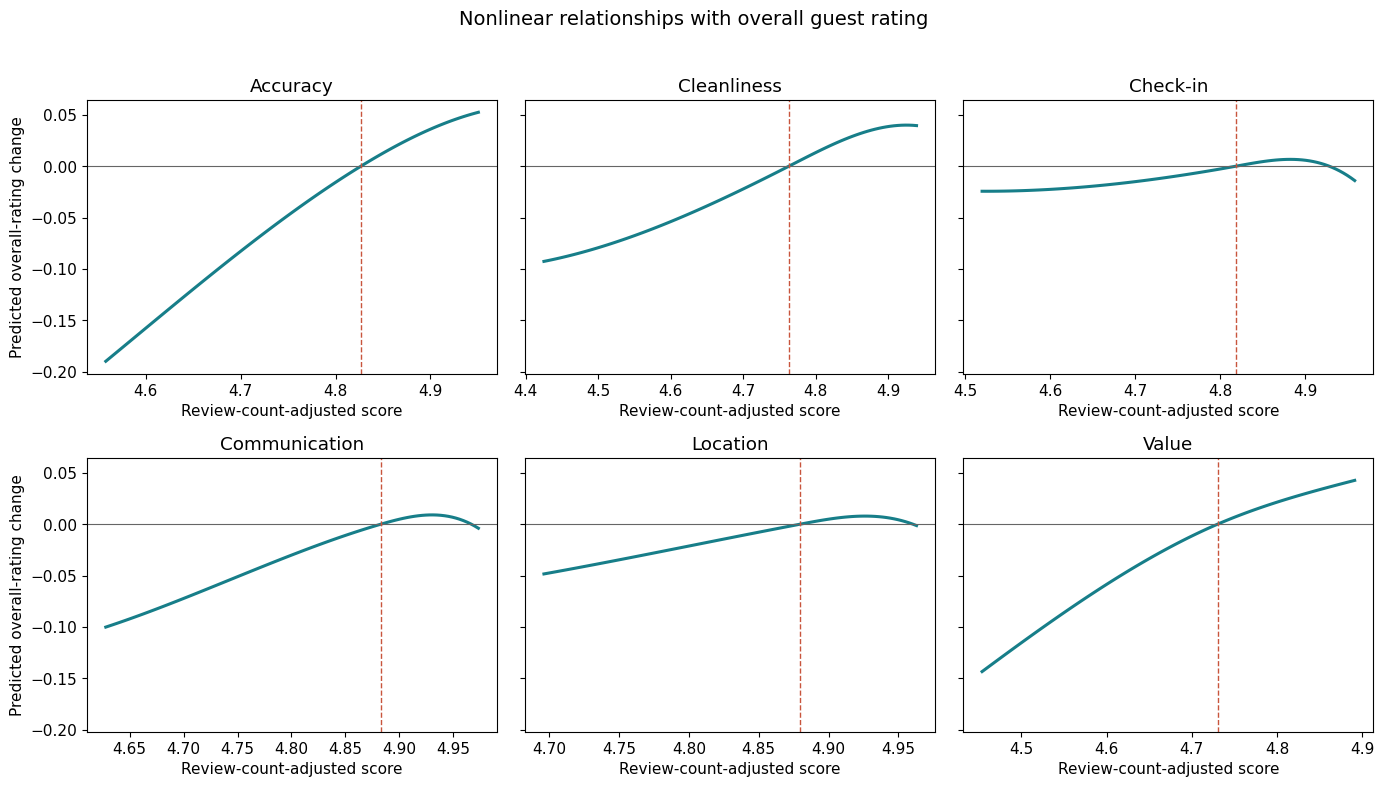

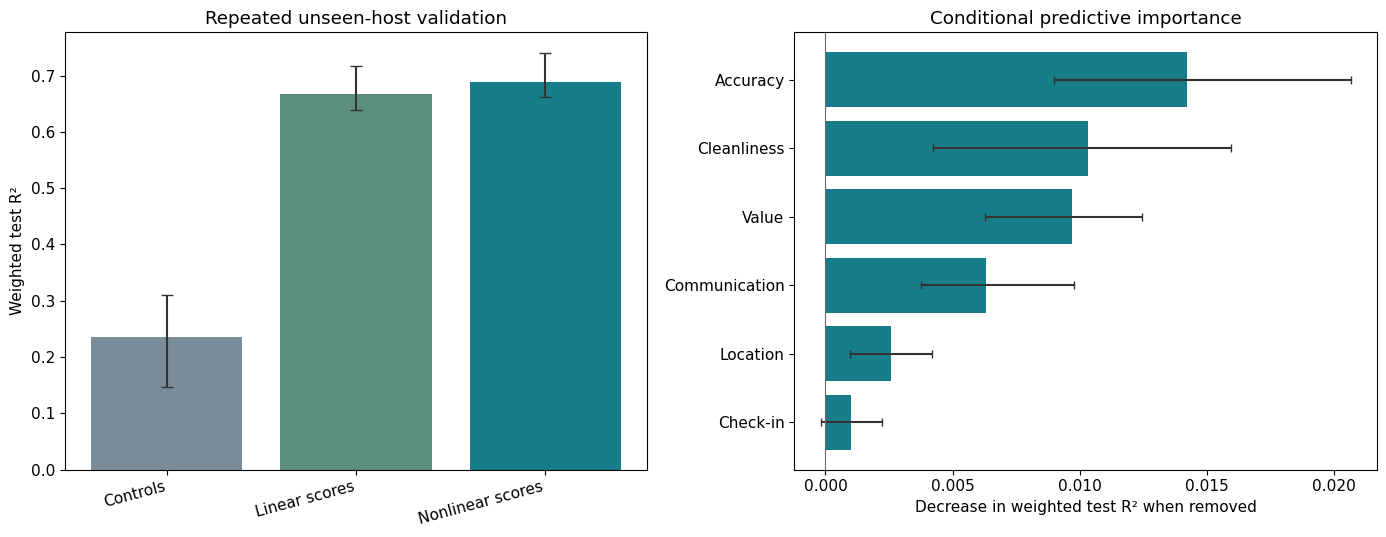

In [44]:
# Fit the final nonlinear model to all eligible listings for partial-effect curves.
sqrt_full_weight = np.sqrt(review_weights)
full_targets = np.column_stack([review_outcome, review_nonlinear_design])
full_control_coefficients = np.linalg.lstsq(
    review_control_design * sqrt_full_weight[:, None],
    full_targets * sqrt_full_weight[:, None],
    rcond=None,
)[0]
full_residuals = full_targets - review_control_design @ full_control_coefficients
_, full_spline_coefficients = fit_small_weighted_model(
    full_residuals[:, 0],
    full_residuals[:, 1:],
    full_residuals[:, 1:],
    review_weights,
)

curve_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for axis, (label, column) in zip(axes.flat, adjusted_score_columns.items()):
    lower, upper = review_data[column].quantile([0.025, 0.975])
    grid = np.linspace(lower, upper, 100)
    reference = review_data[column].median()
    grid_basis = np.asarray(build_design_matrices(
        [spline_design_info[label]], pd.DataFrame({column: grid})
    )[0], dtype=float)
    reference_basis = np.asarray(build_design_matrices(
        [spline_design_info[label]], pd.DataFrame({column: [reference]})
    )[0], dtype=float)
    block_slice = spline_slices[label]
    predicted_change = (
        (grid_basis - reference_basis) @ full_spline_coefficients[block_slice]
    )
    axis.plot(grid, predicted_change, color="#177E89", linewidth=2.2)
    axis.axhline(0, color="#666666", linewidth=0.8)
    axis.axvline(reference, color="#C8553D", linewidth=1.0, linestyle="--")
    axis.set_title(label)
    axis.set_xlabel("Review-count-adjusted score")
    curve_rows.extend({
        "review_aspect": label,
        "adjusted_score": score,
        "predicted_overall_rating_change_vs_median": change,
        "reference_score": reference,
    } for score, change in zip(grid, predicted_change))
axes[0, 0].set_ylabel("Predicted overall-rating change")
axes[1, 0].set_ylabel("Predicted overall-rating change")
fig.suptitle("Nonlinear relationships with overall guest rating", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(COMPREHENSIVE_OUTPUT / "review_score_nonlinear_curves.png", dpi=170, bbox_inches="tight")
plt.show()
review_score_curves = pd.DataFrame(curve_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
validation_plot = review_validation.copy()
x = np.arange(len(validation_plot))
r2_mean = validation_plot["weighted_test_R2_mean"].to_numpy()
r2_low = validation_plot["weighted_test_R2_low"].to_numpy()
r2_high = validation_plot["weighted_test_R2_high"].to_numpy()
axes[0].bar(x, r2_mean, color=["#7A8B99", "#5B8E7D", "#177E89"])
axes[0].errorbar(
    x, r2_mean, xerr=None,
    yerr=np.vstack([r2_mean-r2_low, r2_high-r2_mean]),
    fmt="none", ecolor="#333333", capsize=4,
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Controls", "Linear scores", "Nonlinear scores"], rotation=15, ha="right")
axes[0].set_ylabel("Weighted test R²")
axes[0].set_title("Repeated unseen-host validation")

importance_plot = review_importance.sort_values("mean_R2_loss_when_removed")
y = np.arange(len(importance_plot))
loss = importance_plot["mean_R2_loss_when_removed"].to_numpy()
loss_low = importance_plot["R2_loss_low"].to_numpy()
loss_high = importance_plot["R2_loss_high"].to_numpy()
axes[1].barh(y, loss, color="#177E89")
axes[1].errorbar(
    loss, y,
    xerr=np.vstack([loss-loss_low, loss_high-loss]),
    fmt="none", ecolor="#333333", capsize=3,
)
axes[1].axvline(0, color="#666666", linewidth=0.8)
axes[1].set_yticks(y)
axes[1].set_yticklabels(importance_plot["review_aspect"])
axes[1].set_xlabel("Decrease in weighted test R² when removed")
axes[1].set_title("Conditional predictive importance")
fig.tight_layout()
fig.savefig(COMPREHENSIVE_OUTPUT / "review_score_importance.png", dpi=170, bbox_inches="tight")
plt.show()


In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
cols = list(adjusted_score_columns.values())
X = review_data[cols].assign(const=1.0)
vif = pd.DataFrame({
    "review_aspect": list(adjusted_score_columns.keys()),
    "VIF": [variance_inflation_factor(X.values, i) for i in range(len(cols))],
})
display(review_data[cols].corr().round(2))
display(vif.round(2))

,adjusted_review_scores_accuracy,adjusted_review_scores_cleanliness,adjusted_review_scores_checkin,adjusted_review_scores_communication,adjusted_review_scores_location,adjusted_review_scores_value
adjusted_review_scores_accuracy,1.00,0.82,0.62,0.77,0.57,0.87
adjusted_review_scores_cleanliness,0.82,1.00,0.59,0.68,0.45,0.79
adjusted_review_scores_checkin,0.62,0.59,1.00,0.71,0.32,0.63
adjusted_review_scores_communication,0.77,0.68,0.71,1.00,0.47,0.77
adjusted_review_scores_location,0.57,0.45,0.32,0.47,1.00,0.57
adjusted_review_scores_value,0.87,0.79,0.63,0.77,0.57,1.00


,review_aspect,VIF
0,Accuracy,5.85
1,Cleanliness,3.39
2,Check-in,2.15
3,Communication,3.32
4,Location,1.55
5,Value,5.04


### Interpretation

The host-grouped results determine whether the extra score information generalises beyond listings from the same hosts. Improvement from the linear to the spline model supports retaining nonlinear relationships rather than assuming that every 0.1-star change has the same meaning. The curve panels show the adjusted association relative to each category's median; the dashed line marks that median.

The conditional-importance bars answer a stricter question: how much unseen-host predictive performance is lost when one complete score curve is removed while the other five remain. Their error bars show the 2.5th–97.5th percentile across the ten validation splits, not causal confidence intervals. A category can appear weak because it overlaps with another category, and curves near the sparse ends of the score range should not be extrapolated. The result supports a guest-experience priority, not a claim about Airbnb's undisclosed ranking weights or a guaranteed revenue increase. During validation, score-shrinkage means, suburb groups and spline knots are learned from each training split and then applied to its test set.

## 15. Minimum-night policy

**Question:** what minimum-night setting is associated with the strongest demand and estimated revenue after controlling for listing and host characteristics?

The primary outcome is `number_of_reviews_ltm`, modelled as `log1p(reviews)`. This avoids using the project’s review-derived occupied-night proxy, whose assumed stay length partly depends on minimum nights and would create a circular comparison. Inside Airbnb estimated revenue is retained as a secondary sensitivity outcome.

The exposure is the calendar-derived average minimum-night rule, restricted to the project’s short-stay scope. A cubic spline allows a nonlinear relationship. Counterfactual standardisation predicts 1-, 2-, 3-, 5- and 7-night settings while keeping the observed property, suburb, amenity and host composition unchanged. These are observational adjusted associations, not evidence that changing a host’s rule will cause the predicted result.

In [46]:
minstay_controls = [
    "np.log1p(accommodates)", "bedrooms", "beds", "bathrooms_n", "bathroom_shared",
    "bedrooms_missing", "beds_missing", "bathrooms_missing", "distance_to_cbd_km",
    "amenity_count", "is_superhost", "np.log1p(calculated_host_listings_count)",
    "C(property_type_model)", "C(suburb)",
]
minstay_control_rhs = " + ".join(minstay_controls)
minstay_data = model_df.replace([np.inf, -np.inf], np.nan).dropna(subset=[
    "average_minimum_nights", "number_of_reviews_ltm", "log_inside_airbnb_revenue",
    "host_cluster_id", "amenity_count", "distance_to_cbd_km", "property_type_model", "suburb",
]).copy()
minstay_data = minstay_data.loc[
    minstay_data["average_minimum_nights"].between(1, 27, inclusive="both")
].copy()
minstay_data["log1p_reviews_ltm"] = np.log1p(minstay_data["number_of_reviews_ltm"])
minstay_data["policy_group"] = pd.cut(
    minstay_data["average_minimum_nights"],
    bins=[0, 1.5, 2.5, 3.5, 6.5, 27],
    labels=["About 1 night", "About 2 nights", "About 3 nights", "About 4–6 nights", "About 7–27 nights"],
    include_lowest=True,
)
minstay_support = (
    minstay_data.groupby("policy_group", observed=True)
    .agg(
        listings=("id", "size"), hosts=("host_cluster_id", "nunique"),
        median_average_minimum_nights=("average_minimum_nights", "median"),
        median_reviews_ltm=("number_of_reviews_ltm", "median"),
        median_inside_revenue_aud=("estimated_revenue_l365d", "median"),
    )
    .reset_index()
)

policy_term = "bs(np.log1p(average_minimum_nights), df=4, degree=3)"
demand_formula = f"log1p_reviews_ltm ~ {policy_term} + {minstay_control_rhs}"
revenue_policy_formula = f"log_inside_airbnb_revenue ~ {policy_term} + {minstay_control_rhs}"
demand_policy_model = smf.ols(demand_formula, data=minstay_data).fit(
    cov_type="cluster", cov_kwds={"groups": minstay_data["host_cluster_id"]}
)
revenue_policy_model = smf.ols(revenue_policy_formula, data=minstay_data).fit(
    cov_type="cluster", cov_kwds={"groups": minstay_data["host_cluster_id"]}
)

def joint_policy_p_value(fitted):
    terms = [name for name in fitted.params.index if name.startswith("bs(")]
    restriction = np.zeros((len(terms), len(fitted.params)))
    locations = {name: i for i, name in enumerate(fitted.params.index)}
    for row, name in enumerate(terms):
        restriction[row, locations[name]] = 1
    return float(fitted.wald_test(restriction, scalar=True).pvalue)

policy_tests = pd.DataFrame({
    "outcome": ["Reviews in last 12 months", "Inside Airbnb estimated revenue"],
    "joint_spline_p_value": [
        joint_policy_p_value(demand_policy_model), joint_policy_p_value(revenue_policy_model)
    ],
})
policy_tests["q_value_BH"] = multipletests(policy_tests["joint_spline_p_value"], method="fdr_bh")[1]

scenario_days = [1, 2, 3, 5, 7]
demand_smearing = float(np.exp(demand_policy_model.resid).mean())
revenue_smearing = float(np.exp(revenue_policy_model.resid).mean())
scenario_rows = []
for days in scenario_days:
    scenario = minstay_data.copy()
    scenario["average_minimum_nights"] = days
    adjusted_reviews = np.maximum(
        np.exp(demand_policy_model.predict(scenario)) * demand_smearing - 1, 0
    ).mean()
    adjusted_revenue = (
        np.exp(revenue_policy_model.predict(scenario)) * revenue_smearing
    ).mean()
    scenario_rows.append({
        "minimum_nights_scenario": days,
        "adjusted_mean_reviews_ltm": adjusted_reviews,
        "adjusted_mean_inside_revenue_aud": adjusted_revenue,
    })
minnight_scenarios = pd.DataFrame(scenario_rows)
baseline_reviews = float(minnight_scenarios.loc[
    minnight_scenarios.minimum_nights_scenario.eq(2), "adjusted_mean_reviews_ltm"
].iloc[0])
baseline_revenue_policy = float(minnight_scenarios.loc[
    minnight_scenarios.minimum_nights_scenario.eq(2), "adjusted_mean_inside_revenue_aud"
].iloc[0])
minnight_scenarios["reviews_vs_2_nights_pct"] = (
    minnight_scenarios["adjusted_mean_reviews_ltm"] / baseline_reviews - 1
) * 100
minnight_scenarios["revenue_vs_2_nights_pct"] = (
    minnight_scenarios["adjusted_mean_inside_revenue_aud"] / baseline_revenue_policy - 1
) * 100

display(minstay_support.round(2))
display(policy_tests.round(4))
display(minnight_scenarios.round(2))


,policy_group,listings,hosts,median_average_minimum_nights,median_reviews_ltm,median_inside_revenue_aud
0,About 1 night,2553,1305,1.00,16.0,25344.0
1,About 2 nights,4041,2432,2.00,13.0,22218.0
2,About 3 nights,2352,1212,3.00,11.0,18957.0
3,About 4–6 nights,1846,724,4.00,10.0,17964.0
4,About 7–27 nights,678,382,12.74,5.0,12931.0


,outcome,joint_spline_p_value,q_value_BH
0,Reviews in last 12 months,0.0,0.0
1,Inside Airbnb estimated revenue,0.0,0.0


,minimum_nights_scenario,adjusted_mean_reviews_ltm,adjusted_mean_inside_revenue_aud,reviews_vs_2_nights_pct,revenue_vs_2_nights_pct
0,1,24.35,38556.36,36.64,28.45
1,2,17.82,30017.35,0.00,0.00
2,3,16.06,26768.76,-9.84,-10.82
3,5,12.25,23290.70,-31.24,-22.41
4,7,9.92,21734.59,-44.31,-27.59


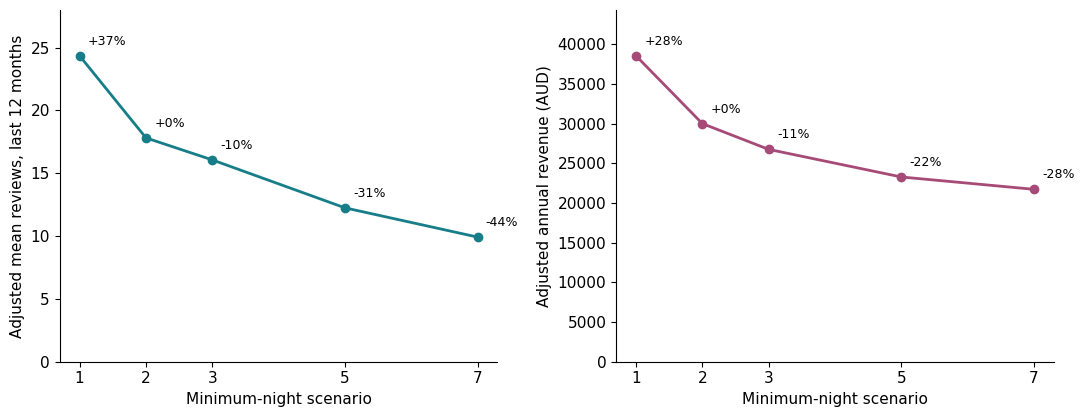

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
panels = [
    ("adjusted_mean_reviews_ltm", "reviews_vs_2_nights_pct", "#177E89",
     "Adjusted mean reviews, last 12 months"),
    ("adjusted_mean_inside_revenue_aud", "revenue_vs_2_nights_pct", "#A64B78",
     "Adjusted annual revenue (AUD)"),
]
for ax, (col, pct, color, ylabel) in zip(axes, panels):
    x = minnight_scenarios["minimum_nights_scenario"]
    y = minnight_scenarios[col]
    ax.plot(x, y, marker="o", color=color, linewidth=2)
    for xi, yi, p in zip(x, y, minnight_scenarios[pct]):
        ax.annotate(f"{p:+.0f}%", (xi, yi), xytext=(6, 8),
                    textcoords="offset points", fontsize=9)
    ax.set(xlabel="Minimum-night scenario", ylabel=ylabel, xticks=list(x))
    ax.set_ylim(0, y.max() * 1.15)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(COMPREHENSIVE_OUTPUT / "minimum_night_scenarios.png",
            dpi=200, bbox_inches="tight")
plt.show()

## 16. Revenue-first seasonal complement

**Question:** when demand is weakest for the strongest acquisition-adjusted opportunity, which supported second segment offers the best combination of low-season demand and estimated gross yield?

The primary segment is the highest estimated gross-yield result with **Strong** evidence. Monthly demand is measured as dated review events per fixed-cohort listing per calendar day, which avoids favouring a suburb simply because it contains more listings or because months have different lengths. The 36 complete months run from June 2023 to May 2026; June 2026 is excluded because the scrape occurred mid-month.

The first 24 months identify the primary segment's weakest season. Candidate second investments must have Strong revenue evidence, a valid two-bedroom acquisition proxy, at least 30 established listings, at least 15 hosts, at least 20 median monthly reviews, and stronger demand than the primary segment during that weak season. Among candidates passing those conditions, the highest estimated gross yield is selected. The following-year check, June 2025 to May 2026, then examines whether the low-season advantage persists and whether an equal-normalised two-segment activity index is less variable than the primary segment alone.

This is a seasonal demand-balance analysis, not proof of financial diversification. Reviews are an imperfect demand proxy, and group-level stability does not guarantee stable cash flow for two individual properties.

### What the seasonal figures compare

This is a descriptive comparison, not a fitted seasonal forecasting model. The measured outcome is dated review events per fixed-cohort listing per calendar day, displayed on a 30-day scale. Comparison dimensions are the selected suburb and property format, Australian season, and observation window. Summer is December to February and winter is June to August.

Each location receives an equivalent seasonal panel with the same seasons, periods, units and vertical scale. A second grouped-bar figure directly compares both locations during the primary property's weakest season, using the same denominators and period definitions. Cohort sizes are disclosed. Higher winter activity than the primary property does not require the complement to have its own annual demand peak in winter.

The earlier 24 months determine the seasonal comparison and candidate choice. Review-volume eligibility still uses all 36 months and acquisition/revenue estimates use the current snapshot. The final year is therefore a following-year seasonal check, not a completely untouched historical investment backtest. It is separate from unseen-host revenue-model validation.


In [48]:
# Build the fixed-cohort seasonal panel directly from the project's cleaned scope.
SEASON_ORDER = ["Summer", "Autumn", "Winter", "Spring"]
SEASONAL_MIN_LISTINGS = 30
SEASONAL_MIN_HOSTS = 15
SEASONAL_MIN_MEDIAN_MONTHLY_REVIEWS = 20
SEASONAL_TRAIN_MONTHS = 24

def australian_season(month_number):
    if month_number in (12, 1, 2):
        return "Summer"
    if month_number in (3, 4, 5):
        return "Autumn"
    if month_number in (6, 7, 8):
        return "Winter"
    return "Spring"

def coefficient_of_variation(values):
    values = pd.Series(values, dtype=float)
    return float(values.std(ddof=1) / values.mean())

# Use only listings that entered the completed recommendation model. This keeps
# the seasonal analysis aligned with the client, activity and price scope above.
seasonal_listings = listings_clean.loc[
    listings_clean["id"].astype("string").isin(recommendation_data["id"].astype("string"))
].copy()
seasonal_listings["id"] = seasonal_listings["id"].astype("string")
seasonal_listings["host_cluster_id"] = seasonal_listings["host_cluster_id"].astype("string")
seasonal_listings["last_scraped"] = pd.to_datetime(
    seasonal_listings["last_scraped"], errors="coerce"
)
seasonal_listings["client_property_format"] = seasonal_listings[
    "property_type"
].map(client_property_format)
seasonal_listings["suburb_property_combination"] = (
    seasonal_listings["suburb"].astype(str).str.title()
    + " | "
    + seasonal_listings["client_property_format"].astype(str)
)

seasonal_reviews = pd.read_csv(
    REVIEWS_PATH,
    usecols=["listing_id", "id", "date"],
    dtype={"listing_id": "string", "id": "string"},
)
seasonal_reviews = seasonal_reviews.drop_duplicates("id").copy()
seasonal_reviews["date"] = pd.to_datetime(seasonal_reviews["date"], errors="coerce")
seasonal_scrape_lookup = seasonal_listings.set_index("id")["last_scraped"]
seasonal_reviews["last_scraped"] = seasonal_reviews["listing_id"].map(
    seasonal_scrape_lookup
)
seasonal_reviews = seasonal_reviews.loc[
    seasonal_reviews["date"].notna()
    & seasonal_reviews["last_scraped"].notna()
    & seasonal_reviews["date"].le(seasonal_reviews["last_scraped"])
].copy()

seasonal_last_complete_month = seasonal_listings["last_scraped"].min().to_period("M") - 1
seasonal_months = pd.period_range(
    end=seasonal_last_complete_month, periods=36, freq="M"
)
seasonal_first_review = seasonal_reviews.groupby("listing_id")["date"].min()
seasonal_listings["observed_first_review"] = seasonal_listings["id"].map(
    seasonal_first_review
)
seasonal_fixed_cohort = seasonal_listings.loc[
    seasonal_listings["observed_first_review"].lt(seasonal_months[0].start_time)
    & seasonal_listings["client_property_format"].isin([
        "Whole house", "Whole apartment/unit", "Whole townhouse"
    ])
].copy()

seasonal_support = seasonal_fixed_cohort.groupby(
    "suburb_property_combination", observed=True
).agg(
    fixed_cohort_listings=("id", "size"),
    fixed_cohort_hosts=("host_cluster_id", "nunique"),
)
seasonal_reviews["month"] = seasonal_reviews["date"].dt.to_period("M")
seasonal_joined = seasonal_reviews.loc[
    seasonal_reviews["month"].isin(seasonal_months)
].merge(
    seasonal_fixed_cohort[["id", "suburb_property_combination"]],
    left_on="listing_id",
    right_on="id",
    how="inner",
    validate="many_to_one",
)
seasonal_counts = pd.crosstab(
    seasonal_joined["month"],
    seasonal_joined["suburb_property_combination"],
).reindex(index=seasonal_months, columns=seasonal_support.index, fill_value=0)
seasonal_support["median_monthly_reviews"] = seasonal_counts.median()
seasonal_support["total_reviews_36m"] = seasonal_counts.sum()
seasonal_support["seasonal_support_pass"] = (
    seasonal_support["fixed_cohort_listings"].ge(SEASONAL_MIN_LISTINGS)
    & seasonal_support["fixed_cohort_hosts"].ge(SEASONAL_MIN_HOSTS)
    & seasonal_support["median_monthly_reviews"].ge(
        SEASONAL_MIN_MEDIAN_MONTHLY_REVIEWS
    )
)

seasonal_supported_segments = seasonal_support.index[
    seasonal_support["seasonal_support_pass"]
]
seasonal_counts = seasonal_counts.loc[:, seasonal_supported_segments]
seasonal_rate = seasonal_counts.div(
    seasonal_support.loc[seasonal_counts.columns, "fixed_cohort_listings"], axis=1
).div(seasonal_months.days_in_month, axis=0)

strong_roi_for_seasonality = roi_recommendations.loc[
    roi_recommendations["evidence_tier"].eq("Strong")
].copy()
seasonal_primary = strong_roi_for_seasonality.sort_values(
    "estimated_gross_yield_pct", ascending=False
).iloc[0]
seasonal_primary_segment = seasonal_primary["suburb_property_combination"]
if seasonal_primary_segment not in seasonal_rate.columns:
    raise ValueError(
        f"Highest-yield Strong segment lacks seasonal support: {seasonal_primary_segment}"
    )

season_labels = pd.Series(
    [australian_season(month.month) for month in seasonal_months],
    index=seasonal_months,
    name="season",
)
seasonal_train_rate = seasonal_rate.iloc[:SEASONAL_TRAIN_MONTHS]
seasonal_holdout_rate = seasonal_rate.iloc[SEASONAL_TRAIN_MONTHS:]
seasonal_train_labels = season_labels.iloc[:SEASONAL_TRAIN_MONTHS]
seasonal_holdout_labels = season_labels.iloc[SEASONAL_TRAIN_MONTHS:]
seasonal_train_profile = seasonal_train_rate.groupby(
    seasonal_train_labels, observed=True
).mean().reindex(SEASON_ORDER)
seasonal_holdout_profile = seasonal_holdout_rate.groupby(
    seasonal_holdout_labels, observed=True
).mean().reindex(SEASON_ORDER)

primary_peak_season = seasonal_train_profile[seasonal_primary_segment].idxmax()
primary_low_season = seasonal_train_profile[seasonal_primary_segment].idxmin()
primary_train_low_rate = seasonal_train_profile.loc[
    primary_low_season, seasonal_primary_segment
]
primary_holdout_low_rate = seasonal_holdout_profile.loc[
    primary_low_season, seasonal_primary_segment
]
primary_index = seasonal_rate[seasonal_primary_segment] / seasonal_train_rate[
    seasonal_primary_segment
].mean()

strong_roi_lookup = strong_roi_for_seasonality.set_index(
    "suburb_property_combination"
)
seasonal_candidate_rows = []
for candidate_segment in seasonal_rate.columns:
    if (
        candidate_segment == seasonal_primary_segment
        or candidate_segment not in strong_roi_lookup.index
    ):
        continue
    candidate_roi = strong_roi_lookup.loc[candidate_segment]
    candidate_index = seasonal_rate[candidate_segment] / seasonal_train_rate[
        candidate_segment
    ].mean()
    equal_normalised_pair = (primary_index + candidate_index) / 2
    candidate_train_low_rate = seasonal_train_profile.loc[
        primary_low_season, candidate_segment
    ]
    candidate_holdout_low_rate = seasonal_holdout_profile.loc[
        primary_low_season, candidate_segment
    ]
    seasonal_candidate_rows.append({
        "suburb_property_combination": candidate_segment,
        "suburb": candidate_roi["suburb"],
        "client_property_format": candidate_roi["client_property_format"],
        "evidence_tier": candidate_roi["evidence_tier"],
        "estimated_gross_yield_pct": candidate_roi["estimated_gross_yield_pct"],
        "gross_yield_rank": candidate_roi["gross_yield_rank"],
        "adjusted_predicted_revenue_aud": candidate_roi[
            "adjusted_predicted_revenue_aud"
        ],
        "acquisition_proxy_2br_aud": candidate_roi["acquisition_proxy_2br_aud"],
        "fixed_cohort_listings": seasonal_support.loc[
            candidate_segment, "fixed_cohort_listings"
        ],
        "fixed_cohort_hosts": seasonal_support.loc[
            candidate_segment, "fixed_cohort_hosts"
        ],
        "selection_low_season": primary_low_season,
        "selection_low_season_reviews_per_listing_day": candidate_train_low_rate,
        "selection_low_season_advantage_vs_primary_pct": 100 * (
            candidate_train_low_rate / primary_train_low_rate - 1
        ),
        "holdout_low_season_reviews_per_listing_day": candidate_holdout_low_rate,
        "holdout_low_season_advantage_vs_primary_pct": 100 * (
            candidate_holdout_low_rate / primary_holdout_low_rate - 1
        ),
        "selection_correlation_with_primary": seasonal_train_rate[
            seasonal_primary_segment
        ].corr(seasonal_train_rate[candidate_segment]),
        "holdout_correlation_with_primary": seasonal_holdout_rate[
            seasonal_primary_segment
        ].corr(seasonal_holdout_rate[candidate_segment]),
        "holdout_primary_cv": coefficient_of_variation(
            primary_index.iloc[SEASONAL_TRAIN_MONTHS:]
        ),
        "holdout_equal_pair_cv": coefficient_of_variation(
            equal_normalised_pair.iloc[SEASONAL_TRAIN_MONTHS:]
        ),
        "holdout_activity_variability_reduction_vs_primary_pct": 100 * (
            1
            - coefficient_of_variation(
                equal_normalised_pair.iloc[SEASONAL_TRAIN_MONTHS:]
            )
            / coefficient_of_variation(
                primary_index.iloc[SEASONAL_TRAIN_MONTHS:]
            )
        ),
    })

seasonal_candidate_evaluation = pd.DataFrame(seasonal_candidate_rows)
seasonal_candidate_evaluation["passes_low_season_demand_rule"] = (
    seasonal_candidate_evaluation[
        "selection_low_season_reviews_per_listing_day"
    ].gt(primary_train_low_rate)
)
eligible_seasonal_candidates = seasonal_candidate_evaluation.loc[
    seasonal_candidate_evaluation["passes_low_season_demand_rule"]
].copy()
if eligible_seasonal_candidates.empty:
    raise ValueError("No Strong candidate has better primary low-season demand.")

# The first 24 months define the low-season comparison. Review-volume eligibility
# uses all 36 months, and gross-yield ranking uses the current snapshot.
# The final 12 months provide a retrospective following-year check.
seasonal_secondary = eligible_seasonal_candidates.sort_values(
    ["estimated_gross_yield_pct", "selection_low_season_reviews_per_listing_day"],
    ascending=[False, False],
).iloc[0]
seasonal_secondary_segment = seasonal_secondary["suburb_property_combination"]

seasonal_profiles = pd.concat([
    seasonal_train_profile[[seasonal_primary_segment, seasonal_secondary_segment]]
    .reset_index(names="season")
    .melt(id_vars="season", var_name="suburb_property_combination", value_name="reviews_per_listing_day")
    .assign(period="Selection: Jun 2023–May 2025"),
    seasonal_holdout_profile[[seasonal_primary_segment, seasonal_secondary_segment]]
    .reset_index(names="season")
    .melt(id_vars="season", var_name="suburb_property_combination", value_name="reviews_per_listing_day")
    .assign(period="Holdout: Jun 2025–May 2026"),
], ignore_index=True)
seasonal_profiles["reviews_per_listing_30_days"] = (
    seasonal_profiles["reviews_per_listing_day"] * 30
)

primary_support_row = seasonal_support.loc[seasonal_primary_segment]
secondary_support_row = seasonal_support.loc[seasonal_secondary_segment]
seasonal_recommendation_summary = pd.DataFrame([
    {
        "role": "Primary acquisition",
        "suburb_property_combination": seasonal_primary_segment,
        "adjusted_predicted_revenue_aud": seasonal_primary[
            "adjusted_predicted_revenue_aud"
        ],
        "acquisition_proxy_2br_aud": seasonal_primary["acquisition_proxy_2br_aud"],
        "estimated_gross_yield_pct": seasonal_primary["estimated_gross_yield_pct"],
        "fixed_cohort_listings": primary_support_row["fixed_cohort_listings"],
        "fixed_cohort_hosts": primary_support_row["fixed_cohort_hosts"],
    },
    {
        "role": "Second acquisition for seasonal balance",
        "suburb_property_combination": seasonal_secondary_segment,
        "adjusted_predicted_revenue_aud": seasonal_secondary[
            "adjusted_predicted_revenue_aud"
        ],
        "acquisition_proxy_2br_aud": seasonal_secondary["acquisition_proxy_2br_aud"],
        "estimated_gross_yield_pct": seasonal_secondary[
            "estimated_gross_yield_pct"
        ],
        "fixed_cohort_listings": secondary_support_row["fixed_cohort_listings"],
        "fixed_cohort_hosts": secondary_support_row["fixed_cohort_hosts"],
    },
])

combined_revenue = seasonal_recommendation_summary[
    "adjusted_predicted_revenue_aud"
].sum()
combined_acquisition = seasonal_recommendation_summary[
    "acquisition_proxy_2br_aud"
].sum()
seasonal_validation_summary = pd.DataFrame({
    "metric": [
        "analysis window",
        "selection window",
        "holdout window",
        "primary peak season in selection window",
        "primary weakest season in selection window",
        "secondary selection rule",
        "secondary low-season advantage in selection window",
        "secondary low-season advantage in holdout",
        "holdout activity correlation",
        "holdout equal-pair variability reduction vs primary",
        "illustrative combined acquisition proxy",
        "illustrative combined adjusted annual revenue",
        "illustrative combined gross-yield proxy",
    ],
    "value": [
        f"{seasonal_months[0]} to {seasonal_months[-1]}",
        f"{seasonal_months[0]} to {seasonal_months[SEASONAL_TRAIN_MONTHS - 1]}",
        f"{seasonal_months[SEASONAL_TRAIN_MONTHS]} to {seasonal_months[-1]}",
        primary_peak_season,
        primary_low_season,
        "Highest Strong gross yield among candidates with better primary low-season demand",
        seasonal_secondary["selection_low_season_advantage_vs_primary_pct"],
        seasonal_secondary["holdout_low_season_advantage_vs_primary_pct"],
        seasonal_secondary["holdout_correlation_with_primary"],
        seasonal_secondary[
            "holdout_activity_variability_reduction_vs_primary_pct"
        ],
        combined_acquisition,
        combined_revenue,
        combined_revenue / combined_acquisition * 100,
    ],
})

display(seasonal_recommendation_summary.round(3))
display(seasonal_validation_summary)
display(
    eligible_seasonal_candidates.sort_values(
        "estimated_gross_yield_pct", ascending=False
    )[[
        "suburb_property_combination", "estimated_gross_yield_pct",
        "selection_low_season_advantage_vs_primary_pct",
        "holdout_low_season_advantage_vs_primary_pct",
        "holdout_correlation_with_primary",
        "holdout_activity_variability_reduction_vs_primary_pct",
    ]].head(10).round(3)
)

del seasonal_reviews, seasonal_joined
gc.collect()

,role,suburb_property_combination,adjusted_predicted_revenue_aud,acquisition_proxy_2br_aud,estimated_gross_yield_pct,fixed_cohort_listings,fixed_cohort_hosts
0,Primary acquisition,Collingwood | Whole apartment/unit,27532.766,630000.000,4.370,43,38
1,Second acquisition for seasonal balance,Healesville | Whole house,26299.403,678991.597,3.873,50,41


,metric,value
0,analysis window,2023-06 to 2026-05
1,selection window,2023-06 to 2025-05
2,holdout window,2025-06 to 2026-05
3,primary peak season in selection window,Spring
4,primary weakest season in selection window,Winter
5,secondary selection rule,Highest Strong gross yield among candidates with better prima...
6,secondary low-season advantage in selection window,26.238691
7,secondary low-season advantage in holdout,50.28974
8,holdout activity correlation,0.025474
9,holdout equal-pair variability reduction vs primary,40.642483


,suburb_property_combination,estimated_gross_yield_pct,selection_low_season_advantage_vs_primary_pct,holdout_low_season_advantage_vs_primary_pct,holdout_correlation_with_primary,holdout_activity_variability_reduction_vs_primary_pct
2,Healesville | Whole house,3.873,26.239,50.290,0.025,40.642
3,Melbourne | Whole apartment/unit,3.861,43.268,48.490,0.769,31.201
7,Warburton | Whole house,3.269,11.457,27.615,-0.180,34.570
1,Fitzroy | Whole apartment/unit,3.242,25.502,29.391,0.700,19.196
6,Southbank | Whole apartment/unit,3.158,18.851,13.327,0.678,25.310
0,Docklands | Whole apartment/unit,3.155,45.738,37.022,0.611,23.950


34721

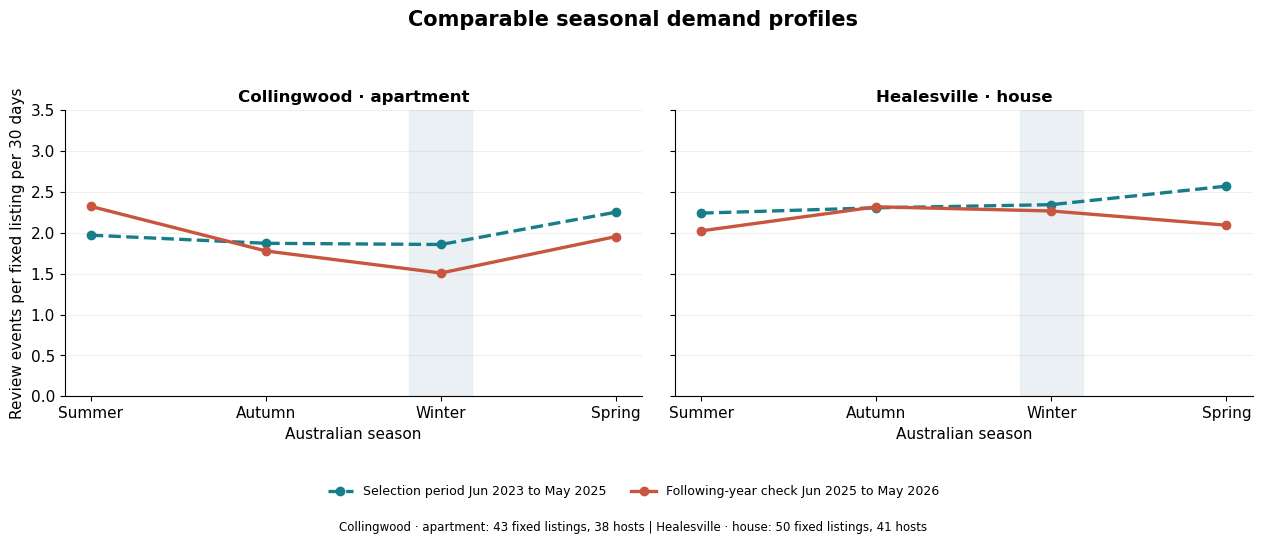

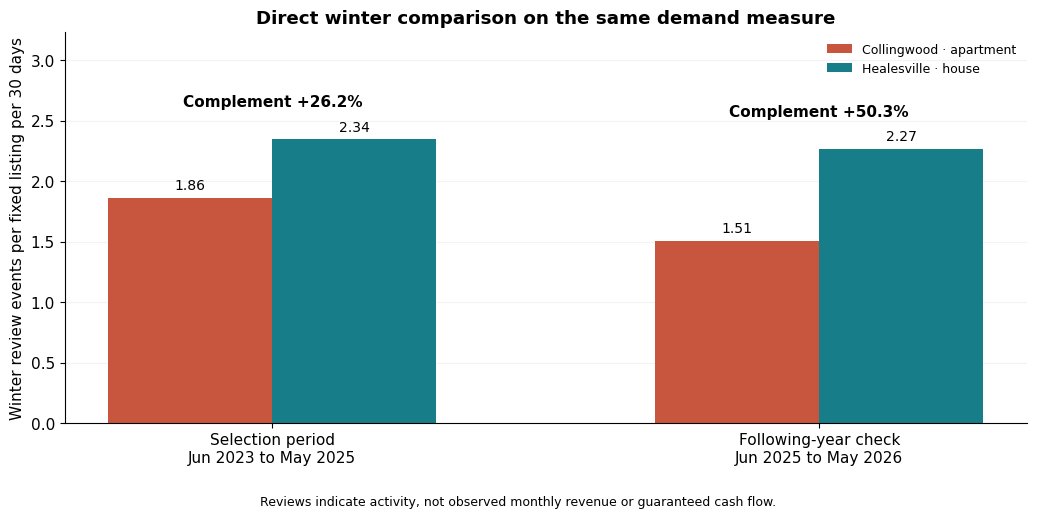

suburb_property_combination          Collingwood | Whole apartment/unit  \
period                       season                                       
Holdout: Jun 2025–May 2026   Autumn                               1.778   
                             Spring                               1.955   
                             Summer                               2.323   
                             Winter                               1.509   
Selection: Jun 2023–May 2025 Autumn                               1.872   
                             Spring                               2.253   
                             Summer                               1.971   
                             Winter                               1.857   

suburb_property_combination          Healesville | Whole house  
period                       season                             
Holdout: Jun 2025–May 2026   Autumn                      2.318  
                             Spring                      2.094  
                             Summer                      2.024  
                             Winter                      2.267  
Selection: Jun 2023–May 2025 Autumn                      2.306  
                             Spring                      2.572  
                             Summer                      2.241  
                             Winter                      2.345

In [49]:
SEASONAL_OUTPUT = DATA_DIR / "Testing" / "seasonal_complement"
SEASONAL_OUTPUT.mkdir(parents=True, exist_ok=True)

seasonal_chart_segments = [seasonal_primary_segment, seasonal_secondary_segment]
seasonal_chart_periods = ["Selection: Jun 2023–May 2025", "Holdout: Jun 2025–May 2026"]
seasonal_chart_period_labels = [
    "Selection period Jun 2023 to May 2025",
    "Following-year check Jun 2025 to May 2026",
]
seasonal_chart_period_colors = ["#177E89", "#C8553D"]
seasonal_chart_styles = ["--", "-"]
seasonal_chart_label = {
    seg: seg.replace(" | ", " · ")
    .replace("Whole apartment/unit", "apartment")
    .replace("Whole house", "house")
    .replace("Whole townhouse", "townhouse")
    for seg in seasonal_chart_segments
}
seasonal_chart_rates = seasonal_profiles.loc[
    seasonal_profiles["suburb_property_combination"].isin(seasonal_chart_segments)
].copy()
assert len(seasonal_chart_rates) == 16
seasonal_chart_ymax = (
    np.ceil(seasonal_chart_rates["reviews_per_listing_30_days"].max() * 1.18 * 2) / 2
)
seasonal_chart_support_note = " | ".join(
    f"{seasonal_chart_label[seg]}: {int(seasonal_support.loc[seg, 'fixed_cohort_listings'])} fixed listings, "
    f"{int(seasonal_support.loc[seg, 'fixed_cohort_hosts'])} hosts"
    for seg in seasonal_chart_segments
)

# Equivalent panels give Healesville exactly the same visual treatment.
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4), sharex=True, sharey=True)
for ax, seg in zip(axes, seasonal_chart_segments):
    for period, label, color, style in zip(
        seasonal_chart_periods,
        seasonal_chart_period_labels,
        seasonal_chart_period_colors,
        seasonal_chart_styles,
    ):
        block = (
            seasonal_chart_rates.loc[
                seasonal_chart_rates["suburb_property_combination"].eq(seg)
                & seasonal_chart_rates["period"].eq(period)
            ]
            .set_index("season")
            .reindex(SEASON_ORDER)
        )
        ax.plot(
            SEASON_ORDER,
            block["reviews_per_listing_30_days"],
            marker="o",
            linewidth=2.4,
            linestyle=style,
            color=color,
            label=label,
        )
    weak_position = SEASON_ORDER.index(primary_low_season)
    ax.axvspan(weak_position - 0.18, weak_position + 0.18, color="#E5EDF1", alpha=0.8, zorder=0)
    ax.set_title(seasonal_chart_label[seg], fontsize=12, fontweight="bold")
    ax.set_ylim(0, seasonal_chart_ymax)
    ax.set_xlabel("Australian season")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Review events per fixed listing per 30 days")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.055),
    ncol=2,
    frameon=False,
    fontsize=9,
)
fig.suptitle("Comparable seasonal demand profiles", fontsize=15, fontweight="bold", y=0.98)
fig.text(0.5, 0.015, seasonal_chart_support_note, ha="center", fontsize=8.5)
fig.tight_layout(rect=[0, 0.15, 1, 0.93])
fig.savefig(
    DATA_DIR / "seasonal_review_activity.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

# Direct same-season comparison in both periods; never compare total review counts.
seasonal_chart_winter = (
    seasonal_chart_rates.loc[seasonal_chart_rates["season"].eq(primary_low_season)]
    .pivot(
        index="period", columns="suburb_property_combination", values="reviews_per_listing_30_days"
    )
    .reindex(seasonal_chart_periods)
)
seasonal_chart_advantage = 100 * (
    seasonal_chart_winter[seasonal_secondary_segment]
    / seasonal_chart_winter[seasonal_primary_segment]
    - 1
)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
seasonal_chart_positions = np.arange(2)
seasonal_chart_width = 0.30
seasonal_chart_location_colors = ["#C8553D", "#177E89"]
for offset, seg, color in zip([-0.5, 0.5], seasonal_chart_segments, seasonal_chart_location_colors):
    values = seasonal_chart_winter[seg].to_numpy()
    bars = ax.bar(
        seasonal_chart_positions + offset * seasonal_chart_width,
        values,
        width=seasonal_chart_width,
        color=color,
        label=seasonal_chart_label[seg],
    )
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=4, fontsize=10)
for j, gain in enumerate(seasonal_chart_advantage):
    ax.text(
        j,
        seasonal_chart_winter.iloc[j].max() + 0.27,
        f"Complement +{gain:.1f}%",
        ha="center",
        fontweight="bold",
        fontsize=11,
    )
ax.set_xticks(
    seasonal_chart_positions,
    ["Selection period\nJun 2023 to May 2025", "Following-year check\nJun 2025 to May 2026"],
)
ax.set_ylim(0, seasonal_chart_winter.to_numpy().max() * 1.38)
ax.set_ylabel(f"{primary_low_season} review events per fixed listing per 30 days")
ax.set_title(
    f"Direct {primary_low_season.lower()} comparison on the same demand measure", fontweight="bold"
)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.text(
    0.5,
    0.015,
    "Reviews indicate activity, not observed monthly revenue or guaranteed cash flow.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(SEASONAL_OUTPUT / "low_season_demand_comparison.png", dpi=200, bbox_inches="tight")
fig.savefig(COMPREHENSIVE_OUTPUT / "low_season_demand_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

seasonal_chart_table = seasonal_chart_rates.pivot_table(
    index=["period", "season"],
    columns="suburb_property_combination",
    values="reviews_per_listing_30_days",
    aggfunc="first",
).reindex(columns=seasonal_chart_segments)
display(seasonal_chart_table.round(3))
seasonal_chart_table.to_csv(SEASONAL_OUTPUT / "comparable_seasonal_review_rates.csv")

### Report Figure 3

The figure used in the final report is rebuilt here from the same fixed-cohort seasonal rates, so every value it shows can be traced to this notebook. Only the low-season bars are labelled because those are the values discussed in the report.

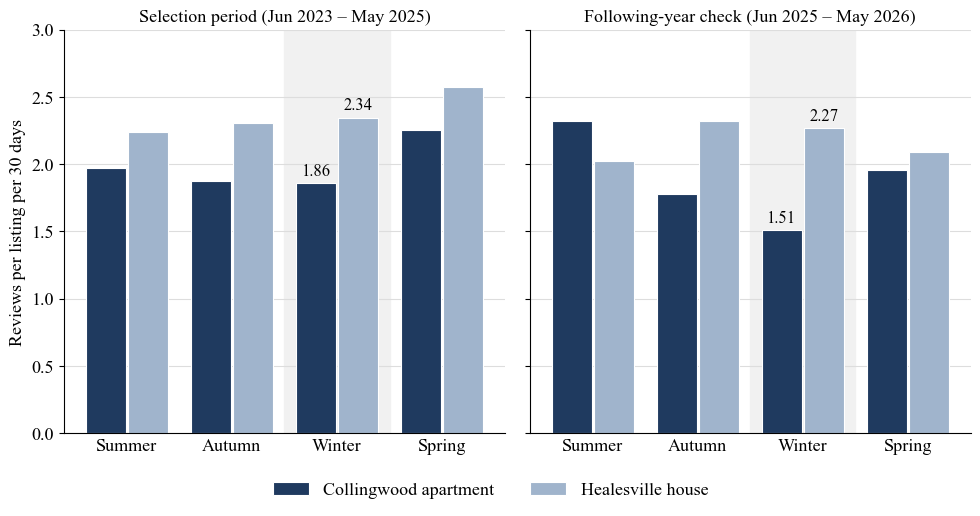

Low-season activity used in the report (reviews per listing per 30 days):


suburb_property_combination,Collingwood | Whole apartment/unit,Healesville | Whole house
period,,
Selection: Jun 2023–May 2025,1.86,2.34
Holdout: Jun 2025–May 2026,1.51,2.27


Low-season advantage of the complement (%): {'Selection: Jun 2023–May 2025': 26.2, 'Holdout: Jun 2025–May 2026': 50.3}


In [50]:
# Report Figure 3: seasonal review activity, Collingwood apartments vs Healesville houses.
# Uses the same fixed-cohort rates as the charts above (seasonal_chart_rates), so the
# report figure is reproduced directly from this notebook.
fig3_colors = {seasonal_primary_segment: "#1F3A5F", seasonal_secondary_segment: "#A0B4CC"}
fig3_titles = {
    "Selection: Jun 2023–May 2025": "Selection period (Jun 2023 – May 2025)",
    "Holdout: Jun 2025–May 2026": "Following-year check (Jun 2025 – May 2026)",
}
fig3_width = 0.38
fig3_x = np.arange(len(SEASON_ORDER))
fig3_low = SEASON_ORDER.index(primary_low_season)

with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 13,
}):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True)
    for ax, period in zip(axes, seasonal_chart_periods):
        ax.axvspan(fig3_low - 0.5, fig3_low + 0.5, color="#F1F1F1", zorder=0)
        for offset, seg in zip([-0.5, 0.5], seasonal_chart_segments):
            values = (
                seasonal_chart_rates.loc[
                    seasonal_chart_rates["suburb_property_combination"].eq(seg)
                    & seasonal_chart_rates["period"].eq(period)
                ]
                .set_index("season")
                .reindex(SEASON_ORDER)["reviews_per_listing_30_days"]
                .to_numpy()
            )
            bars = ax.bar(
                fig3_x + offset * fig3_width * 1.05,
                values,
                width=fig3_width,
                color=fig3_colors[seg],
                edgecolor="white",
                linewidth=0.8,
                label=seasonal_chart_label[seg].split(" · ")[0] + " " + seasonal_chart_label[seg].split(" · ")[1],
                zorder=2,
            )
            # Label only the low-season bars that the report discusses.
            ax.bar_label(
                bars,
                labels=[f"{v:.2f}" if i == fig3_low else "" for i, v in enumerate(values)],
                padding=3,
                fontsize=12,
            )
        ax.set_title(fig3_titles[period], fontsize=13)
        ax.set_xticks(fig3_x, SEASON_ORDER)
        ax.set_xlim(-0.6, len(SEASON_ORDER) - 0.4)
        ax.set_ylim(0, 3.0)
        ax.grid(axis="y", color="#DDDDDD", linewidth=0.8, zorder=1)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="x", length=0)
    axes[0].set_ylabel("Reviews per listing per 30 days")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    fig.savefig(DATA_DIR / "Figure3_seasonal_review_activity.png", dpi=600,
                bbox_inches="tight", facecolor="white")
    fig.savefig(SEASONAL_OUTPUT / "Figure3_seasonal_review_activity.png", dpi=600,
                bbox_inches="tight", facecolor="white")
    plt.show()

# Values quoted in the report text and Table F1.
fig3_winter = seasonal_chart_winter.round(2)
print("Low-season activity used in the report (reviews per listing per 30 days):")
display(fig3_winter)
print("Low-season advantage of the complement (%):", seasonal_chart_advantage.round(1).to_dict())

### Interpretation

The matched panels compare each location over the same seasons and periods with identical units and vertical scales. The direct low-season bars compare both locations in each period. They show whether the complement has stronger review activity during the primary property's historically weakest season, rather than comparing unlike charts or rewarding a larger listing population.

The second property is selected from candidates with stronger low-season review activity, then ranked by estimated gross yield. The following-year comparison checks persistence; it does not prove an opposite seasonal peak, future demand or stable cash flow. Any lower variability in the equal-normalised review-activity index describes group activity, not observed revenue from two purchased properties. Seasonal prices, booking values and operating costs are unavailable.

## 17. Consolidated findings and client implications

**Question:** what can the client reasonably act on after considering revenue, acquisition cost, amenities, review experience, minimum-night policy and seasonal demand balance together?

The table below is generated from the completed analyses. It separates supported findings from limitations rather than forcing every model to produce a recommendation.

In [51]:
best_revenue = primary_recommendations.iloc[0] if not primary_recommendations.empty else None
strong_roi = roi_recommendations.loc[roi_recommendations["evidence_tier"].eq("Strong")]
best_yield = (
    strong_roi.sort_values("estimated_gross_yield_pct", ascending=False).iloc[0]
    if not strong_roi.empty else roi_recommendations.sort_values("estimated_gross_yield_pct", ascending=False).iloc[0]
)
supported_amenities = amenity_effects.loc[amenity_effects["cross_checked"]]
best_amenity = supported_amenities.iloc[0] if not supported_amenities.empty else None
best_review = review_importance.iloc[0]
best_minimum = minnight_scenarios.sort_values("adjusted_mean_reviews_ltm", ascending=False).iloc[0]

finding_rows = []
if best_revenue is not None:
    finding_rows.append({
        "question": "Highest lower-bound revenue among Strong segments",
        "finding": f"{best_revenue['suburb']} — {best_revenue['client_property_format']}",
        "evidence": (
            f"${best_revenue['adjusted_predicted_revenue_aud']:,.0f}; "
            f"95% CI ${best_revenue['adjusted_revenue_ci_low_aud']:,.0f}–"
            f"${best_revenue['adjusted_revenue_ci_high_aud']:,.0f}; "
            f"{int(best_revenue['listings'])} listings/{int(best_revenue['unique_hosts'])} hosts"
        ),
        "client_interpretation": "Revenue-potential shortlist under the common scenario; not profit or ROI.",
    })
finding_rows.append({
    "question": "Primary acquisition recommendation",
    "finding": f"{best_yield['suburb']} — {best_yield['client_property_format']}",
    "evidence": (
        f"{best_yield['estimated_gross_yield_pct']:.2f}% gross-yield proxy; "
        f"${best_yield['adjusted_predicted_revenue_aud']:,.0f} adjusted annual revenue"
    ),
    "client_interpretation": "Highest Strong point-estimate gross-yield proxy; obtain a property valuation and full cost estimate before purchase.",
})
finding_rows.append({
    "question": "Second acquisition for seasonal demand balance",
    "finding": seasonal_secondary_segment.replace(" | ", " — "),
    "evidence": (
        f"{seasonal_secondary['estimated_gross_yield_pct']:.2f}% gross-yield proxy; "
        f"{seasonal_secondary['holdout_low_season_advantage_vs_primary_pct']:.1f}% "
        f"higher {primary_low_season.lower()} review activity than the primary segment in the following-year check"
    ),
    "client_interpretation": (
        f"Selected using earlier seasonal activity, 36-month review-volume eligibility and current yield estimates; the {seasonal_months[SEASONAL_TRAIN_MONTHS]}–"
        f"{seasonal_months[-1]} following-year check is retrospective and supports, but does not guarantee, more balanced seasonal activity."
    ),
})
finding_rows.append({
    "question": "Seasonal pair retrospective check",
    "finding": (
        f"{seasonal_primary_segment.replace(' | ', ' — ')} with "
        f"{seasonal_secondary_segment.replace(' | ', ' — ')}"
    ),
    "evidence": (
        f"Following-year correlation {seasonal_secondary['holdout_correlation_with_primary']:.3f}; "
        f"equal-normalised activity variability reduced "
        f"{seasonal_secondary['holdout_activity_variability_reduction_vs_primary_pct']:.1f}% "
        f"versus the primary segment alone"
    ),
    "client_interpretation": "Demand-proxy result at segment level; not a measured reduction in property cash-flow risk.",
})
finding_rows.append({
    "question": "Revenue and yield agreement",
    "finding": f"Spearman rank correlation {rank_test.statistic:.3f}; top-five overlap {len(top_revenue & top_yield)}/{top_n}",
    "evidence": f"{len(roi_recommendations)} combinations have aligned two-bedroom acquisition coverage",
    "client_interpretation": "Compares point-estimate ranks for all acquisition-covered supported combinations; it does not validate true ROI.",
})
finding_rows.append({
    "question": "Strongest cross-checked amenity association",
    "finding": best_amenity["amenity"] if best_amenity is not None else "No amenity passes both-outcome FDR and direction checks",
    "evidence": (
        f"Inside Airbnb revenue association {best_amenity['inside_effect_pct']:.1f}% (q={best_amenity['inside_q_value_BH']:.3g})"
        if best_amenity is not None else "Associations remain exploratory"
    ),
    "client_interpretation": "Use as a feature-testing priority, not a guaranteed installation return.",
})
finding_rows.append({
    "question": "Strongest conditional predictor of overall guest rating",
    "finding": best_review["review_aspect"],
    "evidence": (
        f"Mean unseen-host R² loss {best_review['mean_R2_loss_when_removed']:.4f} when removed; "
        f"positive loss in {best_review['positive_R2_loss_split_share']:.0%} of splits"
    ),
    "client_interpretation": "Predicts independently submitted overall experience after controls; not causal proof or an Airbnb algorithm weight.",
})
finding_rows.append({
    "question": "Minimum-night scenario with highest adjusted review activity",
    "finding": f"{int(best_minimum['minimum_nights_scenario'])} night(s)",
    "evidence": f"Adjusted mean {best_minimum['adjusted_mean_reviews_ltm']:.2f} reviews in the last 12 months",
    "client_interpretation": "Observational scenario; operational constraints and booking value still matter.",
})

final_findings = pd.DataFrame(finding_rows)

# Use AUD to avoid dollar signs being interpreted as mathematical notation.
final_findings["evidence"] = final_findings["evidence"].str.replace(
    "$", "AUD ", regex=False
)

with pd.option_context("display.max_colwidth", None):
    display(final_findings)

,question,finding,evidence,client_interpretation
0,Highest lower-bound revenue among Strong segments,Fitzroy — Whole apartment/unit,"AUD 26,100; 95% CI AUD 21,544–AUD 31,619; 113 listings/82 hosts",Revenue-potential shortlist under the common scenario; not profit or ROI.
1,Primary acquisition recommendation,Collingwood — Whole apartment/unit,"4.37% gross-yield proxy; AUD 27,533 adjusted annual revenue",Highest Strong point-estimate gross-yield proxy; obtain a property valuation and full cost estimate before purchase.
2,Second acquisition for seasonal demand balance,Healesville — Whole house,3.87% gross-yield proxy; 50.3% higher winter review activity than the primary segment in the following-year check,"Selected using earlier seasonal activity, 36-month review-volume eligibility and current yield estimates; the 2025-06–2026-05 following-year check is retrospective and supports, but does not guarantee, more balanced seasonal activity."
3,Seasonal pair retrospective check,Collingwood — Whole apartment/unit with Healesville — Whole house,Following-year correlation 0.025; equal-normalised activity variability reduced 40.6% versus the primary segment alone,Demand-proxy result at segment level; not a measured reduction in property cash-flow risk.
4,Revenue and yield agreement,Spearman rank correlation 0.548; top-five overlap 1/5,125 combinations have aligned two-bedroom acquisition coverage,Compares point-estimate ranks for all acquisition-covered supported combinations; it does not validate true ROI.
5,Strongest cross-checked amenity association,Smart Entry,Inside Airbnb revenue association 55.1% (q=0.044),"Use as a feature-testing priority, not a guaranteed installation return."
6,Strongest conditional predictor of overall guest rating,Accuracy,Mean unseen-host R² loss 0.0142 when removed; positive loss in 100% of splits,Predicts independently submitted overall experience after controls; not causal proof or an Airbnb algorithm weight.
7,Minimum-night scenario with highest adjusted review activity,1 night(s),Adjusted mean 24.35 reviews in the last 12 months,Observational scenario; operational constraints and booking value still matter.


In [52]:
# Save the new derived evidence. Raw Airbnb and official source files are unchanged.
exports = {
    "roi_recommendations": roi_recommendations,
    "roi_acquisition_coverage": roi_acquisition_coverage,
    "roi_crosscheck_summary": roi_crosscheck_summary,
    "amenity_effects_crosschecked": amenity_effects.reset_index(drop=True),
    "review_score_adjustment": review_adjustment_summary,
    "review_score_importance": review_importance,
    "review_score_validation": review_validation,
    "review_score_curves": review_score_curves,
    "minimum_night_support": minstay_support,
    "minimum_night_scenarios": minnight_scenarios,
    "minimum_night_model_tests": policy_tests,
    "seasonal_segment_support": seasonal_support.reset_index(),
    "seasonal_profiles": seasonal_profiles,
    "seasonal_candidate_evaluation": seasonal_candidate_evaluation,
    "seasonal_recommendation_summary": seasonal_recommendation_summary,
    "seasonal_validation_summary": seasonal_validation_summary,
    "final_findings": final_findings,
}
for filename, table in exports.items():
    table.to_csv(COMPREHENSIVE_OUTPUT / f"{filename}.csv", index=False)

print("Derived analysis outputs were written to Testing/comprehensive_analysis.")
print("Tables written:", len(exports))

Derived analysis outputs were written to Testing/comprehensive_analysis.
Tables written: 17


## 18. Assumptions and limitations

- Both annual-revenue measures are modelled from reviews and quoted price; neither is observed transaction revenue.
- The acquisition denominator is a suburb/class median adjusted by a bedroom-rent ratio. Exact or grouped DFFH markets are preferred; where neither exists, the model may use a published LGA-level DFFH market from `neighbourhood_cleansed` (for example, Yarra Ranges for Healesville and Warburton). This increases coverage but reduces local precision. It is not the sale price of an individual Airbnb property and does not adjust for bathrooms, floor area, condition, parking or exact address.
- Estimated gross revenue yield is not ROI or profit. Operating, transaction, financing and tax costs are absent.
- Amenity, review-score and minimum-night results are observational associations. Host choices and unobserved property quality may explain part of the relationships.
- Review scores are listing-level historical averages rather than individual category ratings. The 20-review shrinkage prior is transparent but still an assumption, and the lower rating range is sparse.
- Conditional score importance measures loss of unseen-host prediction when a score curve is removed. Correlated categories can share information, so the ranking is not an Airbnb algorithm weight or proof that changing one category will raise the overall rating.
- Airbnb states that ratings contribute to listing quality and search ranking, but impressions, ranking positions and bookings are unavailable. The path from overall rating to exposure and revenue is therefore not directly tested.
- Review activity is an imperfect demand proxy. Review propensity is unknown, and calendar unavailability may be booked or host-blocked.
- Airbnb coordinates are anonymised and may cross a nearby suburb boundary. Host-reported property types are not verified valuation classes.
- The seasonal analysis covers 36 complete months. The first 24 months define the seasonal comparison, while review-volume eligibility uses all 36 months and revenue and acquisition estimates use the current snapshot. June 2025 to May 2026 therefore provides a retrospective following-year check rather than an untouched investment backtest. One annual comparison offers limited evidence about future seasonal patterns.
- The seasonal pair combines normalised group review indices, not observed revenue from two purchased properties. Seasonal nightly prices, booking values, property-specific occupancy and operating costs are unavailable, so the reported variability reduction is descriptive rather than a cash-flow forecast.

Official acquisition sources: [Valuer-General Victoria property sales statistics](https://www.land.vic.gov.au/valuations/resources-and-reports/property-sales-statistics) and [Homes Victoria/DFFH Rental Report](https://www.dffh.vic.gov.au/publications/rental-report).

## Technical appendix Revenue scenario sensitivity across models

The main recommendations above use the retained log-linear regression. This appendix checks sensitivity to alternative model classes rather than presenting three competing client recommendations.

After evaluation, refit the frozen models on the full cohort and compare the same two-bedroom, one-bathroom, four-guest setup with a two-night minimum, a non-Superhost and one host listing. Acquisition proxies are unchanged. The tree predictions do not have equivalent host-clustered mean-revenue confidence intervals or the regression's significance-based evidence tiers.

Near-setup counts show observed two-bedroom, one-bathroom listings accommodating three to five guests. Rank agreement compares point predictions, not ranking stability across resampled training sets. Model disagreement remains a limitation even though only the retained regression drives the main recommendations.

,suburb_property_combination,near_setup_listings,purchase_proxy_2br_AUD,Log-linear regression_revenue_AUD,Random forest_revenue_AUD,Gradient boosting_revenue_AUD,Log-linear regression_gross_yield_pct,Random forest_gross_yield_pct,Gradient boosting_gross_yield_pct
41,Collingwood | Whole apartment/unit,24,630000.0,27531.80,12101.24,20368.79,4.37,1.92,3.23
61,Fitzroy | Whole apartment/unit,18,805000.0,26099.38,12037.52,20693.95,3.24,1.50,2.57
82,Healesville | Whole house,8,678991.6,26295.49,12037.52,20704.97,3.87,1.77,3.05


,model,Spearman_revenue_rank_agreement,top_10_point_revenue_overlap
0,Random forest,0.207,2
1,Gradient boosting,0.450,2


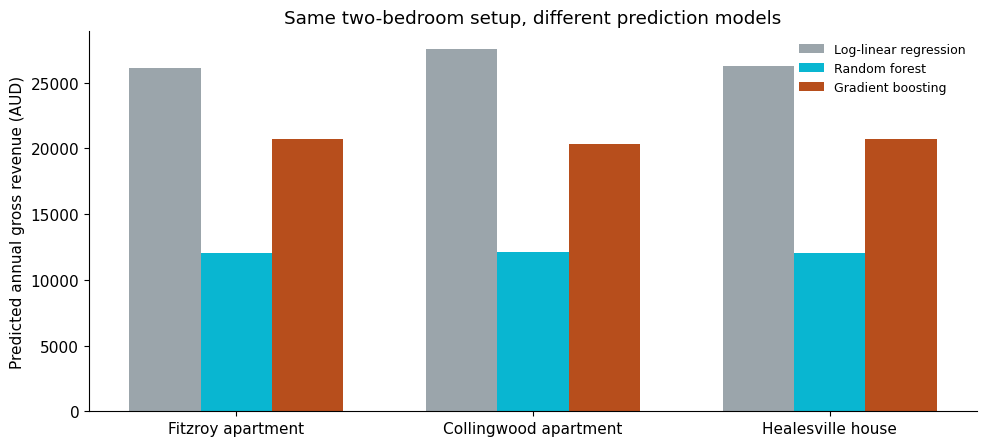

In [53]:
revenue_comparison_full_models = {}
for revenue_comparison_name, revenue_comparison_search in revenue_comparison_searches.items():
    revenue_comparison_full_models[revenue_comparison_name] = clone(
        revenue_comparison_search.best_estimator_
    ).fit(revenue_comparison_X, revenue_comparison_y)
revenue_comparison_supported = sorted(
    revenue_comparison_full_models["Log-linear regression"]
    .pipeline_.named_steps["prepare"]
    .supported_
)
revenue_comparison_scenario = pd.DataFrame(
    {
        "suburb_property_combination": revenue_comparison_supported,
        "accommodates": 4,
        "bedrooms": 2,
        "bathrooms_n": 1,
        "minimum_nights": 2,
        "minimum_nights_missing": 0,
        "is_superhost": 0,
        "calculated_host_listings_count": 1,
    }
)
revenue_comparison_scenario_comparison = revenue_comparison_scenario[
    ["suburb_property_combination"]
].copy()
for revenue_comparison_name, revenue_comparison_model in revenue_comparison_full_models.items():
    revenue_comparison_scenario_comparison[revenue_comparison_name + "_revenue_AUD"] = (
        revenue_comparison_model.predict(revenue_comparison_scenario)
    )
revenue_comparison_support = revenue_comparison_data.groupby("suburb_property_combination").agg(
    listings=("id", "size"), hosts=("host_cluster_id", "nunique")
)
revenue_comparison_near = (
    revenue_comparison_data.loc[
        revenue_comparison_data["bedrooms"].eq(2)
        & revenue_comparison_data["bathrooms_n"].eq(1)
        & revenue_comparison_data["accommodates"].between(3, 5)
    ]
    .groupby("suburb_property_combination")
    .size()
)
revenue_comparison_support["near_setup_listings"] = revenue_comparison_near.reindex(
    revenue_comparison_support.index, fill_value=0
)
revenue_comparison_scenario_comparison = revenue_comparison_scenario_comparison.merge(
    revenue_comparison_support,
    left_on="suburb_property_combination",
    right_index=True,
    validate="one_to_one",
)
revenue_comparison_benchmark["client_property_format"] = revenue_comparison_benchmark["id"].map(
    revenue_comparison_data.set_index("id")["client_property_format"]
)
revenue_comparison_benchmark["suburb_property_combination"] = (
    revenue_comparison_benchmark["suburb"].str.title()
    + " | "
    + revenue_comparison_benchmark["client_property_format"]
)
revenue_comparison_price_2br = (
    revenue_comparison_benchmark.loc[
        revenue_comparison_benchmark["bedrooms_benchmark"].eq(2)
        & revenue_comparison_benchmark["dwelling_class"].isin(["House", "Unit"])
        & revenue_comparison_benchmark["bedroom_adjusted_acquisition_price_proxy_aud"].gt(0)
    ]
    .groupby("suburb_property_combination")["bedroom_adjusted_acquisition_price_proxy_aud"]
    .median()
)
revenue_comparison_scenario_comparison["purchase_proxy_2br_AUD"] = (
    revenue_comparison_scenario_comparison["suburb_property_combination"].map(
        revenue_comparison_price_2br
    )
)
for revenue_comparison_name in revenue_comparison_full_models:
    revenue_comparison_scenario_comparison[revenue_comparison_name + "_gross_yield_pct"] = (
        revenue_comparison_scenario_comparison[revenue_comparison_name + "_revenue_AUD"]
        / revenue_comparison_scenario_comparison["purchase_proxy_2br_AUD"]
        * 100
    )
    revenue_comparison_scenario_comparison[revenue_comparison_name + "_revenue_rank"] = (
        revenue_comparison_scenario_comparison[revenue_comparison_name + "_revenue_AUD"].rank(
            ascending=False, method="min"
        )
    )
revenue_comparison_focus = [
    "Fitzroy | Whole apartment/unit",
    "Collingwood | Whole apartment/unit",
    "Healesville | Whole house",
]
display(
    revenue_comparison_scenario_comparison.loc[
        revenue_comparison_scenario_comparison["suburb_property_combination"].isin(
            revenue_comparison_focus
        ),
        ["suburb_property_combination", "near_setup_listings", "purchase_proxy_2br_AUD"]
        + [
            revenue_comparison_name + "_revenue_AUD"
            for revenue_comparison_name in revenue_comparison_full_models
        ]
        + [
            revenue_comparison_name + "_gross_yield_pct"
            for revenue_comparison_name in revenue_comparison_full_models
        ],
    ].round(2)
)
revenue_comparison_rank_rows = []
for revenue_comparison_name in ["Random forest", "Gradient boosting"]:
    revenue_comparison_base_col, revenue_comparison_other_col = (
        "Log-linear regression_revenue_AUD",
        revenue_comparison_name + "_revenue_AUD",
    )
    revenue_comparison_top_base = set(
        revenue_comparison_scenario_comparison.nlargest(10, revenue_comparison_base_col)[
            "suburb_property_combination"
        ]
    )
    revenue_comparison_top_other = set(
        revenue_comparison_scenario_comparison.nlargest(10, revenue_comparison_other_col)[
            "suburb_property_combination"
        ]
    )
    revenue_comparison_rank_rows.append(
        {
            "model": revenue_comparison_name,
            "Spearman_revenue_rank_agreement": revenue_comparison_scenario_comparison[
                revenue_comparison_base_col
            ].corr(
                revenue_comparison_scenario_comparison[revenue_comparison_other_col],
                method="spearman",
            ),
            "top_10_point_revenue_overlap": len(
                revenue_comparison_top_base & revenue_comparison_top_other
            ),
        }
    )
revenue_comparison_rank_agreement = pd.DataFrame(revenue_comparison_rank_rows)
display(revenue_comparison_rank_agreement.round(3))
revenue_comparison_focus_results = revenue_comparison_scenario_comparison.set_index(
    "suburb_property_combination"
).reindex(revenue_comparison_focus)
revenue_comparison_fig, revenue_comparison_ax = plt.subplots(figsize=(10, 4.6))
revenue_comparison_positions = np.arange(len(revenue_comparison_focus))
for revenue_comparison_i, (revenue_comparison_name, revenue_comparison_color) in enumerate(
    zip(revenue_comparison_full_models, ["#9BA5AB", "#09B6D1", "#B74E1C"])
):
    revenue_comparison_ax.bar(
        revenue_comparison_positions + (revenue_comparison_i - 1) * 0.24,
        revenue_comparison_focus_results[revenue_comparison_name + "_revenue_AUD"],
        width=0.24,
        label=revenue_comparison_name,
        color=revenue_comparison_color,
    )
revenue_comparison_ax.set_xticks(
    revenue_comparison_positions,
    ["Fitzroy apartment", "Collingwood apartment", "Healesville house"],
)
revenue_comparison_ax.set_ylabel("Predicted annual gross revenue (AUD)")
revenue_comparison_ax.set_title("Same two-bedroom setup, different prediction models")
revenue_comparison_ax.legend(frameon=False, fontsize=9)
revenue_comparison_ax.spines[["top", "right"]].set_visible(False)
revenue_comparison_fig.tight_layout()
revenue_comparison_fig.savefig(
    revenue_comparison_OUTPUT_DIR / "standardised_scenario_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

revenue_comparison_scenario_comparison.to_csv(
    revenue_comparison_OUTPUT_DIR / "scenario_comparison.csv", index=False
)
revenue_comparison_rank_agreement.to_csv(
    revenue_comparison_OUTPUT_DIR / "rank_agreement.csv", index=False
)